In [ ]:
# ==============================================================
# Identificación del grupo (requisito del entregable E1)
# Grupo 2: Henry Cantor, Santiago Fajardo, Sebastián Páez, Sebastián Acuña
# ==============================================================
# Con 4 integrantes, cada C es la suma de las cédulas de una pareja:
#   C1 = Henry Cantor + Santiago Fajardo
#   C2 = Sebastián Páez + Sebastián Acuña
C1 = 2125981045
C2 = 2154025811
S = C1 + C2
print(f"C1 = {C1}\nC2 = {C2}\nS  = {S}")

C1 = 2125981045
C2 = 2154025811
S  = 4280006856


# Proyecto Final — Ciencia Computacional Intermedia (tercer corte)
## Confiabilidad y planeación de capacidad de un servicio de inferencia de IA (AndesVision AI)
**Grupo 2:** Henry Cantor, Santiago Fajardo, Sebastián Páez, Sebastián Acuña

### Las tres preguntas del CTO y dónde se responden

| Pregunta | Qué pide | Ítems que la responden |
|---|---|---|
| **P1** | Comportamiento real del tráfico, los fallos y el tiempo de cómputo, y qué tan confiables son las cifras | A, B, C, D, F1, F2, F6 |
| **P2** | ¿La versión B es mejor que la A? | F3, F5 (y F6) |
| **P3** | ¿Cuántas GPUs se necesitan y qué regla de alertas usar? | E1–E4, G1–G3 |

Al final del notebook, la **Parte H** junta la evidencia de cada pregunta en una tabla.

### Dónde están las figuras del enunciado
Cada figura tiene su propio encabezado **`FIGURA k`** (aparece en el índice de Colab) y se guarda en `figuras/figura_k.png`.

| Figura | Ítem | Qué muestra |
|---|---|---|
| 1 | A3 | Evolución temporal del sistema |
| 2 | C1 | Distribución de G (salto en 0 y parte continua) |
| 3 | C3 | ¿`red_ms` es normal? |
| 4 | D1 | Mapa de calor de la conjunta (clase de tamaño, caché) |
| 5 | D3 | Modelo lineal de E[G \| tamaño] y su corrección |
| 6 | E4 | Falsas alarmas por día |
| 7 | F1 | Distribución muestral de la media |
| 8 | F4 | Cobertura de intervalos para una proporción |
| 9 | G2 | Número de GPUs frente al SLO |

### Herramientas que se usan y dónde se vieron en el curso
Todo el análisis se hace con los temas del contenido programático del curso:

| Herramienta | Semana del curso | Dónde se usa |
|---|---|---|
| Métodos de Montecarlo | 2 | Verificación de **todos** los resultados analíticos y cálculo de "qué tan rara sería una discrepancia como la observada si el modelo fuera cierto" |
| Probabilidad condicional, independencia, probabilidad total y Bayes | 3 | D1, E1–E3, G3 |
| Variables discretas, continuas y mixtas; función de distribución | 4–5 | B, C1 |
| Media, mediana, moda, valor esperado y varianza | 6 | A3, C1, D2 |
| Momentos y función generadora de momentos; Bernoulli y binomial | 7–8 | B2, B4, C4 |
| Geométrica y Poisson | 9 | B1, B3, B4, E4 |
| Uniforme y exponencial | 10 | B1, simulación (G) |
| Gamma | 11 | C2, C4 |
| Normal, sesgo y curtosis | 12 | A3, C3, F1 |
| Vectores aleatorios, conjunta y marginales | 13 | D1, E3 |
| Esperanza condicional, valor esperado de funciones conjuntas (covarianza) | 14 | D2–D4 |
| Distribución muestral de la media y de la diferencia de medias | 15 | Todos los intervalos, F1–F3, F5, F6 |
| Teorema del límite central y ley de los grandes números | 16 | Todos los intervalos (aproximación normal), F1, C4 |
| Regresión (modelo de predicción) | Evaluación del curso | D3 |

**Regla para todos los intervalos.** Por el teorema del límite central, un estimador que es un promedio (una media muestral, una proporción, una tasa) es aproximadamente normal. Por eso todos los intervalos tienen la forma
$$\text{estimación} \pm z_{1-\alpha/2}\cdot \text{error estándar},$$
con $z_{1-\alpha/2} = 1{,}645$ para el nivel 90 % del grupo. Cuando una cantidad no tiene fórmula de error estándar, el intervalo se obtiene por **Montecarlo**: se simula muchas veces el experimento con los parámetros estimados y se toman los percentiles 5 % y 95 % de los resultados.

**Máxima verosimilitud** (B3 y C2) se usa porque el enunciado la exige expresamente.

In [ ]:
# Librerías permitidas por el enunciado (Sección 6.1)
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, optimize      # stats: solo funciones de probabilidad (pmf, cdf, ppf); optimize: para la máxima verosimilitud

# Única fuente de aleatoriedad de todo el notebook (requisito E1)
rng = np.random.default_rng(S)

# Parámetros personalizados del grupo (Sección 3 del enunciado)
tau = 180 + 10 * (S % 9)                        # umbral de latencia del SLO (ms)
epsilon = 0.01 * (1 + S % 3)                    # proporción máxima tolerada de solicitudes con L > tau
alpha = {0: 0.10, 1: 0.05, 2: 0.01}[S % 3]      # nivel de confianza = 1 - alpha
nivel_confianza = 1 - alpha
g = round(1.4 + 0.1 * (S % 7), 2)               # factor de crecimiento de la tasa de llegadas
t1_kb = 80 + 10 * (S % 5)                       # frontera pequeña / mediana (KB)
t2_kb = 400 + 25 * (S % 5)                      # frontera mediana / grande (KB)
pi_incidentes = (4 + S % 6) / 1000              # prevalencia de incidentes en producción (por minuto)
k_max = 4 + (S % 5)                             # máximo de falsas alarmas por día toleradas
r = S % 6                                       # desplazamiento entero (ítem B4)
N = 10 + (S % 11)                               # solicitudes consecutivas (ítem C4)
c0 = 2                                          # GPUs del pool real

z = stats.norm.ppf(1 - alpha / 2)               # cuantil normal de todos los intervalos (TLC)
pd.DataFrame({"Símbolo": ["tau (ms)", "epsilon", "1 - alpha", "z", "g", "t1 (KB)", "t2 (KB)", "pi", "k_max", "r", "N", "c0"],
              "Valor": [tau, epsilon, nivel_confianza, round(z, 4), g, t1_kb, t2_kb, pi_incidentes, k_max, r, N, c0]})

,Símbolo,Valor
0,tau (ms),210.0000
1,epsilon,0.0100
2,1 - alpha,0.9000
3,z,1.6449
4,g,2.0000
5,t1 (KB),90.0000
6,t2 (KB),425.0000
7,pi,0.0040
8,k_max,5.0000
9,r,0.0000


In [ ]:
# Utilidades comunes (normas de la Sección 6.1)
plt.rcParams.update({"figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 200, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9})
CARPETA_FIGURAS = "figuras"
os.makedirs(CARPETA_FIGURAS, exist_ok=True)

def pie_de_figura(fig, numero, conclusion):
    """Pie 'Figura n. <qué debe concluir el lector>' debajo de la figura."""
    fig.text(0.5, -0.01, f"Figura {numero}. {conclusion}", ha="center", va="top", wrap=True, fontsize=10, style="italic")

def guardar_figura(fig, numero):
    """Guarda figuras/figura_<n>.png para el informe."""
    ruta = os.path.join(CARPETA_FIGURAS, f"figura_{numero}.png")
    fig.savefig(ruta, bbox_inches="tight")
    return ruta

def ic_normal(estimacion, error_estandar):
    """Intervalo por el teorema del límite central: estimación ± z · error estándar."""
    return estimacion - z * error_estandar, estimacion + z * error_estandar

def ic_proporcion(k, n):
    """Intervalo para una proporción p = k/n con la aproximación normal de la binomial (TLC)."""
    p = k / n
    return ic_normal(p, np.sqrt(p * (1 - p) / n))

def ic_dif_medias(x, y):
    """Distribución muestral de la diferencia de medias: (x̄ - ȳ) ± z·sqrt(s_x²/n_x + s_y²/n_y)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    d = x.mean() - y.mean()
    ee = np.sqrt(x.var(ddof=1) / len(x) + y.var(ddof=1) / len(y))
    return d, ee

def ic_dif_proporciones(k1, n1, k2, n2):
    """Diferencia de proporciones p1 - p2 con su error estándar (TLC)."""
    p1, p2 = k1 / n1, k2 / n2
    return p1 - p2, np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)

def texto_ic(est, li, ls, metodo, d=3):
    """Texto de un intervalo con estimación, extremos, nivel y método (Sección 6.1)."""
    return f"{est:.{d}f}  [{li:.{d}f}; {ls:.{d}f}]  (IC {nivel_confianza:.0%}, {metodo})"

def prob_montecarlo(observado, simulados):
    """Fracción de simulaciones (hechas suponiendo que el modelo es cierto) con una discrepancia
    al menos tan grande como la observada. Si es muy pequeña, el modelo no explica los datos."""
    return float(np.mean(np.asarray(simulados) >= observado))

In [ ]:
# Datos del grupo (súbanlos al panel Archivos de Colab)
RUTA_DATOS = Path(".")
for archivo in ["solicitudes.csv", "monitoreo.csv", "solicitudes_validacion.csv"]:
    print(f"{archivo}: {'OK' if (RUTA_DATOS / archivo).exists() else 'FALTA'}")

solicitudes.csv: OK
monitoreo.csv: OK
solicitudes_validacion.csv: OK


---
# Parte A — Auditoría y preparación de los datos (8 pts)
### A1. Auditoría de `solicitudes.csv`
Se revisa el archivo con reglas que salen de la **lógica física del sistema** (Sección 4.1): una solicitud ocurre una sola vez, los tiempos son positivos, $L = \text{red} + \text{espera} + G$ con espera $\ge 0$, $G = 0$ si hubo caché, el SDK abandona tras 3 fallos, etc. Cada regla se cuenta, se le asigna un tratamiento y al final se vuelve a auditar.

**Paso 1. Lectura del archivo y tipos de dato.**

In [ ]:
ARCHIVO = "solicitudes.csv"#archivo que se va a auditar.
T_VENTANA = 1200.0#duracion de la ventana de observacion
TOL_MS = None#tolerancia en ms para comparar tiempos
VERSIONES_VALIDAS = {"A", "B"}#etiquetas permitidas de la columna
COLS_NUM =["id_solicitud", "t_llegada_s", "tam_kb", "cache_hit", "red_ms",
           "gpu_ms", "latencia_ms", "intentos", "exito"]
COLS_ESPERADAS = ["id_solicitud", "t_llegada_s", "tam_kb", "cache_hit", "version", "red_ms",
                  "gpu_ms", "latencia_ms", "intentos", "exito"]
UMBRAL_REPETICION = 8#veces que se puede repetir un valor decimal antes de pensar que es centinela
FACTOR_REPETICION = 8 #debe repetirse este multiplo de lo que se repiten sus valores vecinos
TAM_FACTOR_MEDIANA = 25 #un tam_kb mayor a este multiplo es implausible
BYTES_POR_KB = 1024 #factor de conversion si el factor esta en bytes
TOL_MEDIANA = 0.15 #diferencia relativa máxima entre medianas para aceptar la corrección de unidades

In [ ]:
df_raw = pd.read_csv(ARCHIVO)#lee el archivo
df = df_raw.copy()#copia sobre la que operamos

faltan = [c for c in COLS_ESPERADAS if c not in df.columns]#columnas que faltan
sobran = [c for c in df.columns if c not in COLS_ESPERADAS]#columnas que sobran
print("formas(filas, columnas):", df.shape)#tamano del archivo
print("columnas que faltan:", faltan, "/ columnas extra:", sobran)
print("\ntipos de dato leidos por pandas")
print(df.dtypes)#columna marcada como object, significa texto mezclado o comas decimales

formas(filas, columnas): (39489, 10)
columnas que faltan: [] / columnas extra: []

tipos de dato leidos por pandas
id_solicitud      int64
t_llegada_s     float64
tam_kb          float64
cache_hit         int64
version          object
red_ms          float64
gpu_ms          float64
latencia_ms     float64
intentos          int64
exito             int64
dtype: object


In [ ]:
#conversion a numerico, sino se puede pasa a NaN y se cuenta
no_numericos = {}#guardamos esos valores
for c in COLS_NUM:#recorre cada columna que debe ser numerica
  antes = df[c].isna().sum()#ausentes que ya tenia la columna
  df[c] = pd.to_numeric(df[c], errors="coerce")#convierte a numero, el que no se pueda pasa NaN
  no_numericos[c] = int(df[c].isna().sum() - antes)#nuevos valores NaN
print("valores no numericos convertidos a NaN por columna:", no_numericos)

valores no numericos convertidos a NaN por columna: {'id_solicitud': 0, 't_llegada_s': 0, 'tam_kb': 0, 'cache_hit': 0, 'red_ms': 0, 'gpu_ms': 0, 'latencia_ms': 0, 'intentos': 0, 'exito': 0}


In [ ]:
print("ausentes por columna:")
print(df.isna().sum())#conteo de celdas vacias en cada columna
print("\nresumen numerico (mínimos, cuantiles y máximos):")
print(df[COLS_NUM].describe(percentiles=[.01, .5, .99]).T.round(2))
for c in ["version", "cache_hit", "intentos", "exito"]:
  print(f"\nfrecuencias de {c}:")
  print(df[c].value_counts(dropna=False))

ausentes por columna:
id_solicitud     0
t_llegada_s      0
tam_kb           0
cache_hit        0
version          0
red_ms          39
gpu_ms          39
latencia_ms      0
intentos         0
exito            0
dtype: int64

resumen numerico (mínimos, cuantiles y máximos):
                count      mean       std   min      1%       50%       99%  \
id_solicitud  39489.0  19688.26  11364.08  1.00  394.88  19688.00  38978.12   
t_llegada_s   39489.0    580.78    323.46  0.01   15.41    523.95   1186.28   
tam_kb        39489.0    592.93  10994.35  1.08   18.85    204.14    826.50   
cache_hit     39489.0      0.34      0.47  0.00    0.00      0.00      1.00   
red_ms        39450.0     25.60      3.87  7.32   16.49     25.59     34.55   
gpu_ms        39450.0     26.03     28.01  0.00    0.00     21.35    117.40   
latencia_ms   39489.0     62.61     46.70 -1.00   17.52     50.99    245.95   
intentos      39489.0      1.35      0.63  1.00    1.00      1.00      3.00   
exito         

**Paso 2. Resolución de los tiempos.** El archivo guarda los tiempos redondeados a 0,01 ms, así que la identidad $L = \text{red} + \text{espera} + G$ solo se cumple salvo redondeo. Se mide ese redondeo para no declarar como error lo que es solo redondeo.

In [ ]:
def decimales(s, maximo=6):
    """Mínimo número de decimales k tal que redondear la serie a k decimales no la cambia (hasta `maximo`)."""
    x = s.dropna().to_numpy(dtype=float)#valores presentes como arreglo numpy
    for k in range(maximo + 1):#prueba con 0,1,2.. decimales
      if np.allclose(np.round(x, k), x, rtol=0, atol=1e-9):#si redondeamos k decimales, queda igual?
        return k#el primer k que funciona es la resolucion del archivo
    return maximo#si ninguno funciona, el archivo esta bien de precision
DEC_TIEMPOS = max(decimales(df.red_ms), decimales(df.gpu_ms), decimales(df.latencia_ms))#decimales de los tiempos
RESOLUCION_MS = 10.0 ** -DEC_TIEMPOS  #resolucion dos decimales
if TOL_MS is None:#sino se fija a mano se deduce la resolucion
    TOL_MS = 1.5 * RESOLUCION_MS + 1e-9 #1,5 resoluciones + margen numerico diminuto
print(f"Decimales de los tiempos: {DEC_TIEMPOS} | resolución: {RESOLUCION_MS} ms | TOL_MS = {TOL_MS}")

Decimales de los tiempos: 2 | resolución: 0.01 ms | TOL_MS = 0.015000000999999999


In [ ]:
esp_tmp = df.latencia_ms - df.red_ms - df.gpu_ms # espera implícita, debería ser >= 0
peq = esp_tmp[(esp_tmp < -1e-9) & (esp_tmp > -10 * RESOLUCION_MS)]#espera negativa (candidata a redondeo)
print("Esperas negativas pequeñas (|valor| < 10 resoluciones) y cuántas veces aparece cada una:")
print(peq.round(DEC_TIEMPOS + 2).value_counts().sort_index())#si salen uns poco valores fijos, va aredondeo
# Verificación complementaria: en filas con caché la espera es 0 por definición (L = red). Si el redondeo ya
# está «incluido» en ambos números, esa diferencia es 0 y NO delata el ruido
solo_cache = df[(df.cache_hit == 1) & (df.gpu_ms == 0)]#filas con cache y sin GPU
ruido = (solo_cache.latencia_ms - solo_cache.red_ms).abs()#tamano de la diferencia de esas filas
print("\nCuantiles de |latencia - red| en filas con caché (ms):")
print(ruido.quantile([.5, .9, .99, .999, 1]))#cuantiles altos pueden estar exgaerados por filas defectuosas

Esperas negativas pequeñas (|valor| < 10 resoluciones) y cuántas veces aparece cada una:
-0.01    2134
Name: count, dtype: int64

Cuantiles de |latencia - red| en filas con caché (ms):
0.500     0.00000
0.900     0.00000
0.990     0.00000
0.999    27.71946
1.000    35.56000
dtype: float64


**Paso 3. Reglas de validación** (cada una con su criterio físico).

In [ ]:
def reglas(d):
    """Devuelve {codigo: (tipo, criterio, mascara)} con todas las reglas aplicadas al DataFrame d."""
    esp = d.latencia_ms - d.red_ms - d.gpu_ms                # espera en cola implícita (ms): L = red + espera + GPU, con espera >= 0
    r = {}                                                   # diccionario de resultados
    # --- duplicados -----------------------------------------------------------------------
    r["R01"] = ("error", "Fila duplicada exacta (copia de otra fila)",
                d.duplicated(keep="first"))                  # True en la 2.ª copia en adelante; la 1.ª se conserva
    r["R02"] = ("error", "id_solicitud repetido con contenido distinto",
                d.id_solicitud.duplicated(keep=False) & ~d.duplicated(keep=False))  # mismo id pero filas no idénticas
    # --- ausentes y no finitos ----------------------------------------------------------------
    for c in COLS_ESPERADAS:                                 # una regla por columna
        if c in d.columns:                                   # solo si la columna existe
            if c == "version":                               # texto: solo puede estar ausente
                m = d[c].isna()
            else:                                            # numéricas: ausente o infinito
                m = d[c].isna() | np.isinf(d[c])
            r[f"R03_{c}"] = ("error", f"{c} ausente, no numérico o infinito", m)
    # --- rangos físicos -----------------------------------------------------------------------
    r["R04"] = ("error", f"t_llegada_s fuera de [0, {T_VENTANA:.0f}] s",
                (d.t_llegada_s < 0) | (d.t_llegada_s > T_VENTANA))     # llegada fuera de la ventana observada
    r["R05"] = ("error", "tam_kb <= 0 (una imagen tiene tamaño positivo)", d.tam_kb <= 0)
    r["R18"] = ("error", f"tam_kb mayor que {TAM_FACTOR_MEDIANA} veces la mediana (posible error de unidades)",
                d.tam_kb > TAM_FACTOR_MEDIANA * d.tam_kb.median())     # un tamaño absurdamente grande respecto al resto
    r["R06"] = ("error", "red_ms <= 0 (un tiempo de red es positivo)", d.red_ms <= 0)
    r["R07"] = ("error", "gpu_ms < 0 (un tiempo no es negativo)", d.gpu_ms < 0)
    r["R16"] = ("error", "latencia_ms <= 0 (incluye el valor centinela -1)", d.latencia_ms <= 0)
    # --- dominios de variables discretas ------------------------------------------------------
    r["R08"] = ("error", "cache_hit distinto de 0 y 1", d.cache_hit.notna() & ~d.cache_hit.isin([0, 1]))
    r["R11"] = ("error", "version fuera de {A, B} (etiqueta mal escrita)", d.version.notna() & ~d.version.isin(VERSIONES_VALIDAS))
    r["R12"] = ("error", "intentos fuera de {1, 2, 3} (el SDK abandona tras 3)", d.intentos.notna() & ~d.intentos.isin([1, 2, 3]))
    r["R13"] = ("error", "exito distinto de 0 y 1", d.exito.notna() & ~d.exito.isin([0, 1]))
    # --- coherencia entre columnas -----------------------------------------------------------
    r["R09"] = ("error", "cache_hit = 1 pero gpu_ms > 0 (la caché no usa GPU)", (d.cache_hit == 1) & (d.gpu_ms > 0))
    r["R10"] = ("error", "cache_hit = 0 pero gpu_ms <= 0 (si usó GPU, G > 0)", (d.cache_hit == 0) & (d.gpu_ms <= 0))
    r["R14"] = ("error", "exito = 0 con menos de 3 intentos (abandona solo tras 3 fallos)", (d.exito == 0) & (d.intentos < 3))
    r["R15"] = ("error", "latencia < red + gpu más allá del redondeo (espera negativa)", esp < -TOL_MS)
    # --- observaciones informativas --------------------------------------------------------------
    r["R17"] = ("info", "Fila fuera de orden temporal (t menor que la fila anterior)", d.t_llegada_s.diff() < 0)
    return r

def tabla_auditoria(d):
    """Cuenta las filas que viola cada regla y devuelve la tabla de auditoría."""
    filas = []                                               # una fila de la tabla por cada regla
    for cod, (tipo, criterio, m) in reglas(d).items():
        filas.append({"regla": cod, "tipo": tipo, "criterio": criterio,
                      "filas_afectadas": int(m.sum()),       # cuántas filas violan la regla
                      "pct_del_total": round(100 * m.mean(), 3)})   # porcentaje sobre todas las filas
    return pd.DataFrame(filas)

aud = tabla_auditoria(df)                                    # auditoría del archivo tal como llegó
pd.set_option("display.width", 200, "display.max_colwidth", 90)   # que la tabla se vea completa en pantalla
print(aud[aud.filas_afectadas > 0].to_string(index=False))   # solo las reglas que sí encontraron algo
print("\nReglas sin hallazgos (revisadas y limpias):", list(aud[aud.filas_afectadas == 0].regla))

     regla  tipo                                                         criterio  filas_afectadas  pct_del_total
       R01 error                       Fila duplicada exacta (copia de otra fila)              114          0.289
       R02 error                     id_solicitud repetido con contenido distinto                8          0.020
R03_red_ms error                           red_ms ausente, no numérico o infinito               39          0.099
R03_gpu_ms error                           gpu_ms ausente, no numérico o infinito               39          0.099
       R18 error tam_kb mayor que 25 veces la mediana (posible error de unidades)               59          0.149
       R16 error                 latencia_ms <= 0 (incluye el valor centinela -1)              118          0.299
       R15 error     latencia < red + gpu más allá del redondeo (espera negativa)              196          0.496

Reglas sin hallazgos (revisadas y limpias): ['R03_id_solicitud', 'R03_t_llegada_s', 'R0

In [ ]:
# Filas afectadas por AL MENOS una regla de tipo error (una fila puede violar varias reglas a la vez)
mascaras = {k: v[2] for k, v in reglas(df).items() if v[0] == "error"}      # solo las reglas de tipo error
hay_error = pd.concat(mascaras, axis=1).any(axis=1)                          # True si la fila viola cualquiera
print(f"Filas con al menos un error: {hay_error.sum()} de {len(df)} ({100 * hay_error.mean():.2f} %)")
print("Suma de las columnas filas_afectadas:", int(aud[aud.tipo == 'error'].filas_afectadas.sum()),
      "(puede superar la cifra anterior porque hay filas que violan varias reglas)")

Filas con al menos un error: 451 de 39489 (1.14 %)
Suma de las columnas filas_afectadas: 573 (puede superar la cifra anterior porque hay filas que violan varias reglas)


**Paso 4. Búsqueda de valores centinela** (valores que se repiten demasiado, como −1).

In [ ]:
def repetidos_atipicos(s, dec, umbral, factor, vecinos=5):
    """Valores que aparecen >= umbral veces y >= factor veces la mediana de sus `vecinos` vecinos a cada lado."""
    res = 10.0 ** -dec                                       # distancia entre valores consecutivos posibles
    vc = s.dropna().round(dec).value_counts()                # cuántas veces aparece cada valor
    filas = []                                               # resultados
    for valor, n in vc[vc >= umbral].items():                # solo valores que se repiten lo suficiente
        vec = [vc.get(round(valor + k * res, dec), 0)        # veces que aparecen los valores vecinos
               for k in range(-vecinos, vecinos + 1) if k != 0]
        base = max(float(np.median(vec)), 1.0)               # repetición típica del entorno (mínimo 1)
        if n >= factor * base:                               # si el valor destaca mucho sobre su entorno
            filas.append((valor, int(n), base))
    return filas

sin_dup = df.drop_duplicates()                                # primero se quitan copias exactas, que repetirían todos los valores
reps = []                                                     # aquí se juntan los hallazgos
for c in ["tam_kb", "red_ms", "gpu_ms", "latencia_ms"]:       # columnas continuas
    dec = decimales(sin_dup[c])                               # resolución propia de cada columna
    for valor, n, base in repetidos_atipicos(sin_dup[c], dec, UMBRAL_REPETICION, FACTOR_REPETICION):
        reps.append({"columna": c, "valor": valor, "veces": n, "repeticion_tipica_vecinos": base})
reps = pd.DataFrame(reps)
print(reps.sort_values("veces", ascending=False).head(20).to_string(index=False) if len(reps) else "Sin valores atípicamente repetidos")
# Interpretación: gpu_ms = 0 es legítimo (caché). Cualquier otro valor que destaque (p. ej. -1 en latencia_ms) merece revisión.

    columna  valor  veces  repeticion_tipica_vecinos
     gpu_ms   0.00  13232                        1.0
latencia_ms  -1.00    118                        1.0
     gpu_ms   8.73      8                        1.0


**Paso 5. Evidencia para decidir el tratamiento.**
- (a) R09, caché con GPU: ¿el campo erróneo es `gpu_ms` o `cache_hit`? Se usa la identidad de tiempos.
- (b) R18, tamaños implausibles: ¿es un error de unidades (bytes en vez de KB)? Si al dividir entre 1024 los valores quedan con la misma resolución y la misma mediana que los tamaños normales, se corrige.
- (c) R03, ausentes que la lógica del sistema permite deducir.

In [ ]:
# -a. R09: caché con GPU -> ¿qué campo es el erróneo? (se usa la identidad L = red + espera + GPU)
c9 = df[(df.cache_hit == 1) & (df.gpu_ms > 0)].copy()        # filas de la regla R09
c9["dif_lat_red"] = (c9.latencia_ms - c9.red_ms).abs()       # si es ~0, la latencia es la de una respuesta SIN GPU
c9["dif_lat_red_gpu"] = (c9.latencia_ms - c9.red_ms - c9.gpu_ms).abs()   # si es ~0, la latencia sí incluye la GPU
culpa_gpu = (c9.dif_lat_red <= TOL_MS)                       # la latencia coincide con «sin GPU»: el campo erróneo es gpu_ms
culpa_cache = (c9.dif_lat_red_gpu <= TOL_MS) & ~culpa_gpu    # la latencia incluye la GPU: el campo erróneo es cache_hit
print(f"R09: {len(c9)} filas | gpu_ms es el campo erróneo: {int(culpa_gpu.sum())} | "
      f"cache_hit es el campo erróneo: {int(culpa_cache.sum())} | sin evidencia: {int((~culpa_gpu & ~culpa_cache).sum())}")

R09: 0 filas | gpu_ms es el campo erróneo: 0 | cache_hit es el campo erróneo: 0 | sin evidencia: 0


In [ ]:
# -b. R18: tam_kb implausible -> ¿es un error de unidades (bytes en vez de KB)?
umbral_tam = TAM_FACTOR_MEDIANA * df.tam_kb.median()          # umbral fijo de implausibilidad (se usa también al limpiar)
grandes = df[df.tam_kb > umbral_tam].drop_duplicates()        # filas implausibles (sin copias repetidas)
normales = df.loc[df.tam_kb <= umbral_tam, "tam_kb"]          # tamaños normales, para comparar
DEC_TAM = decimales(normales)                                 # resolución con la que se guardan los tamaños normales
CORREGIR_TAM = False                                          # por defecto no se corrige; la evidencia puede cambiarlo
print(f"Umbral de implausibilidad: {umbral_tam:.1f} KB | filas implausibles: {len(grandes)} | "
      f"mayor tamaño normal: {normales.max():.1f} KB")
if len(grandes) > 0:
    q = grandes.tam_kb / BYTES_POR_KB                         # tamaños implausibles reinterpretados como bytes -> KB
    frac_exacta = float((np.abs(np.round(q, DEC_TAM) - q) < 1e-6).mean())   # ¿quedan con la misma resolución que los normales?
    dif_mediana = abs(q.median() / normales.median() - 1)    # ¿quedan con el mismo centro que los normales?
    print(f"Tras dividir entre {BYTES_POR_KB}: fracción con exactamente {DEC_TAM} decimales = {frac_exacta:.3f}")
    print(f"Cuartiles corregidos: {np.round(q.quantile([.25, .5, .75]).values, 1)} KB | "
          f"cuartiles normales: {np.round(normales.quantile([.25, .5, .75]).values, 1)} KB | diferencia de medianas = {100 * dif_mediana:.1f} %")
    CORREGIR_TAM = (frac_exacta >= 0.95) and (dif_mediana <= TOL_MEDIANA)    # criterio de decisión explícito
print("¿Se corrige dividiendo entre", BYTES_POR_KB, "? ->", CORREGIR_TAM)

Umbral de implausibilidad: 5103.5 KB | filas implausibles: 59 | mayor tamaño normal: 1697.2 KB
Tras dividir entre 1024: fracción con exactamente 2 decimales = 1.000
Cuartiles corregidos: [104.5 196.8 312.5] KB | cuartiles normales: [117.  203.8 324.1] KB | diferencia de medianas = 3.4 %
¿Se corrige dividiendo entre 1024 ? -> True


In [ ]:
# -c. R03: ausentes que se pueden deducir con la lógica del sistema (solo en filas con caché)
rn = df[df.red_ms.isna()]                                     # filas sin tiempo de red
gn = df[df.gpu_ms.isna()]                                     # filas sin tiempo de GPU
rec_red = int(((rn.cache_hit == 1) & (rn.latencia_ms > 0)).sum())   # con caché, L = red, así que red = latencia
rec_gpu = int((gn.cache_hit == 1).sum())                      # con caché, gpu_ms = 0 por definición
print(f"red_ms ausente: {len(rn)} filas, deducibles (caché y latencia válida): {rec_red}, no deducibles: {len(rn) - rec_red}")
print(f"gpu_ms ausente: {len(gn)} filas, deducibles (caché): {rec_gpu}, no deducibles: {len(gn) - rec_gpu}")

red_ms ausente: 39 filas, deducibles (caché y latencia válida): 15, no deducibles: 24
gpu_ms ausente: 39 filas, deducibles (caché): 13, no deducibles: 26


**Paso 6. Tratamiento y limpieza.**

In [ ]:
TRATAMIENTO = {                                              # código de regla -> qué se hace con las filas que la violan
    "R01": "eliminar la copia",                              # una solicitud ocurre una sola vez
    "R02": "conservar la copia consistente con la identidad de tiempos si hay exactamente una; si no, eliminar todas",
    "R03": "corregir si es deducible (caché); si no, eliminar",   # ausentes: solo se corrige lo que la lógica permite deducir
    "R04": "eliminar", "R05": "eliminar", "R06": "eliminar", "R07": "eliminar", "R16": "eliminar",  # valores físicamente imposibles
    "R08": "eliminar", "R12": "eliminar", "R13": "eliminar", # dominios inválidos sin forma de recuperar el valor correcto
    "R09": "corregir gpu_ms = 0 si la latencia coincide con «sin GPU»; si no, eliminar",  # decisión basada en la evidencia (a)
    "R10": "eliminar",                                       # no se puede recuperar el tiempo de GPU
    "R11": "normalizar la etiqueta (quitar espacios y pasar a mayúscula); si sigue inválida, eliminar",
    "R14": "eliminar",                                       # no se sabe si el error está en exito o en intentos
    "R15": "eliminar",                                       # la identidad no se cumple más allá del redondeo y no hay cómo repararla
    "R17": "conservar (informativa); se ordena por tiempo al final",
    "R18": "dividir entre 1024 si la evidencia (b) lo respalda; si no, eliminar",   # error de unidades (bytes en vez de KB)
}

In [ ]:
def limpiar(d):
    """Aplica el tratamiento en orden y devuelve (d_limpio, flujo), donde flujo registra cuántas filas se pierde en cada paso."""
    d = d.copy()                                             # no modificar el DataFrame de entrada
    flujo = [("Filas iniciales", len(d))]                    # lista de (paso, filas restantes)

    d = d[~d.duplicated(keep="first")]                       # paso 1: eliminar copias exactas ANTES de contar otros defectos
    flujo.append(("Quitar duplicados exactos (R01)", len(d)))

    d["version"] = d.version.astype("string").str.strip().str.upper()   # paso 2: normalizar la etiqueta (espacios y mayúsculas)
    flujo.append(("Normalizar etiqueta version (R11), sin perder filas", len(d)))

    # paso 3: correcciones que la lógica del sistema permite DEDUCIR (no se pierden filas)
    cond9 = (d.cache_hit == 1) & (d.gpu_ms > 0) & ((d.latencia_ms - d.red_ms).abs() <= TOL_MS)   # R09 con evidencia a favor de gpu_ms
    d.loc[cond9, "gpu_ms"] = 0.0                             # la caché no usa GPU
    flujo.append((f"Corregir gpu_ms = 0 en caché (R09), {int(cond9.sum())} filas, sin perder filas", len(d)))

    if CORREGIR_TAM:                                         # R18: solo si la evidencia de la sección 5b lo respaldó
        cond18 = d.tam_kb > umbral_tam                       # filas con tamaño implausible
        d.loc[cond18, "tam_kb"] = (d.loc[cond18, "tam_kb"] / BYTES_POR_KB).round(DEC_TAM)   # bytes -> KB
        flujo.append((f"Corregir tam_kb dividiendo entre {BYTES_POR_KB} (R18), {int(cond18.sum())} filas, sin perder filas", len(d)))

    c_gpu = d.gpu_ms.isna() & (d.cache_hit == 1)             # R03: caché y gpu_ms ausente
    d.loc[c_gpu, "gpu_ms"] = 0.0                             # con caché, gpu_ms = 0 por definición
    c_red = d.red_ms.isna() & (d.cache_hit == 1) & (d.latencia_ms > 0)   # R03: caché, red ausente y latencia válida
    d.loc[c_red, "red_ms"] = d.loc[c_red, "latencia_ms"]     # con caché, L = red
    flujo.append((f"Deducir ausentes en filas con caché (R03): gpu_ms {int(c_gpu.sum())}, red_ms {int(c_red.sum())}, sin perder filas", len(d)))

    # paso 4: ids repetidos con contenido distinto (R02): quedarse con la copia sana si hay exactamente una
    rg = reglas(d)                                           # reglas sobre el estado actual
    mala = pd.concat({k: v[2] for k, v in rg.items()
                      if v[0] == "error" and k not in ("R01", "R02")}, axis=1).any(axis=1)   # fila con algún otro error
    dup_id = d.id_solicitud.duplicated(keep=False)           # filas cuyo id aparece más de una vez
    sanas = (dup_id & ~mala).astype(int).groupby(d.id_solicitud).transform("sum")   # cuántas copias sanas tiene cada id
    quitar = dup_id & mala & (sanas == 1)                    # copia defectuosa cuando existe exactamente una sana
    d = d[~quitar]
    flujo.append((f"Resolver ids repetidos (R02): quitar la copia defectuosa, {int(quitar.sum())} filas", len(d)))

    # paso 5: eliminar las filas que aún violen alguna regla de tipo error.
    # Las máscaras se calculan UNA vez sobre el estado actual de d (así todas quedan alineadas) y luego se descartan juntas.
    ya = pd.Series(False, index=d.index)                     # marca las filas ya condenadas por una regla anterior
    costo = []                                               # (regla, filas nuevas que elimina esa regla)
    for cod, (tipo, criterio, m) in reglas(d).items():       # recorre las reglas en su orden de definición
        if tipo == "error":                                  # las informativas (R17) no eliminan nada
            nuevas = int((m & ~ya).sum())                    # filas que esta regla condena y que ninguna anterior había condenado
            if nuevas > 0:
                costo.append((f"Eliminar por {cod}: {criterio}", nuevas))
            ya = ya | m                                      # acumula las filas condenadas
    d = d[~ya]                                               # descarta todas de una vez
    restantes = len(d) + sum(n for _, n in costo)            # filas antes de este paso, para ir restando una regla a la vez
    for texto, nuevas in costo:                              # registra el costo de cada regla en el flujo
        restantes -= nuevas
        flujo.append((texto, restantes))

    d = d.sort_values("t_llegada_s", kind="stable").reset_index(drop=True)   # orden temporal, requerido por los análisis siguientes
    flujo.append(("Ordenar por t_llegada_s, sin perder filas", len(d)))
    return d, pd.DataFrame(flujo, columns=["paso", "filas_restantes"])

df_limpio, flujo = limpiar(df)                               # ejecuta la limpieza
flujo["filas_perdidas"] = (-flujo.filas_restantes.diff()).fillna(0).astype(int)   # filas que se pierde en cada paso
print(flujo.to_string(index=False))

                                                                             paso  filas_restantes  filas_perdidas
                                                                  Filas iniciales            39489               0
                                                  Quitar duplicados exactos (R01)            39375             114
                              Normalizar etiqueta version (R11), sin perder filas            39375               0
                    Corregir gpu_ms = 0 en caché (R09), 0 filas, sin perder filas            39375               0
          Corregir tam_kb dividiendo entre 1024 (R18), 59 filas, sin perder filas            39375               0
Deducir ausentes en filas con caché (R03): gpu_ms 13, red_ms 15, sin perder filas            39375               0
                Resolver ids repetidos (R02): quitar la copia defectuosa, 4 filas            39371               4
                  Eliminar por R03_red_ms: red_ms ausente, no numérico o infinit

**Paso 7. Se vuelve a auditar para verificar e impacto de la limpieza.**

In [ ]:
aud_post = tabla_auditoria(df_limpio)                        # auditoría del archivo ya limpio
residual = aud_post[(aud_post.tipo == "error") & (aud_post.filas_afectadas > 0)]   # reglas de error que aún se violan
print("Reglas de error que aún se violan:\n", residual.to_string(index=False) if len(residual) else "ninguna")
assert len(residual) == 0, "La limpieza no eliminó todas las violaciones: revisa limpiar()"   # frena el notebook si algo quedó mal
print(f"\nFilas: {len(df_raw)} (original) -> {len(df_limpio)} (limpio) | perdidas: {len(df_raw) - len(df_limpio)} "
      f"({100 * (len(df_raw) - len(df_limpio)) / len(df_raw):.2f} %)")

Reglas de error que aún se violan:
 ninguna

Filas: 39489 (original) -> 39129 (limpio) | perdidas: 360 (0.91 %)


In [ ]:
def resumen(d, nombre):
    """Estadísticos clave de un DataFrame de solicitudes."""
    nc = d[(d.cache_hit == 0)]                               # solicitudes que usaron GPU
    return pd.Series({"filas": len(d),
                      "latencia media (ms)": d.latencia_ms.mean(),
                      "latencia mediana (ms)": d.latencia_ms.median(),
                      "latencia p95 (ms)": d.latencia_ms.quantile(.95),
                      "P(L > tau)": (d.latencia_ms > tau).mean(),     # fracción de solicitudes por encima del umbral del SLO
                      "tasa de caché": d.cache_hit.mean(),
                      "GPU media sin caché (ms)": nc.gpu_ms.mean(),
                      "tam_kb medio": d.tam_kb.mean(),
                      "red media (ms)": d.red_ms.mean()}, name=nombre)

impacto = pd.concat([resumen(df, "original"), resumen(df_limpio, "limpio")], axis=1)   # lado a lado
impacto["cambio %"] = 100 * (impacto["limpio"] - impacto["original"]) / impacto["original"]  # variación relativa
print(impacto.round(4).to_string())
# Nota: el tam_kb medio del original está inflado por los valores en bytes; el cambio grande en esa fila es esperable y es la prueba del defecto.

                            original      limpio  cambio %
filas                     39489.0000  39129.0000   -0.9116
latencia media (ms)          62.6123     62.8166    0.3263
latencia mediana (ms)        50.9900     51.1700    0.3530
latencia p95 (ms)           154.2620    154.3020    0.0259
P(L > tau)                    0.0198      0.0199    0.2748
tasa de caché                 0.3362      0.3370    0.2586
GPU media sin caché (ms)     39.2095     39.2142    0.0121
tam_kb medio                592.9326    241.6502  -59.2449
red media (ms)               25.5985     25.5973   -0.0046


In [ ]:
# Tabla «filas afectadas / criterio / tratamiento» (la que va en el informe) y archivo limpio
aud["tratamiento"] = aud.regla.str[:3].map(TRATAMIENTO)
tabla_A1 = aud[aud.filas_afectadas > 0][["regla", "criterio", "filas_afectadas", "pct_del_total", "tratamiento"]]
tabla_A1.to_csv("A1_tabla_auditoria.csv", index=False)
df_limpio.to_csv("solicitudes_limpio.csv", index=False)
print(tabla_A1.to_string(index=False))
print(f"\nA1 · {len(df_raw)} filas -> {len(df_limpio)} tras la limpieza ({len(df_raw) - len(df_limpio)} eliminadas, "
      f"{100 * (len(df_raw) - len(df_limpio)) / len(df_raw):.2f} %); filas con al menos un error: {int(hay_error.sum())}")

     regla                                                         criterio  filas_afectadas  pct_del_total                                                                                              tratamiento
       R01                       Fila duplicada exacta (copia de otra fila)              114          0.289                                                                                        eliminar la copia
       R02                     id_solicitud repetido con contenido distinto                8          0.020 conservar la copia consistente con la identidad de tiempos si hay exactamente una; si no, eliminar todas
R03_red_ms                           red_ms ausente, no numérico o infinito               39          0.099                                                        corregir si es deducible (caché); si no, eliminar
R03_gpu_ms                           gpu_ms ausente, no numérico o infinito               39          0.099                                         

**Conclusión A1.** Los defectos más frecuentes son latencias negativas que no se explican por el redondeo (R15), el valor centinela −1 en la latencia (R16), duplicados exactos (R01), tamaños guardados en bytes en vez de KB (R18, que se **corrigen** porque al dividir entre 1024 quedan con la misma resolución y la misma mediana que los demás) y ausentes en filas con caché (R03, que se **deducen** porque con caché $G = 0$ y $L = \text{red}$). Lo que no se puede reparar con la lógica del sistema se elimina. Se pierde menos del 1 % de las filas, y la segunda auditoría no encuentra ninguna violación.

---
### A2. ¿Toda la ventana es un único régimen?
**Criterio.** Si toda la ventana fuera un solo régimen, las llegadas serían un proceso de Poisson con tasa constante, y el número de llegadas en ventanas de $\Delta = 10$ s sería Poisson con media $\lambda\Delta$. En una Poisson **la varianza es igual a la media**, así que el cociente varianza/media de los conteos debe estar cerca de 1. Para saber qué tan lejos de 1 puede caer solo por azar, se simula por **Montecarlo** el mismo número de ventanas con conteos Poisson.

In [ ]:
# Paso 1. ¿Toda la ventana es un único régimen? Cociente varianza/media de los conteos en ventanas de 10 s
d_a2 = df_limpio.sort_values("t_llegada_s").reset_index(drop=True)
ANCHO = 10
conteos = np.histogram(d_a2.t_llegada_s, bins=np.arange(0, T_VENTANA + ANCHO, ANCHO))[0]
cociente_obs = conteos.var(ddof=1) / conteos.mean()

R_A2 = 10_000                                                  # Montecarlo: ventanas Poisson con la misma media
sim = rng.poisson(conteos.mean(), size=(R_A2, len(conteos)))
cociente_sim = sim.var(axis=1, ddof=1) / sim.mean(axis=1)
print(f"{len(conteos)} ventanas de {ANCHO} s | media = {conteos.mean():.1f} llegadas | varianza = {conteos.var(ddof=1):.1f}")
print(f"Cociente varianza/media observado = {cociente_obs:.2f}")
print(f"Bajo un único régimen Poisson (Montecarlo, {R_A2} réplicas): el cociente está entre "
      f"{np.quantile(cociente_sim, 0.005):.2f} y {np.quantile(cociente_sim, 0.995):.2f} el 99 % de las veces; "
      f"fracción de réplicas >= observado = {prob_montecarlo(cociente_obs, cociente_sim):.4f}")
print("-> La ventana completa NO es un único régimen" if prob_montecarlo(cociente_obs, cociente_sim) < alpha else "-> Compatible con un único régimen")

120 ventanas de 10 s | media = 326.1 llegadas | varianza = 14573.3
Cociente varianza/media observado = 44.69
Bajo un único régimen Poisson (Montecarlo, 10000 réplicas): el cociente está entre 0.70 y 1.37 el 99 % de las veces; fracción de réplicas >= observado = 0.0000
-> La ventana completa NO es un único régimen


**Paso 2. ¿Dónde está el régimen distinto?** Se toma como referencia la mediana de los conteos (que no la mueve una ráfaga corta) y se estandariza cada ventana con la aproximación normal de la Poisson: $z_i = (c_i - \text{mediana})/\sqrt{\text{mediana}}$. Una ventana con $z_i > 3$ tiene muchas más llegadas de las que explica el azar. La ráfaga es el bloque continuo de ventanas marcadas.

**Sensibilidad al criterio.** Se repite con ventanas de 5, 10, 20 y 30 s y umbrales de 2,5, 3 y 4. Como segundo criterio, independiente del primero, se usa la **proporción de solicitudes con reintento** por ventana.

In [ ]:
# Paso 2. Localizar la ráfaga y sensibilidad al ancho de ventana y al umbral
def buscar_rafaga(valores_por_ventana, bordes, referencia, error_estandar, umbral):
    """Bloque continuo más largo de ventanas con z > umbral. Devuelve (inicio, fin) en segundos."""
    zc = (valores_por_ventana - referencia) / error_estandar
    altos = np.flatnonzero(zc > umbral)
    if len(altos) == 0:
        return None
    grupos = np.split(altos, np.flatnonzero(np.diff(altos) > 1) + 1)
    mayor = max(grupos, key=len)
    return bordes[mayor[0]], bordes[mayor[-1] + 1]

t_lleg = d_a2.t_llegada_s.to_numpy()
reint = (d_a2.intentos > 1).to_numpy()
filas = []
for ancho in [5, 10, 20, 30]:
    bordes = np.arange(0, T_VENTANA + ancho, ancho)
    c = np.histogram(t_lleg, bordes)[0]
    k = np.histogram(t_lleg[reint], bordes)[0]
    med = np.median(c)
    p_ref = np.median(k / c)                                    # proporción típica de reintentos
    for umbral in [2.5, 3, 4]:
        llegadas = buscar_rafaga(c, bordes, med, np.sqrt(med), umbral)
        reintentos = buscar_rafaga(k / c, bordes, p_ref, np.sqrt(p_ref * (1 - p_ref) / c), umbral)
        filas.append({"ancho (s)": ancho, "umbral z": umbral, "ráfaga por llegadas (s)": llegadas,
                      "ráfaga por reintentos (s)": reintentos})
print(pd.DataFrame(filas).to_string(index=False))

 ancho (s)  umbral z ráfaga por llegadas (s) ráfaga por reintentos (s)
         5       2.5          (370.0, 555.0)            (370.0, 555.0)
         5       3.0          (370.0, 555.0)            (370.0, 555.0)
         5       4.0          (370.0, 555.0)            (370.0, 550.0)
        10       2.5          (370.0, 560.0)            (370.0, 550.0)
        10       3.0          (370.0, 560.0)            (370.0, 550.0)
        10       4.0          (370.0, 550.0)            (370.0, 550.0)
        20       2.5          (360.0, 560.0)            (360.0, 560.0)
        20       3.0          (360.0, 560.0)            (360.0, 560.0)
        20       4.0          (360.0, 560.0)            (360.0, 560.0)
        30       2.5          (360.0, 570.0)            (360.0, 570.0)
        30       3.0          (360.0, 570.0)            (360.0, 570.0)
        30       4.0          (360.0, 570.0)            (360.0, 570.0)


**Paso 3. Régimen estable.** Se excluye la ráfaga $[370, 555)$ s: con la resolución más fina (ventanas de 5 s) los dos criterios coinciden en ese tramo, y los anchos mayores solo lo corren una ventana. Se comprueba que el tramo de antes y el de después se comportan igual, con intervalos para la **diferencia** de tasas, de proporciones de reintento y de medias (distribución muestral de la diferencia, TLC). Si un intervalo contiene el 0, no hay diferencia detectable. También se comprueba que el régimen estable sí es un único régimen Poisson, con el mismo criterio del paso 1.

In [ ]:
# Paso 3. Régimen estable: [0, 370) U [555, 1200) s
INI, FIN = 370, 555
en_rafaga = d_a2.t_llegada_s.between(INI, FIN, inclusive="left")
df_estable, df_rafaga = d_a2[~en_rafaga].copy(), d_a2[en_rafaga].copy()     # df_estable se usa en B a F
pre, post = df_estable[df_estable.t_llegada_s < INI], df_estable[df_estable.t_llegada_s >= FIN]
T_EST = T_VENTANA - (FIN - INI)                                              # duración del régimen estable (s)

for nombre, d, dur in [("antes", pre, INI), ("ráfaga", df_rafaga, FIN - INI), ("después", post, T_VENTANA - FIN)]:
    print(f"{nombre:8s} tasa = {len(d) / dur:5.2f} sol/s | P(intentos>1) = {(d.intentos > 1).mean():.3f} | "
          f"latencia media = {d.latencia_ms.mean():5.1f} ms | GPU media sin caché = {d[d.cache_hit == 0].gpu_ms.mean():.1f} ms")

# Antes vs después: intervalos para las diferencias (después - antes)
l1, l2 = len(post) / (T_VENTANA - FIN), len(pre) / INI
comparaciones = {
    "tasa (sol/s)": (l1 - l2, np.sqrt(l1 / (T_VENTANA - FIN) + l2 / INI)),     # Var(conteo/T) = lambda/T (Poisson)
    "P(intentos > 1)": ic_dif_proporciones((post.intentos > 1).sum(), len(post), (pre.intentos > 1).sum(), len(pre)),
    "latencia media (ms)": ic_dif_medias(post.latencia_ms, pre.latencia_ms),
    "GPU media sin caché (ms)": ic_dif_medias(post[post.cache_hit == 0].gpu_ms, pre[pre.cache_hit == 0].gpu_ms),
}
print("\nDespués - antes (intervalos por la distribución muestral de la diferencia):")
for nombre, (dif, ee) in comparaciones.items():
    li, ls = ic_normal(dif, ee)
    print(f"  {nombre:26s} {texto_ic(dif, li, ls, 'TLC')} -> {'contiene 0' if li <= 0 <= ls else 'NO contiene 0'}")

# ¿El régimen estable es un único régimen Poisson? (mismo criterio del paso 1, sin las ventanas de la ráfaga)
c_est = np.concatenate([np.histogram(pre.t_llegada_s, np.arange(0, INI + 1, 10))[0],
                        np.histogram(post.t_llegada_s, np.arange(FIN, T_VENTANA + 1, 10))[0]])
coc_est = c_est.var(ddof=1) / c_est.mean()
sim = rng.poisson(c_est.mean(), size=(R_A2, len(c_est)))
p_est = prob_montecarlo(coc_est, sim.var(axis=1, ddof=1) / sim.mean(axis=1))
print(f"\nRégimen estable: cociente varianza/media = {coc_est:.3f}, fracción de réplicas Poisson >= observado = {p_est:.3f}")
print(f"Régimen estable: {len(df_estable)} solicitudes en {T_EST:.0f} s | ráfaga: {len(df_rafaga)} solicitudes")

antes    tasa = 27.36 sol/s | P(intentos>1) = 0.210 | latencia media =  53.9 ms | GPU media sin caché = 38.7 ms
ráfaga   tasa = 60.32 sol/s | P(intentos>1) = 0.417 | latencia media =  83.8 ms | GPU media sin caché = 39.2 ms
después  tasa = 27.67 sol/s | P(intentos>1) = 0.212 | latencia media =  54.8 ms | GPU media sin caché = 39.5 ms

Después - antes (intervalos por la distribución muestral de la diferencia):
  tasa (sol/s)               0.310  [-0.252; 0.873]  (IC 90%, TLC) -> contiene 0
  P(intentos > 1)            0.001  [-0.007; 0.010]  (IC 90%, TLC) -> contiene 0
  latencia media (ms)        0.829  [0.195; 1.462]  (IC 90%, TLC) -> NO contiene 0
  GPU media sin caché (ms)   0.823  [0.181; 1.466]  (IC 90%, TLC) -> NO contiene 0

Régimen estable: cociente varianza/media = 0.923, fracción de réplicas Poisson >= observado = 0.698
Régimen estable: 27970 solicitudes en 1015 s | ráfaga: 11159 solicitudes


**Conclusión A2.** La ventana **no** es un único régimen: el cociente varianza/media de los conteos (≈ 45) es muy superior a lo que produce un Poisson homogéneo (entre 0,7 y 1,4 en el 99 % de las réplicas de Montecarlo). La ráfaga está en **[370, 555) s**: la encuentran los dos criterios (llegadas y reintentos) con todos los anchos de ventana y umbrales; el inicio es siempre 360–370 s y el fin 550–570 s según el ancho, y con la resolución más fina (5 s) ambos criterios dan 555 s. En la ráfaga la tasa se duplica y los reintentos también, mientras que el tiempo de GPU no cambia: el problema es la carga, no el modelo. Antes y después de la ráfaga, la tasa y los reintentos no difieren (los intervalos contienen el 0); la latencia y la GPU media difieren en < 1 ms (≈ 2 %), una diferencia mínima frente al +54 % de la ráfaga, que se registra como limitación. **El régimen estable es [0, 370) ∪ [555, 1200) s** y dentro de él las llegadas sí son compatibles con un único Poisson. Se usa en las partes B a F. **Aporta a P1.**

---
### A3. Resumen descriptivo por versión y por régimen
Para cada variable se calculan medidas de **centro** (media, mediana, moda), **dispersión** (desviación estándar, rango intercuartílico) y **forma** (asimetría y curtosis en exceso; ambas valen 0 en una normal). Como `gpu_ms` vale 0 en las solicitudes con caché, se resume solo en las no cacheadas.

In [ ]:
# Paso 1. Tabla descriptiva por variable, régimen y versión
def moda_continua(x, bins=50):
    """Moda de una variable continua: centro del intervalo más frecuente del histograma."""
    frec, bordes = np.histogram(x, bins=bins)
    i = np.argmax(frec)
    return (bordes[i] + bordes[i + 1]) / 2

def describir(x):
    x = np.asarray(x, float)
    return {"n": len(x), "media": x.mean(), "mediana": np.median(x), "moda": moda_continua(x),
            "desv. est.": x.std(ddof=1), "RIC": np.subtract(*np.quantile(x, [.75, .25])),
            "asimetría": stats.skew(x), "curtosis exc.": stats.kurtosis(x)}

filas = []
for reg, d in [("estable", df_estable), ("ráfaga", df_rafaga)]:
    for ver in ["A", "B", "A+B"]:
        dv = d if ver == "A+B" else d[d.version == ver]
        for var in ["latencia_ms", "gpu_ms", "red_ms", "tam_kb"]:
            x = dv[dv.cache_hit == 0][var] if var == "gpu_ms" else dv[var]
            filas.append({"variable": var + (" (sin caché)" if var == "gpu_ms" else ""), "régimen": reg, "versión": ver, **describir(x)})
tabla_A3 = pd.DataFrame(filas)
tabla_A3.to_csv("A3_resumen_descriptivo.csv", index=False)
print(tabla_A3[tabla_A3["versión"] == "A+B"].drop(columns="versión").round(2).to_string(index=False))
print("\nPor versión (A y B) en cada régimen: media, desviación estándar, asimetría y curtosis")
por_version = tabla_A3[tabla_A3["versión"] != "A+B"].pivot_table(index=["variable", "régimen"], columns="versión",
                                                              values=["media", "desv. est.", "asimetría", "curtosis exc."], sort=False)
print(por_version.round(2).to_string())

          variable régimen     n  media  mediana   moda  desv. est.    RIC  asimetría  curtosis exc.
       latencia_ms estable 27970  54.46    48.76  27.23       31.25  42.07       1.46           3.45
gpu_ms (sin caché) estable 18572  39.22    32.90  22.60       25.81  27.80       1.97           6.74
            red_ms estable 27970  25.60    25.57  25.34        3.87   5.24      -0.01          -0.01
            tam_kb estable 27970 242.13   204.26 106.25      169.44 207.03       1.43           3.15
       latencia_ms  ráfaga 11159  83.77    63.73  23.94       67.56  88.00       1.40           1.79
gpu_ms (sin caché)  ráfaga  7369  39.20    32.84  24.42       25.66  28.36       1.87           6.02
            red_ms  ráfaga 11159  25.59    25.64  26.23        3.86   5.24      -0.05           0.03
            tam_kb  ráfaga 11159 240.44   202.82 119.81      171.80 207.21       1.49           3.53

Por versión (A y B) en cada régimen: media, desviación estándar, asimetría y curtosis
    

In [ ]:
# Paso 2. ¿Qué cambia entre regímenes y entre versiones? Cambio relativo de la media y espera en cola
piv = tabla_A3.pivot_table(index="variable", columns=["régimen", "versión"], values="media")
cambio = pd.DataFrame({"ráfaga vs estable (%)": 100 * (piv[("ráfaga", "A+B")] / piv[("estable", "A+B")] - 1),
                       "B vs A en estable (%)": 100 * (piv[("estable", "B")] / piv[("estable", "A")] - 1)})
print(cambio.round(1).to_string())
for nombre, d in [("estable", df_estable), ("ráfaga", df_rafaga)]:
    W = d.latencia_ms - d.red_ms - d.gpu_ms                    # espera en cola implícita: W = L - red - G
    print(f"{nombre:8s}: espera media = {W.mean():5.2f} ms | P(L > tau) = {(d.latencia_ms > tau).mean():.4f} | "
          f"moda de intentos = {d.intentos.mode()[0]} | P(caché) = {d.cache_hit.mean():.3f}")

                    ráfaga vs estable (%)  B vs A en estable (%)
variable                                                        
gpu_ms (sin caché)                   -0.1                   -5.9
latencia_ms                          53.8                   -3.3
red_ms                               -0.1                    0.0
tam_kb                               -0.7                   -0.4
estable : espera media =  2.82 ms | P(L > tau) = 0.0015 | moda de intentos = 1 | P(caché) = 0.336
ráfaga  : espera media = 32.29 ms | P(L > tau) = 0.0660 | moda de intentos = 1 | P(caché) = 0.340


---
## FIGURA 1 · Evolución temporal del sistema (ítem A3)
Cuatro paneles en ventanas de 10 s: llegadas por segundo, latencia (media y percentil 95), proporción de solicitudes con reintento y tiempo medio de GPU. La ráfaga va sombreada.

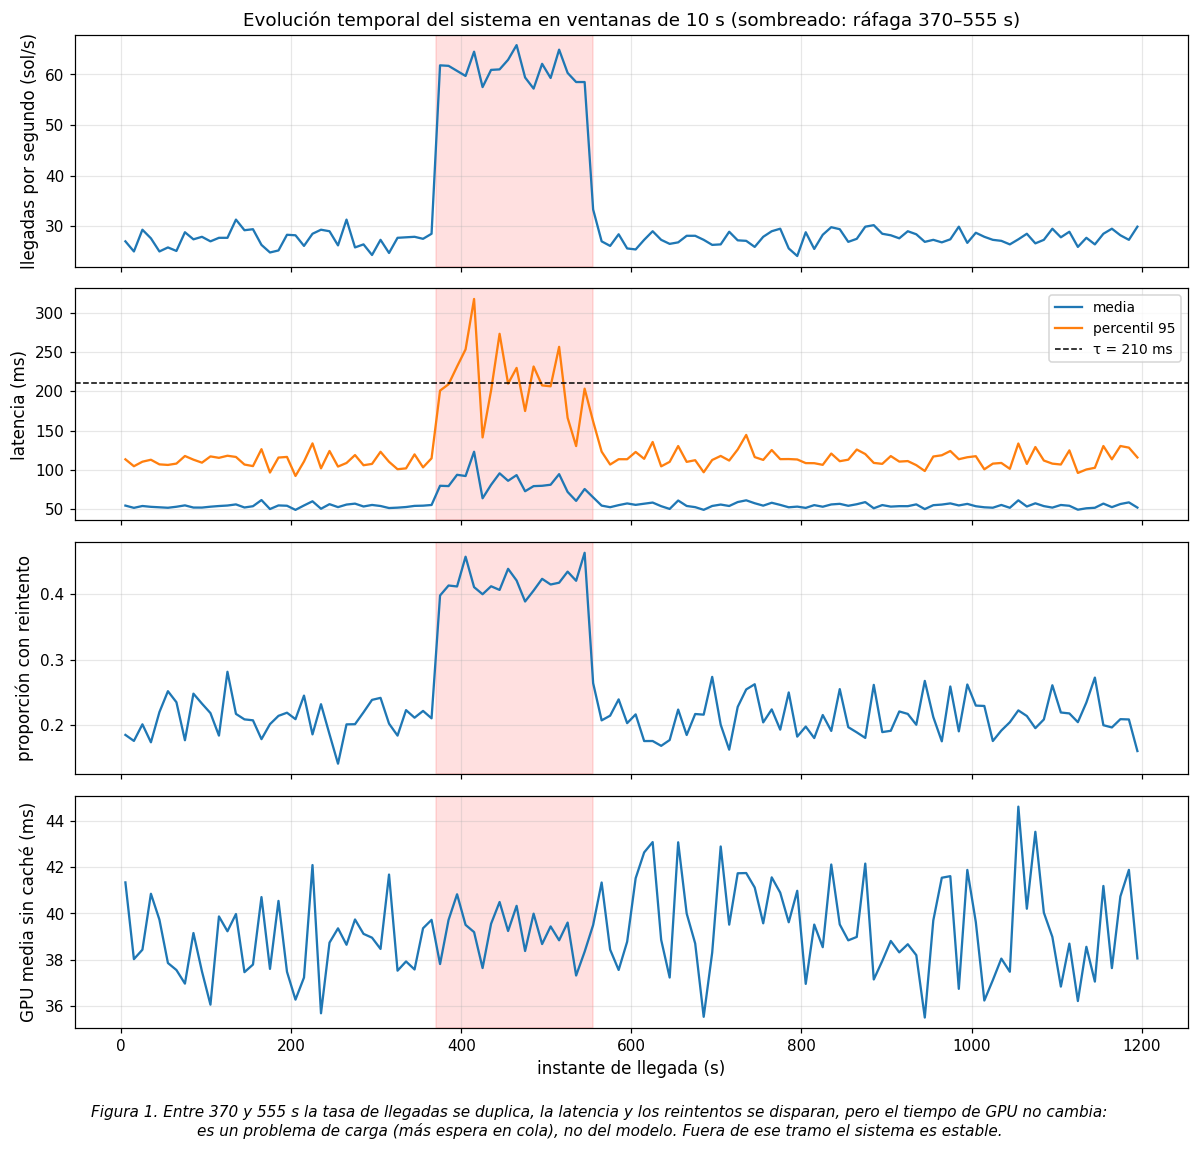

In [ ]:
# =====================================  FIGURA 1  =====================================
bordes = np.arange(0, T_VENTANA + 10, 10)
ventana = pd.cut(d_a2.t_llegada_s, bordes, right=False)
centro = bordes[:-1] + 5
agr = d_a2.groupby(ventana, observed=False)
serie = pd.DataFrame({"tasa": agr.size().values / 10, "lat_media": agr.latencia_ms.mean().values,
                      "lat_p95": agr.latencia_ms.quantile(0.95).values, "reint": agr.intentos.apply(lambda s: (s > 1).mean()).values,
                      "gpu": d_a2[d_a2.cache_hit == 0].groupby(pd.cut(d_a2[d_a2.cache_hit == 0].t_llegada_s, bordes, right=False), observed=False).gpu_ms.mean().values})

fig, ax = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
paneles = [("tasa", "llegadas por segundo (sol/s)", None), ("lat_media", "latencia (ms)", "lat_p95"),
           ("reint", "proporción con reintento", None), ("gpu", "GPU media sin caché (ms)", None)]
for a, (col, etiqueta, extra) in zip(ax, paneles):
    a.plot(centro, serie[col], color="#1f77b4", label="media" if extra else None)
    if extra:
        a.plot(centro, serie[extra], color="#ff7f0e", label="percentil 95")
        a.axhline(tau, color="k", ls="--", lw=1, label=f"τ = {tau} ms")
        a.legend(loc="upper right")
    a.axvspan(INI, FIN, color="red", alpha=0.12)
    a.set_ylabel(etiqueta)
ax[0].set_title("Evolución temporal del sistema en ventanas de 10 s (sombreado: ráfaga 370–555 s)")
ax[-1].set_xlabel("instante de llegada (s)")
pie_de_figura(fig, 1, "Entre 370 y 555 s la tasa de llegadas se duplica, la latencia y los reintentos se disparan, pero el tiempo de GPU no cambia:\n"
                      "es un problema de carga (más espera en cola), no del modelo. Fuera de ese tramo el sistema es estable.")
plt.tight_layout()
guardar_figura(fig, 1)
plt.show()

**Conclusión A3.** En el régimen estable la latencia tiene media ≈ 55 ms y mediana ≈ 49 ms; la media mayor que la mediana, la asimetría positiva (≈ 1,5) y la curtosis alta indican una cola derecha pesada. `gpu_ms` (sin caché) y `tam_kb` tienen la misma forma, mientras que `red_ms` es simétrica (asimetría y curtosis ≈ 0), como una normal. En la ráfaga la latencia media sube más de 50 % y la espera en cola se multiplica, pero GPU, red y tamaño casi no cambian. La versión B usa ≈ 6 % menos GPU que la A (descriptivo; se prueba en F3). **Aporta a P1.**

---
# Parte B — Llegadas, fallos y reintentos (14 pts)
### B1. Proceso de llegadas
**Modelo.** Si las solicitudes llegan de forma independiente y con tasa constante $\lambda$, el proceso es de **Poisson** (semana 9):
- los **conteos** en un intervalo de $\Delta$ segundos son $N(\Delta) \sim \text{Poisson}(\lambda\Delta)$, con $E[N] = \text{Var}(N) = \lambda\Delta$;
- los **tiempos entre llegadas** son independientes y $X \sim \text{Exponencial}(\lambda)$ (semana 10), con $F(x) = 1 - e^{-\lambda x}$, $E[X] = 1/\lambda$ y $\text{DE}(X) = 1/\lambda$.

**Estimación.** Con $n$ llegadas en $T$ segundos, la verosimilitud de los tiempos entre llegadas es $L(\lambda) = \lambda^n e^{-\lambda \sum x_i}$; al derivar $\ln L$ e igualar a 0 se obtiene $\hat\lambda = n/\sum x_i = n/T$. Como $n$ es un conteo Poisson de media $\lambda T$, $\text{Var}(\hat\lambda) = \lambda/T$ y, por el TLC, el intervalo es $\hat\lambda \pm z\sqrt{\hat\lambda/T}$.

In [ ]:
# Paso 1. Datos del régimen estable: tiempos entre llegadas (dentro de cada tramo, sin cruzar la ráfaga) y conteos por segundo
TRAMOS = [(0, INI), (FIN, T_VENTANA)]
t_est = df_estable.t_llegada_s.to_numpy()
X_ent = np.concatenate([np.diff(np.sort(t_est[(t_est >= a) & (t_est < b)])) for a, b in TRAMOS])     # segundos
conteo_1s = np.concatenate([np.histogram(t_est[(t_est >= a) & (t_est < b)], np.arange(a, b + 1e-9, 1))[0] for a, b in TRAMOS])
n_lleg = len(df_estable)

# Paso 2. Estimación de lambda (máxima verosimilitud) e intervalo por el TLC
lam_hat = n_lleg / T_EST
lam_li, lam_ls = ic_normal(lam_hat, np.sqrt(lam_hat / T_EST))
print(f"n = {n_lleg} llegadas en T = {T_EST:.0f} s")
print("lambda (sol/s):", texto_ic(lam_hat, lam_li, lam_ls, "TLC sobre el conteo Poisson"))
print(f"Tiempo medio entre llegadas: 1/lambda = {1000 / lam_hat:.2f} ms [{1000 / lam_ls:.2f}; {1000 / lam_li:.2f}]")

n = 27970 llegadas en T = 1015 s
lambda (sol/s): 27.557  [27.286; 27.828]  (IC 90%, TLC sobre el conteo Poisson)
Tiempo medio entre llegadas: 1/lambda = 36.29 ms [35.94; 36.65]


**Paso 3. Validación por dos vías distintas** (una para cada parte del modelo). En cada una se mide una discrepancia entre datos y modelo y se calcula por **Montecarlo** qué tan frecuente es una discrepancia así **si el modelo fuera cierto**: se simulan muchas muestras del mismo tamaño con $\hat\lambda$, se vuelve a estimar $\lambda$ en cada una y se recalcula la discrepancia. Si la observada es típica, el modelo se acepta.
- **Vía 1, tiempos entre llegadas:** (a) en la exponencial la media es igual a la desviación estándar, así que el coeficiente de variación debe ser ≈ 1; (b) la **falta de memoria**, $P(X > s + t \mid X > s) = P(X > t)$; (c) la distancia máxima $D$ entre la función de distribución empírica y la exponencial.
- **Vía 2, conteos por segundo:** (a) en la Poisson la varianza es igual a la media; (b) las frecuencias observadas de 0, 1, 2, … llegadas por segundo frente a las que predice la Poisson, resumidas en $Q = \sum_k (O_k - E_k)^2/E_k$.

In [ ]:
# Paso 3a. Vía 1: tiempos entre llegadas contra la Exponencial(lambda)
def distancia_exponencial(x):
    """Distancia máxima entre la función de distribución empírica de x y la exponencial con lambda = 1/media."""
    x = np.sort(x)
    F = 1 - np.exp(-x / x.mean())
    n_ = len(x)
    return np.max(np.maximum(np.arange(1, n_ + 1) / n_ - F, F - np.arange(n_) / n_))

cv = X_ent.std(ddof=1) / X_ent.mean()
s_ = t_ = X_ent.mean()                                         # falta de memoria con s = t = tiempo medio
p_cond = (X_ent > s_ + t_).sum() / (X_ent > s_).sum()
D_obs = distancia_exponencial(X_ent)
R_B1 = 500
D_sim = [distancia_exponencial(rng.exponential(1 / lam_hat, len(X_ent))) for _ in range(R_B1)]
corr_1 = np.corrcoef(X_ent[:-1], X_ent[1:])[0, 1]               # independencia entre tiempos consecutivos
print(f"Coeficiente de variación = {cv:.3f} (exponencial: 1)")
print(f"Falta de memoria: P(X > s+t | X > s) = {p_cond:.4f} vs P(X > t) = {(X_ent > t_).mean():.4f} vs modelo e^(-1) = {np.exp(-1):.4f}")
print(f"Distancia máxima a la exponencial D = {D_obs:.4f}; en {R_B1} muestras simuladas del modelo, D >= observado en "
      f"{100 * prob_montecarlo(D_obs, D_sim):.1f} % de los casos")
print(f"Correlación entre tiempos consecutivos = {corr_1:.4f} (independencia: ≈ 0)")

Coeficiente de variación = 1.004 (exponencial: 1)
Falta de memoria: P(X > s+t | X > s) = 0.3746 vs P(X > t) = 0.3656 vs modelo e^(-1) = 0.3679
Distancia máxima a la exponencial D = 0.0054; en 500 muestras simuladas del modelo, D >= observado en 15.0 % de los casos
Correlación entre tiempos consecutivos = -0.0040 (independencia: ≈ 0)


In [ ]:
# Paso 3b. Vía 2: conteos por segundo contra la Poisson(lambda · 1 s)
def discrepancia_poisson(c):
    """Q = sum (O - E)^2 / E sobre los valores con E >= 5, con la Poisson de media igual a la media de c."""
    m = c.mean()
    ks = np.arange(c.min(), c.max() + 1)
    O = np.array([(c == k).sum() for k in ks])
    E = len(c) * stats.poisson.pmf(ks, m)
    ok = E >= 5
    return np.sum((O[ok] - E[ok]) ** 2 / E[ok]), ks, O, E

Q_obs, ks, O, E = discrepancia_poisson(conteo_1s)
Q_sim = [discrepancia_poisson(rng.poisson(lam_hat, len(conteo_1s)))[0] for _ in range(2000)]
coc_1s = conteo_1s.var(ddof=1) / conteo_1s.mean()
coc_sim = [x.var(ddof=1) / x.mean() for x in rng.poisson(lam_hat, size=(2000, len(conteo_1s)))]
print(f"{len(conteo_1s)} segundos | media = {conteo_1s.mean():.2f}, varianza = {conteo_1s.var(ddof=1):.2f}, cociente = {coc_1s:.3f}")
print(f"  fracción de réplicas Poisson con cociente >= observado: {prob_montecarlo(coc_1s, coc_sim):.3f}")
print(f"Discrepancia de frecuencias Q = {Q_obs:.1f}; fracción de réplicas Poisson con Q >= observado: {prob_montecarlo(Q_obs, Q_sim):.3f}")
tabla_B1 = pd.DataFrame({"llegadas en 1 s": ks, "observado": O, "esperado Poisson": E.round(1)})
print(tabla_B1[(tabla_B1["esperado Poisson"] >= 5)].iloc[::3].to_string(index=False))

1015 segundos | media = 27.56, varianza = 27.51, cociente = 0.998
  fracción de réplicas Poisson con cociente >= observado: 0.496
Discrepancia de frecuencias Q = 29.1; fracción de réplicas Poisson con Q >= observado: 0.192
 llegadas en 1 s  observado  esperado Poisson
              16          7               5.8
              19         24              20.8
              22         48              47.1
              25         87              71.4
              28         81              76.0
              31         50              59.0
              34         29              34.4
              37         22              15.4
              40          5               5.4


**Conclusión B1.** En el régimen estable las llegadas son un **proceso de Poisson** con $\hat\lambda \approx 27{,}6$ solicitudes/s (IC 90 % por el TLC). Las dos vías lo respaldan: los tiempos entre llegadas tienen coeficiente de variación ≈ 1, cumplen la falta de memoria y su distancia a la exponencial es típica de lo que produce el propio modelo; los conteos por segundo tienen varianza ≈ media y frecuencias como las de la Poisson. Las discrepancias observadas aparecen con frecuencia en las réplicas del modelo, así que el modelo las explica. Este λ alimenta B4 y la simulación de la Parte G. **Aporta a P1 y P3.**

---
### B2. Bloques de 100 solicitudes
**Modelo.** Sea $Y_j$ el número de solicitudes de un bloque de 100 consecutivas que necesitaron más de un intento. Si cada solicitud necesita reintento de forma independiente y con la misma probabilidad $p$, cada una es un ensayo de **Bernoulli** y $Y_j \sim \text{Binomial}(100, p)$ (semanas 7–8), con $E[Y] = 100p$ y $\text{Var}(Y) = 100p(1-p)$. Se ajusta un modelo por régimen. El estimador es la proporción global $\hat p = \sum Y_j / (100K)$, con intervalo $\hat p \pm z\sqrt{\hat p(1-\hat p)/(100K)}$.

In [ ]:
# Paso 1. Bloques de 100 solicitudes consecutivas dentro de cada tramo de cada régimen
def bloques(d, tramos):
    Y, t0 = [], []
    for a, b in tramos:
        s_ = d[(d.t_llegada_s >= a) & (d.t_llegada_s < b)].sort_values("t_llegada_s")
        k = len(s_) // 100
        r_ = (s_.intentos.to_numpy()[:100 * k] > 1).reshape(k, 100)
        Y.extend(r_.sum(axis=1)); t0.extend(s_.t_llegada_s.to_numpy()[:100 * k:100])
    return np.array(Y), np.array(t0)

Y_est, t0_est = bloques(df_estable, TRAMOS)
Y_raf, t0_raf = bloques(df_rafaga, [(INI, FIN)])
modelos_B2 = {}
for nombre, Y in [("estable", Y_est), ("ráfaga", Y_raf)]:
    K = len(Y)
    p_ = Y.sum() / (100 * K)
    li, ls = ic_proporcion(Y.sum(), 100 * K)
    modelos_B2[nombre] = p_
    print(f"{nombre:8s}: K = {K} bloques | p = {texto_ic(p_, li, ls, 'TLC')} | media de Y = {Y.mean():.2f}")

estable : K = 279 bloques | p = 0.211  [0.207; 0.215]  (IC 90%, TLC) | media de Y = 21.14
ráfaga  : K = 111 bloques | p = 0.418  [0.410; 0.426]  (IC 90%, TLC) | media de Y = 41.81


**Paso 2. Validación dentro de cada régimen** (dos criterios, calibrados por Montecarlo con bloques simulados de la binomial): (a) la varianza observada de $Y$ frente a la binomial, $100\hat p(1-\hat p)$; (b) las frecuencias observadas de $Y$ frente a las de la binomial. **Paso 3. Contraste entre regímenes:** se compara $p$ entre regímenes con el intervalo de la diferencia, y se mide qué tan bien predice el modelo del régimen estable los bloques de la ráfaga.

In [ ]:
# Paso 2. Validación de la Binomial(100, p) en cada régimen
def discrepancia_binomial(Y, p_):
    ks = np.arange(101)
    O = np.array([(Y == k).sum() for k in ks]); E = len(Y) * stats.binom.pmf(ks, 100, p_)
    ok = E >= 5
    return np.sum((O[ok] - E[ok]) ** 2 / E[ok])

for nombre, Y in [("estable", Y_est), ("ráfaga", Y_raf)]:
    p_ = modelos_B2[nombre]
    coc = Y.var(ddof=1) / (100 * p_ * (1 - p_))
    sims = rng.binomial(100, p_, size=(5000, len(Y)))
    coc_sim = sims.var(axis=1, ddof=1) / (100 * sims.mean(axis=1) / 100 * (1 - sims.mean(axis=1) / 100))
    Qb = discrepancia_binomial(Y, p_)
    Qb_sim = [discrepancia_binomial(s, s.mean() / 100) for s in sims[:2000]]
    print(f"{nombre:8s}: varianza observada / binomial = {coc:.3f} (réplicas con cociente >= observado: {prob_montecarlo(coc, coc_sim):.3f}) | "
          f"discrepancia de frecuencias Q = {Qb:.1f} (réplicas con Q >= observado: {prob_montecarlo(Qb, Qb_sim):.3f})")

# Paso 3. Contraste entre regímenes
dif, ee = ic_dif_proporciones(Y_raf.sum(), 100 * len(Y_raf), Y_est.sum(), 100 * len(Y_est))
li, ls = ic_normal(dif, ee)
q999 = stats.binom.ppf(0.999, 100, modelos_B2["estable"])
print(f"\np(ráfaga) - p(estable) = {texto_ic(dif, li, ls, 'TLC, diferencia de proporciones')} -> cociente {modelos_B2['ráfaga'] / modelos_B2['estable']:.2f}")
print(f"Modelo estable: media esperada por bloque = {100 * modelos_B2['estable']:.1f}; en la ráfaga se observan {Y_raf.mean():.1f}")
print(f"Percentil 99,9 % de la Binomial(100, p estable) = {q999:.0f}: lo supera el {100 * (Y_raf > q999).mean():.0f} % de los bloques de la ráfaga "
      f"(y el {100 * (Y_est > q999).mean():.1f} % de los del régimen estable)")

estable : varianza observada / binomial = 1.039 (réplicas con cociente >= observado: 0.330) | discrepancia de frecuencias Q = 7.1 (réplicas con Q >= observado: 0.911)
ráfaga  : varianza observada / binomial = 1.076 (réplicas con cociente >= observado: 0.258) | discrepancia de frecuencias Q = 6.4 (réplicas con Q >= observado: 0.768)

p(ráfaga) - p(estable) = 0.207  [0.198; 0.215]  (IC 90%, TLC, diferencia de proporciones) -> cociente 1.98
Modelo estable: media esperada por bloque = 21.1; en la ráfaga se observan 41.8
Percentil 99,9 % de la Binomial(100, p estable) = 34: lo supera el 93 % de los bloques de la ráfaga (y el 0.0 % de los del régimen estable)


**Conclusión B2.** Dentro de cada régimen, el número de solicitudes con reintento por bloque se describe bien con una **Binomial(100, p)**: la varianza y las frecuencias observadas son típicas de las que produce el propio modelo. Pero **$p$ cambia con el régimen**: ≈ 0,21 en el estable y ≈ 0,42 en la ráfaga (casi el doble; el intervalo de la diferencia está lejos de 0). El modelo del régimen estable no explica la ráfaga: casi todos sus bloques superan el percentil 99,9 % de la binomial estable. La explicación es la carga: en la ráfaga la tasa se duplica, la cola crece (A3) y fallan más intentos. **Aporta a P1.**

---
### B3. Modelo de la variable `intentos`
**Cómo se generan los datos.** Cada intento falla de forma independiente con probabilidad $q$ (ensayos de Bernoulli) y el SDK abandona tras 3 fallos. Entonces `intentos` es una **geométrica truncada en 3** (semana 9), y la columna `exito` dice si el tercer intento salió bien:
$$P(1, \text{éxito}) = 1-q,\quad P(2, \text{éxito}) = q(1-q),\quad P(3, \text{éxito}) = q^2(1-q),\quad P(3, \text{abandono}) = q^3.$$
**Máxima verosimilitud** (deducción manuscrita en el entregable E3). Si $F$ es el total de intentos fallidos y $S$ el de intentos exitosos, la verosimilitud es $L(q) = q^F(1-q)^S$, así que $\frac{d}{dq}\ln L = \frac{F}{q} - \frac{S}{1-q} = 0 \Rightarrow \hat q = \frac{F}{F+S}$: la proporción de intentos que fallaron. Como $\hat q$ es una proporción sobre $F+S$ intentos de Bernoulli, su intervalo es $\hat q \pm z\sqrt{\hat q(1-\hat q)/(F+S)}$.

**El estimador "inmediato".** Si se ignora el truncamiento, intentos sería una geométrica con $E[I] = 1/(1-q)$ y se estimaría $\tilde q = 1 - 1/\bar I$. Se evalúa por simulación calibrada.

In [ ]:
# Paso 1. Tabla (intentos, éxito), estadísticos F y S, estimación e intervalo
tabla_B3 = pd.crosstab(df_estable.intentos, df_estable.exito)
print(tabla_B3, "\n")
n1 = int(((df_estable.intentos == 1) & (df_estable.exito == 1)).sum())
n2 = int(((df_estable.intentos == 2) & (df_estable.exito == 1)).sum())
n3e = int(((df_estable.intentos == 3) & (df_estable.exito == 1)).sum())
n3f = int(((df_estable.intentos == 3) & (df_estable.exito == 0)).sum())
n_B3 = n1 + n2 + n3e + n3f
F_B3 = n2 * 1 + n3e * 2 + n3f * 3                               # intentos fallidos
S_B3 = n1 + n2 + n3e                                            # intentos exitosos
q_hat = F_B3 / (F_B3 + S_B3)
q_li, q_ls = ic_proporcion(F_B3, F_B3 + S_B3)
q_naive = 1 - 1 / df_estable.intentos.mean()
print(f"F = {F_B3} fallos, S = {S_B3} éxitos -> q (máx. verosimilitud) = {texto_ic(q_hat, q_li, q_ls, 'TLC', 4)}")
print(f"Estimador inmediato 1 - 1/media(intentos) = {q_naive:.4f}")

# Bondad de ajuste: frecuencias observadas vs esperadas de las 4 combinaciones, discrepancia calibrada por Montecarlo
probs = np.array([1 - q_hat, q_hat * (1 - q_hat), q_hat ** 2 * (1 - q_hat), q_hat ** 3])
O3 = np.array([n1, n2, n3e, n3f]); E3 = n_B3 * probs
Q3 = np.sum((O3 - E3) ** 2 / E3)
sim3 = rng.multinomial(n_B3, probs, size=5000)
F_s = sim3[:, 1] + 2 * sim3[:, 2] + 3 * sim3[:, 3]; S_s = sim3[:, 0] + sim3[:, 1] + sim3[:, 2]
q_s = F_s / (F_s + S_s)
E_s = n_B3 * np.column_stack([1 - q_s, q_s * (1 - q_s), q_s ** 2 * (1 - q_s), q_s ** 3])
Q3_sim = ((sim3 - E_s) ** 2 / E_s).sum(axis=1)
print(pd.DataFrame({"(intentos, éxito)": ["(1, sí)", "(2, sí)", "(3, sí)", "(3, no)"], "observado": O3, "esperado": E3.round(1)}).to_string(index=False))
print(f"Discrepancia Q = {Q3:.2f}; réplicas del modelo con Q >= observado: {prob_montecarlo(Q3, Q3_sim):.3f}")

exito       0      1
intentos            
1           0  22062
2           0   4631
3         266   1011 

F = 7451 fallos, S = 27704 éxitos -> q (máx. verosimilitud) = 0.2119  [0.2084; 0.2155]  (IC 90%, TLC)
Estimador inmediato 1 - 1/media(intentos) = 0.2044
(intentos, éxito)  observado  esperado
          (1, sí)      22062   22041.8
          (2, sí)       4631    4671.7
          (3, sí)       1011     990.2
          (3, no)        266     266.3
Discrepancia Q = 0.81; réplicas del modelo con Q >= observado: 0.661


In [ ]:
# Paso 2. Simulación calibrada con q_hat: ¿el estimador inmediato es adecuado?
R_B3 = 20_000
sim = rng.multinomial(n_B3, probs, size=R_B3)                    # cada réplica: n_B3 solicitudes con el q estimado
F_r = sim[:, 1] + 2 * sim[:, 2] + 3 * sim[:, 3]; S_r = sim[:, 0] + sim[:, 1] + sim[:, 2]
I_media = (sim[:, 0] + 2 * sim[:, 1] + 3 * (sim[:, 2] + sim[:, 3])) / n_B3
est = {"máxima verosimilitud F/(F+S)": F_r / (F_r + S_r), "inmediato 1 - 1/media": 1 - 1 / I_media}
ee_q = np.sqrt(q_hat * (1 - q_hat) / (F_B3 + S_B3))
filas = []
for nombre, e in est.items():
    filas.append({"estimador": nombre, "media": e.mean(), "sesgo": e.mean() - q_hat, "desv. est.": e.std(),
                  "ECM (x 10^-6)": 1e6 * np.mean((e - q_hat) ** 2), "cobertura de e ± z·ee": np.mean(np.abs(e - q_hat) <= z * ee_q)})
print(f"q verdadero en la simulación = {q_hat:.4f}, {R_B3} réplicas")
print(pd.DataFrame(filas).round(5).to_string(index=False))

q verdadero en la simulación = 0.2119, 20000 réplicas
                   estimador   media    sesgo  desv. est.  ECM (x 10^-6)  cobertura de e ± z·ee
máxima verosimilitud F/(F+S) 0.21195  0.00001     0.00219        4.78568                0.90185
       inmediato 1 - 1/media 0.20438 -0.00757     0.00201       61.35927                0.02350


**Conclusión B3.** `intentos` sigue una **geométrica truncada en 3** con probabilidad de fallo por intento $\hat q \approx 0{,}21$ (máxima verosimilitud, IC 90 % por el TLC). Las frecuencias de las cuatro combinaciones (intentos, éxito) coinciden con las del modelo. El estimador inmediato $1 - 1/\bar I$ **no es adecuado**: al ignorar el truncamiento (el SDK no deja pasar de 3 intentos), $\bar I$ queda por debajo de $1/(1-q)$ y $\tilde q$ subestima sistemáticamente $q$. En la simulación su sesgo es varias veces su desviación estándar, así que su intervalo casi nunca contiene el valor verdadero, mientras que el de máxima verosimilitud es insesgado y cubre ≈ 90 %. **Aporta a P1.**

---
### B4. Reintentos en una ventana de 10 s
**Modelo y justificación.**
1. Las llegadas son Poisson con tasa $\lambda$ (B1).
2. Cada llegada necesita reintento con probabilidad $p$ de forma independiente (B2), sin importar cuándo llegó.
3. Entonces el número $N_{10}$ de solicitudes con reintento en 10 s es **Poisson con media $\mu = 10\lambda p$** ("adelgazamiento"). Se demuestra con la probabilidad total: dado que llegaron $n$ solicitudes, $N_{10} \mid n \sim \text{Binomial}(n, p)$, y al sumar sobre $n$ con pesos Poisson$(10\lambda)$ queda $P(N_{10} = k) = e^{-\mu}\mu^k/k!$. Con la función generadora de momentos: $M_{N_{10}}(t) = E[(1-p+pe^t)^{n}] = e^{10\lambda(1-p+pe^t-1)} = e^{\mu(e^t-1)}$, que es la de una Poisson$(\mu)$.

Con $\hat\mu = 10\hat\lambda\hat p$ y $k = \lceil\hat\mu\rceil + r$, se calcula $P(N_{10} \ge k) = 1 - \sum_{j=0}^{k-1} e^{-\hat\mu}\hat\mu^j/j!$ y se verifica por **Montecarlo** simulando el mecanismo completo (llegadas y reintentos), sin usar la fórmula.

In [ ]:
# Paso 1. mu y k; Paso 2. probabilidad analítica; Paso 3. Montecarlo del mecanismo completo
p_reint = (df_estable.intentos > 1).mean()
mu_hat = 10 * lam_hat * p_reint
k_B4 = int(np.ceil(mu_hat)) + r
P_analitica = 1 - stats.poisson.cdf(k_B4 - 1, mu_hat)
print(f"lambda = {lam_hat:.3f} sol/s, p = {p_reint:.4f} -> mu = 10·lambda·p = {mu_hat:.2f}; r = {r} -> k = {k_B4}")
print(f"Analítica: P(N_10 >= {k_B4}) = {P_analitica:.4f}")

R_B4 = 200_000
llegadas = rng.poisson(10 * lam_hat, R_B4)                       # paso 1 del mecanismo: llegadas en 10 s
N10_sim = rng.binomial(llegadas, p_reint)                       # paso 2: cada llegada necesita reintento con prob. p
P_mc = np.mean(N10_sim >= k_B4)
li, ls = ic_proporcion(int(np.sum(N10_sim >= k_B4)), R_B4)
print(f"Montecarlo ({R_B4} ventanas): P = {texto_ic(P_mc, li, ls, 'TLC', 4)}")
print(f"Media y varianza simuladas de N_10: {N10_sim.mean():.2f} y {N10_sim.var():.2f} (Poisson: ambas = mu = {mu_hat:.2f})")

# Contraste con los datos: ventanas reales de 10 s del régimen estable
N10_obs = np.concatenate([np.histogram(df_estable[(df_estable.t_llegada_s >= a) & (df_estable.t_llegada_s < b) & (df_estable.intentos > 1)].t_llegada_s,
                                       np.arange(a, b + 1e-9, 10))[0] for a, b in TRAMOS])
print(f"Datos: {len(N10_obs)} ventanas reales de 10 s, fracción con N_10 >= k = {np.mean(N10_obs >= k_B4):.3f} "
      f"(media {N10_obs.mean():.2f}, varianza {N10_obs.var(ddof=1):.2f})")

lambda = 27.557 sol/s, p = 0.2112 -> mu = 10·lambda·p = 58.21; r = 0 -> k = 59
Analítica: P(N_10 >= 59) = 0.4760
Montecarlo (200000 ventanas): P = 0.4747  [0.4729; 0.4766]  (IC 90%, TLC)
Media y varianza simuladas de N_10: 58.20 y 57.99 (Poisson: ambas = mu = 58.21)
Datos: 101 ventanas reales de 10 s, fracción con N_10 >= k = 0.505 (media 58.18, varianza 64.91)


**Conclusión B4.** Por el adelgazamiento del proceso de Poisson, las solicitudes que requieren más de un intento en 10 s forman una Poisson con media $\hat\mu = 10\hat\lambda\hat p \approx 58$. Con $k = \lceil\hat\mu\rceil + r$, la probabilidad analítica de al menos $k$ reintentos y la de Montecarlo (que simula llegadas y reintentos sin usar la fórmula) coinciden dentro del error de simulación, y las ventanas reales de 10 s dan una fracción parecida. Como $k$ está justo encima de la media, la probabilidad es cercana a 1/2. **Aporta a P1.**

---
# Parte C — Tiempo de cómputo y tiempo de red (14 pts)
### C1. Naturaleza de G y su función de distribución
**G es una variable aleatoria mixta** (semana 5). Si hubo caché, la GPU no trabaja y $G = 0$ exactamente: hay una **masa puntual** en 0 con probabilidad $c = P(\text{caché})$. Si no hubo caché, $G = X > 0$ es un tiempo **continuo** con función de distribución $F_X$. Por probabilidad total (deducción manuscrita en E3):
$$F_G(x) = P(G \le x) = \begin{cases} 0 & x < 0 \\ c + (1-c)\,F_X(x) & x \ge 0 \end{cases}$$
La función salta $c$ en $x = 0$ (parte discreta) y después crece de forma continua. Con $m = E[X]$ y $v = \text{Var}(X)$:
$$E[G] = c\cdot 0 + (1-c)\,m = (1-c)\,m, \qquad E[G^2] = (1-c)(v + m^2),$$
$$\text{Var}(G) = E[G^2] - E[G]^2 = (1-c)\,v + c\,(1-c)\,m^2.$$
El segundo término aparece por la mezcla: aunque todas las solicitudes con GPU tardaran lo mismo ($v = 0$), $G$ variaría porque a veces vale 0.

In [ ]:
# Paso 1. Evidencia de la naturaleza mixta y parámetros c, m, v
G = df_estable.gpu_ms.to_numpy()
X_gpu = G[df_estable.cache_hit.to_numpy() == 0]                  # parte continua: solicitudes sin caché
c_hat = (G == 0).mean()
m_hat, v_hat = X_gpu.mean(), X_gpu.var(ddof=1)
print(f"P(G = 0) = {c_hat:.4f} (coincide con la proporción de caché {df_estable.cache_hit.mean():.4f})")
print(f"Valores distintos entre las {len(X_gpu)} no cacheadas: {len(np.unique(X_gpu))} | mínimo = {X_gpu.min():.2f} ms > 0 -> parte continua")

# Paso 2. Momentos teóricos (fórmulas) frente a muestrales, con intervalo para la media muestral
EG_teo = (1 - c_hat) * m_hat
VarG_teo = (1 - c_hat) * v_hat + c_hat * (1 - c_hat) * m_hat ** 2
li, ls = ic_normal(G.mean(), G.std(ddof=1) / np.sqrt(len(G)))
print(f"E[G]:   fórmula (1-c)m = {EG_teo:.3f} ms | muestral = {texto_ic(G.mean(), li, ls, 'TLC')}")
print(f"Var(G): fórmula (1-c)v + c(1-c)m² = {VarG_teo:.1f} ms² | muestral = {G.var(ddof=1):.1f} ms²")
print(f"  de los cuales: (1-c)v = {(1 - c_hat) * v_hat:.1f} (variación de la GPU) y c(1-c)m² = {c_hat * (1 - c_hat) * m_hat ** 2:.1f} (efecto de la mezcla)")

# Paso 3. Verificación por Montecarlo: se simula la mezcla (Bernoulli(c) para la caché y X remuestreado)
R_C1 = 1_000_000
cache_sim = rng.random(R_C1) < c_hat
G_sim = np.where(cache_sim, 0.0, rng.choice(X_gpu, R_C1))
print(f"Montecarlo ({R_C1} valores): E[G] = {G_sim.mean():.3f} ms, Var(G) = {G_sim.var():.1f} ms², P(G = 0) = {(G_sim == 0).mean():.4f}")

P(G = 0) = 0.3360 (coincide con la proporción de caché 0.3360)
Valores distintos entre las 18572 no cacheadas: 7238 | mínimo = 2.06 ms > 0 -> parte continua
E[G]:   fórmula (1-c)m = 26.042 ms | muestral = 26.042  [25.766; 26.318]  (IC 90%, TLC)
Var(G): fórmula (1-c)v + c(1-c)m² = 785.4 ms² | muestral = 785.4 ms²
  de los cuales: (1-c)v = 442.3 (variación de la GPU) y c(1-c)m² = 343.2 (efecto de la mezcla)
Montecarlo (1000000 valores): E[G] = 26.092 ms, Var(G) = 787.2 ms², P(G = 0) = 0.3354


---
## FIGURA 2 · Distribución de G (ítem C1)
Izquierda: la masa en 0 (barra) y la densidad de la parte continua. Derecha: la función de distribución de G, con el salto en 0.

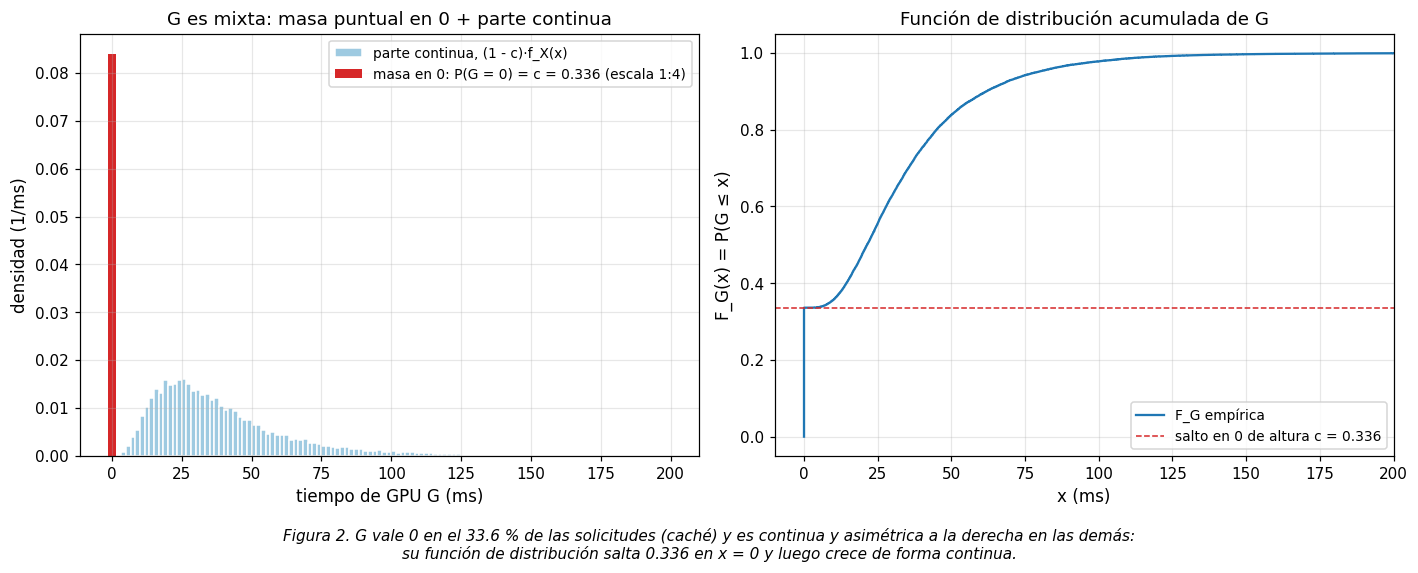

In [ ]:
# =====================================  FIGURA 2  =====================================
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
peso = (1 - c_hat) / len(X_gpu)
ax[0].hist(X_gpu, bins=120, range=(0, 200), weights=np.full(len(X_gpu), peso / (200 / 120)), color="#9ecae1",
           edgecolor="white", label=f"parte continua, (1 - c)·f_X(x)")
ax[0].bar(0, c_hat / 4, width=3, color="#d62728", label=f"masa en 0: P(G = 0) = c = {c_hat:.3f} (escala 1:4)")
ax[0].set_xlabel("tiempo de GPU G (ms)"); ax[0].set_ylabel("densidad (1/ms)")
ax[0].set_title("G es mixta: masa puntual en 0 + parte continua"); ax[0].legend()
xs = np.sort(G)
ax[1].step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", color="#1f77b4", label="F_G empírica")
ax[1].axhline(c_hat, color="#d62728", ls="--", lw=1, label=f"salto en 0 de altura c = {c_hat:.3f}")
ax[1].set_xlim(-10, 200); ax[1].set_xlabel("x (ms)"); ax[1].set_ylabel("F_G(x) = P(G ≤ x)")
ax[1].set_title("Función de distribución acumulada de G"); ax[1].legend(loc="lower right")
pie_de_figura(fig, 2, f"G vale 0 en el {100 * c_hat:.1f} % de las solicitudes (caché) y es continua y asimétrica a la derecha en las demás:\n"
                      f"su función de distribución salta {c_hat:.3f} en x = 0 y luego crece de forma continua.")
plt.tight_layout(); guardar_figura(fig, 2); plt.show()

**Conclusión C1.** $G$ es **mixta**: vale 0 con probabilidad $\hat c \approx 0{,}34$ (caché) y en las demás solicitudes es continua, positiva y asimétrica a la derecha. Las fórmulas $E[G] = (1-c)m$ y $\text{Var}(G) = (1-c)v + c(1-c)m^2$ coinciden con los valores muestrales y con el Montecarlo. Casi la mitad de la varianza de $G$ (343 de 785 ms²) se debe solo a la mezcla (a veces 0, a veces no), no a la variación de la GPU. **Aporta a P1.**

---
### C2. Modelo para la parte continua de G por máxima verosimilitud
**Candidatos.** $X$ = tiempo de GPU de las no cacheadas es positivo y asimétrico a la derecha (A3), así que no sirve una normal. Se ajustan dos modelos:
- **Gamma**$(k, \theta)$ (semana 11): $f(x) = \dfrac{x^{k-1}e^{-x/\theta}}{\Gamma(k)\,\theta^k}$, con $E[X] = k\theta$ y $\text{Var}(X) = k\theta^2$.
- **Lognormal**$(\mu, \sigma)$: $X$ es lognormal si $\ln X \sim N(\mu, \sigma^2)$ (una transformación de la normal, semana 12): $f(x) = \dfrac{1}{x\sigma\sqrt{2\pi}}\exp\!\left(-\dfrac{(\ln x - \mu)^2}{2\sigma^2}\right)$, con $E[X] = e^{\mu+\sigma^2/2}$.

**Máxima verosimilitud implementada por el grupo.** Se escribe la log-verosimilitud $\ell(\theta) = \sum_i \ln f(x_i;\theta)$ y se maximiza numéricamente (minimizando $-\ell$ con `optimize.minimize`):
$$\ell_{\text{gamma}}(k,\theta) = (k-1)\sum\ln x_i - \frac{\sum x_i}{\theta} - n\ln\Gamma(k) - nk\ln\theta,\qquad \ell_{\text{logn}}(\mu,\sigma) = -\sum\ln x_i - n\ln\sigma - \frac{n}{2}\ln 2\pi - \frac{\sum(\ln x_i - \mu)^2}{2\sigma^2}.$$
**Otro método: momentos** (semana 7). Se igualan la media y la varianza del modelo a las muestrales: gamma $\tilde k = m^2/v$, $\tilde\theta = v/m$; lognormal $\tilde\sigma^2 = \ln(1 + v/m^2)$, $\tilde\mu = \ln m - \tilde\sigma^2/2$.

In [ ]:
# Paso 1. Máxima verosimilitud programada por el grupo (log-verosimilitud + optimización numérica)
from scipy.special import gammaln                                # ln Γ(k): solo la función gamma, no un ajuste automático
lx, n_x = np.log(X_gpu), len(X_gpu)

def menos_loglik_gamma(par):
    k, theta = np.exp(par)                                      # se optimiza en logaritmos para que k, theta > 0
    return -((k - 1) * lx.sum() - X_gpu.sum() / theta - n_x * gammaln(k) - n_x * k * np.log(theta))

def menos_loglik_lognormal(par):
    mu, sigma = par[0], np.exp(par[1])
    return -(-lx.sum() - n_x * np.log(sigma) - n_x / 2 * np.log(2 * np.pi) - ((lx - mu) ** 2).sum() / (2 * sigma ** 2))

opt_g = optimize.minimize(menos_loglik_gamma, x0=np.log([2.0, 20.0]), method="Nelder-Mead", options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 5000})
opt_l = optimize.minimize(menos_loglik_lognormal, x0=[3.0, np.log(0.5)], method="Nelder-Mead", options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 5000})
k_mv, th_mv = np.exp(opt_g.x)
mu_mv, sig_mv = opt_l.x[0], np.exp(opt_l.x[1])
print(f"Gamma (máx. verosimilitud):     k = {k_mv:.4f}, theta = {th_mv:.4f} ms | log-verosimilitud = {-opt_g.fun:.1f}")
print(f"Lognormal (máx. verosimilitud): mu = {mu_mv:.4f}, sigma = {sig_mv:.4f} | log-verosimilitud = {-opt_l.fun:.1f}")
print(f"  comprobación lognormal: el máximo exacto es mu = media(ln x) = {lx.mean():.4f}, sigma = DE(ln x) = {lx.std():.4f}")

# Paso 2. Método de momentos
k_mm, th_mm = m_hat ** 2 / v_hat, v_hat / m_hat
s2_mm = np.log(1 + v_hat / m_hat ** 2); mu_mm, sig_mm = np.log(m_hat) - s2_mm / 2, np.sqrt(s2_mm)
print(f"\nGamma (momentos):     k = {k_mm:.4f}, theta = {th_mm:.4f}")
print(f"Lognormal (momentos): mu = {mu_mm:.4f}, sigma = {sig_mm:.4f}")

Gamma (máx. verosimilitud):     k = 2.8077, theta = 13.9685 ms | log-verosimilitud = -82502.3
Lognormal (máx. verosimilitud): mu = 3.4807, sigma = 0.6212 | log-verosimilitud = -82153.1
  comprobación lognormal: el máximo exacto es mu = media(ln x) = 3.4807, sigma = DE(ln x) = 0.6212

Gamma (momentos):     k = 2.3095, theta = 16.9823
Lognormal (momentos): mu = 3.4893, sigma = 0.5998


**Paso 3. Bondad de ajuste.** (a) Log-verosimilitud máxima: los dos modelos tienen 2 parámetros, así que el de mayor log-verosimilitud explica mejor los datos. (b) Cuantiles del modelo frente a los empíricos, sobre todo en la cola. (c) Distancia máxima $D$ entre la función de distribución empírica y la del modelo, calibrada por Montecarlo (muestras simuladas del propio modelo, reajustadas). (d) Gráfica de apoyo: cuantil-cuantil.

In [ ]:
# Paso 3. Bondad de ajuste de los cuatro ajustes
modelos_C2 = {"gamma (máx. ver.)": stats.gamma(k_mv, scale=th_mv), "gamma (momentos)": stats.gamma(k_mm, scale=th_mm),
              "lognormal (máx. ver.)": stats.lognorm(sig_mv, scale=np.exp(mu_mv)), "lognormal (momentos)": stats.lognorm(sig_mm, scale=np.exp(mu_mm))}
def distancia_max(x_ordenado, cdf):
    n_ = len(x_ordenado); F = cdf(x_ordenado)
    return np.max(np.maximum(np.arange(1, n_ + 1) / n_ - F, F - np.arange(n_) / n_))
xs_ord = np.sort(X_gpu)
Q_C2 = [0.5, 0.9, 0.99, 0.999]
filas = [{"modelo": "datos", **{f"q{100 * q:g}": np.quantile(X_gpu, q) for q in Q_C2}, "D": 0.0, "log-ver.": np.nan}]
for nombre, mod in modelos_C2.items():
    filas.append({"modelo": nombre, **{f"q{100 * q:g}": mod.ppf(q) for q in Q_C2}, "D": distancia_max(xs_ord, mod.cdf),
                  "log-ver.": mod.logpdf(X_gpu).sum()})
print(pd.DataFrame(filas).round(3).to_string(index=False))

# Calibración por Montecarlo de D para el mejor modelo (lognormal por máxima verosimilitud)
D_logn = distancia_max(xs_ord, modelos_C2["lognormal (máx. ver.)"].cdf)
D_sim = []
for _ in range(300):
    xsim = np.sort(rng.lognormal(mu_mv, sig_mv, n_x))
    D_sim.append(distancia_max(xsim, stats.lognorm(np.log(xsim).std(), scale=np.exp(np.log(xsim).mean())).cdf))
print(f"\nLognormal: D = {D_logn:.4f}; en 300 muestras simuladas del modelo, D >= observado en {100 * prob_montecarlo(D_logn, D_sim):.1f} %")

               modelo    q50    q90     q99   q99.9     D   log-ver.
                datos 32.900 71.799 128.803 202.313 0.000        NaN
    gamma (máx. ver.) 34.675 70.596 112.842 151.706 0.037 -82502.260
     gamma (momentos) 33.727 73.769 122.342 167.690 0.048 -82689.017
lognormal (máx. ver.) 32.481 72.007 137.797 221.475 0.009 -82153.138
 lognormal (momentos) 32.763 70.667 132.246 209.108 0.013 -82178.406

Lognormal: D = 0.0090; en 300 muestras simuladas del modelo, D >= observado en 0.3 %


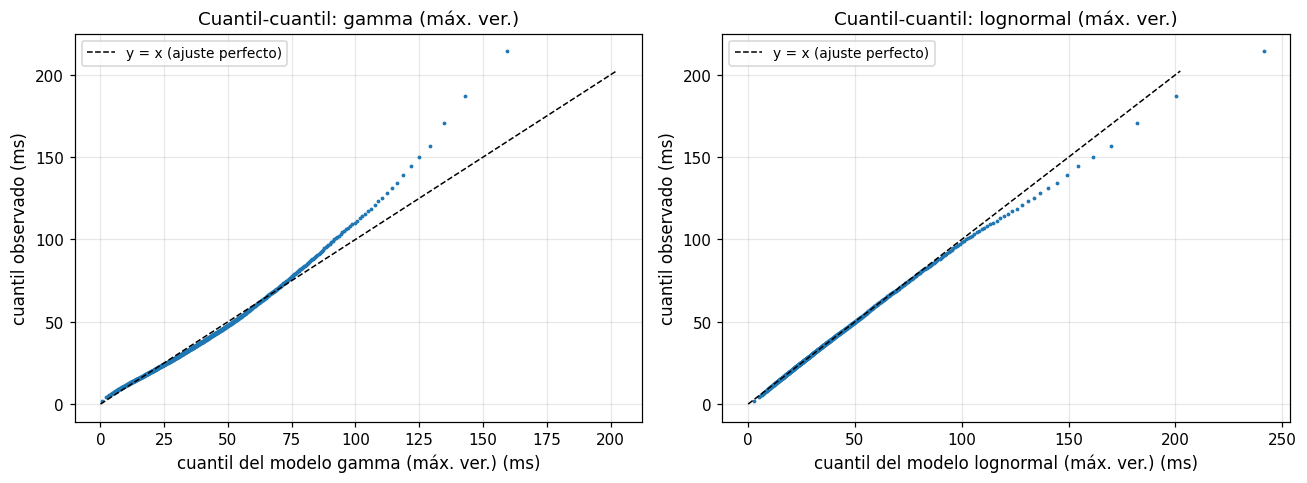

In [ ]:
# Gráfica de apoyo C2 (no numerada): cuantil-cuantil de los dos modelos de máxima verosimilitud
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
pp = (np.arange(1, n_x + 1) - 0.5) / n_x
for a, nombre in zip(ax, ["gamma (máx. ver.)", "lognormal (máx. ver.)"]):
    a.plot(modelos_C2[nombre].ppf(pp)[::20], xs_ord[::20], ".", ms=3)
    lim = [0, np.quantile(X_gpu, 0.999)]
    a.plot(lim, lim, "k--", lw=1, label="y = x (ajuste perfecto)")
    a.set_xlabel(f"cuantil del modelo {nombre} (ms)"); a.set_ylabel("cuantil observado (ms)"); a.set_title(f"Cuantil-cuantil: {nombre}"); a.legend()
plt.tight_layout(); plt.show()

**Paso 4. ¿Es adecuado un modelo marginal?** El sistema dice que el tiempo de GPU depende del **tamaño de la imagen** y de la **versión** del modelo. Una distribución única para todas las solicitudes mezcla imágenes pequeñas y grandes; por eso es tan asimétrica. Se mira cómo cambia $X$ por clase de tamaño.

In [ ]:
# Paso 4. Estructura condicional: el tiempo de GPU depende del tamaño (y la versión)
nc = df_estable[df_estable.cache_hit == 0].copy()
nc["clase"] = pd.cut(nc.tam_kb, [-np.inf, t1_kb, t2_kb, np.inf], right=False, labels=["pequeña", "mediana", "grande"])
print(nc.groupby(["clase", "version"], observed=True).gpu_ms.agg(["count", "mean", "std"]).round(2).to_string())
cv_clase = nc.groupby("clase", observed=True).gpu_ms.agg(lambda s: s.std() / s.mean())
print("\nCoeficiente de variación dentro de cada clase:", cv_clase.round(3).to_dict(), f"| global: {X_gpu.std() / X_gpu.mean():.3f}")

                 count   mean    std
clase   version                     
pequeña A         1103  20.11   9.21
        B         1075  18.36   8.36
mediana A         6741  36.70  19.29
        B         6555  34.23  17.68
grande  A         1552  70.84  36.34
        B         1546  67.79  33.23

Coeficiente de variación dentro de cada clase: {'pequeña': 0.459, 'mediana': 0.523, 'grande': 0.503} | global: 0.658


**Conclusión C2.** Entre los modelos ajustados por máxima verosimilitud propia, la **lognormal** es claramente mejor que la gamma: tiene mayor log-verosimilitud (≈ 350 unidades más con el mismo número de parámetros), su función de distribución se separa de la empírica a lo sumo 0,9 puntos porcentuales (la gamma, 3,7) y reproduce la cola, mientras que la gamma la subestima mucho (percentil 99,9 % de 152 ms frente a 202 ms observados). Los estimadores de momentos dan valores parecidos pero ajustan peor. **Pero la lognormal tampoco es exacta:** con 18 572 datos hasta una diferencia de 0,9 puntos es mayor que la que produce el propio modelo (solo el 0,3 % de las réplicas de Montecarlo la alcanzan), y en el extremo sobreestima la cola (221 frente a 202 ms). **Crítica:** el modelo marginal es una simplificación. El tiempo de GPU depende del tamaño (las imágenes grandes tardan ≈ 3,5 veces más que las pequeñas) y de la versión, así que la distribución marginal es una **mezcla** de subpoblaciones; ninguna distribución de dos parámetros la describe del todo. Para simular el sistema (Parte G) se usa el modelo condicional de D3, $X = (\beta_0 + \beta_1\,\text{tam})\cdot\varepsilon$. **Aporta a P1.**

---
### C3. ¿`red_ms` admite un modelo normal?
Tres criterios cuantitativos (semana 12), cada uno calibrado por Montecarlo con muestras normales del mismo tamaño:
1. **Sesgo y curtosis:** en una normal ambos valen 0.
2. **Regla empírica:** una normal tiene 68,27 %, 95,45 % y 99,73 % de los datos a menos de 1, 2 y 3 desviaciones estándar de la media.
3. **Cuantiles:** el gráfico cuantil-cuantil (Figura 3) y la cola.

In [ ]:
# Paso 1. Estimación y criterios de normalidad
red = df_estable.red_ms.to_numpy()
mu_r, sig_r = red.mean(), red.std(ddof=1)
n_r = len(red)
sim_norm = rng.normal(mu_r, sig_r, size=(1000, n_r))
sesgo_sim, curt_sim = stats.skew(sim_norm, axis=1), stats.kurtosis(sim_norm, axis=1)
print(f"red ~ N(mu = {mu_r:.3f}, sigma = {sig_r:.3f}) con n = {n_r}")
print(f"1. Sesgo = {stats.skew(red):.4f} (en normales de este tamaño: 99 % entre {np.quantile(sesgo_sim, .005):.4f} y {np.quantile(sesgo_sim, .995):.4f})")
print(f"   Curtosis exc. = {stats.kurtosis(red):.4f} (99 % entre {np.quantile(curt_sim, .005):.4f} y {np.quantile(curt_sim, .995):.4f})")
zr = np.abs(red - mu_r) / sig_r
print("2. Regla empírica (dentro de k desviaciones):")
for k, teo in [(1, 0.6827), (2, 0.9545), (3, 0.9973)]:
    li, ls = ic_proporcion(int((zr <= k).sum()), n_r)
    print(f"   k = {k}: observado {100 * (zr <= k).mean():.2f} % [{100 * li:.2f}; {100 * ls:.2f}]  vs normal {100 * teo:.2f} %")
print("3. Cuantiles observados vs normales:")
for q in [0.01, 0.5, 0.99, 0.999]:
    print(f"   q{100 * q:g}: observado {np.quantile(red, q):.2f} ms | normal {stats.norm.ppf(q, mu_r, sig_r):.2f} ms")

red ~ N(mu = 25.601, sigma = 3.869) con n = 27970
1. Sesgo = -0.0129 (en normales de este tamaño: 99 % entre -0.0362 y 0.0320)
   Curtosis exc. = -0.0079 (99 % entre -0.0748 y 0.0800)
2. Regla empírica (dentro de k desviaciones):
   k = 1: observado 68.29 % [67.83; 68.75]  vs normal 68.27 %
   k = 2: observado 95.53 % [95.33; 95.74]  vs normal 95.45 %
   k = 3: observado 99.74 % [99.69; 99.79]  vs normal 99.73 %
3. Cuantiles observados vs normales:
   q1: observado 16.51 ms | normal 16.60 ms
   q50: observado 25.57 ms | normal 25.60 ms
   q99: observado 34.57 ms | normal 34.60 ms
   q99.9: observado 37.48 ms | normal 37.56 ms


**Paso 2. $P(\text{red} > x)$ para tres valores de $x$** (en el cuerpo, en la cola y en la cola lejana): con el modelo, $P(\text{red} > x) = 1 - \Phi\!\left(\frac{x - \hat\mu}{\hat\sigma}\right)$; sin modelo, la proporción observada con su intervalo. **Paso 3. Percentil 99,9 %:** con el modelo, $q_{0{,}999} = \hat\mu + z_{0{,}999}\,\hat\sigma$. Como $\hat\mu$ y $\hat\sigma$ son estimaciones, sus intervalos se obtienen por **Montecarlo**: se simulan muchas muestras de tamaño $n$ de la normal ajustada, se reestiman $\mu$ y $\sigma$ y se recalcula la cantidad; el IC 90 % son los percentiles 5 % y 95 %.

In [ ]:
# Paso 2 y 3. P(red > x) y percentil 99,9 % con intervalos (Montecarlo de la incertidumbre de mu y sigma)
X_RED = [30.0, 35.0, 38.0]
mu_s, sig_s = sim_norm.mean(axis=1), sim_norm.std(axis=1, ddof=1)           # 1000 reestimaciones de (mu, sigma)
filas = []
for x in X_RED:
    p_mod = 1 - stats.norm.cdf(x, mu_r, sig_r)
    p_s = 1 - stats.norm.cdf(x, mu_s, sig_s)
    k_ = int((red > x).sum())
    li_e, ls_e = ic_proporcion(k_, n_r)
    filas.append({"x (ms)": x, "modelo normal": p_mod, "IC modelo (Montecarlo)": f"[{np.quantile(p_s, alpha / 2):.5f}; {np.quantile(p_s, 1 - alpha / 2):.5f}]",
                  "observado": k_ / n_r, "IC observado (TLC)": f"[{max(li_e, 0):.5f}; {ls_e:.5f}]", "casos": k_})
print(pd.DataFrame(filas).to_string(index=False))

z999 = stats.norm.ppf(0.999)
q999_mod = mu_r + z999 * sig_r
q999_s = mu_s + z999 * sig_s
print(f"\nPercentil 99,9 % (modelo): {texto_ic(q999_mod, np.quantile(q999_s, alpha / 2), np.quantile(q999_s, 1 - alpha / 2), 'Montecarlo', 2)}")
q999_emp_boot = [np.quantile(rng.choice(red, n_r), 0.999) for _ in range(500)]
print(f"Percentil 99,9 % (empírico): {texto_ic(np.quantile(red, 0.999), np.quantile(q999_emp_boot, alpha / 2), np.quantile(q999_emp_boot, 1 - alpha / 2), 'Montecarlo de remuestreo', 2)}")

 x (ms)  modelo normal IC modelo (Montecarlo)  observado IC observado (TLC)  casos
   30.0       0.127797     [0.12508; 0.13033]   0.128459 [0.12517; 0.13175]   3593
   35.0       0.007567     [0.00715; 0.00799]   0.007580 [0.00673; 0.00843]    212
   38.0       0.000677     [0.00062; 0.00074]   0.000679 [0.00042; 0.00094]     19

Percentil 99,9 % (modelo): 37.56  [37.47; 37.65]  (IC 90%, Montecarlo)
Percentil 99,9 % (empírico): 37.48  [37.11; 37.90]  (IC 90%, Montecarlo de remuestreo)


---
## FIGURA 3 · ¿`red_ms` es normal? (ítem C3)
Izquierda: histograma con la densidad normal ajustada. Centro: cuantil-cuantil contra la normal. Derecha: la cola, $P(\text{red} > x)$ observada frente a la normal, en escala logarítmica.

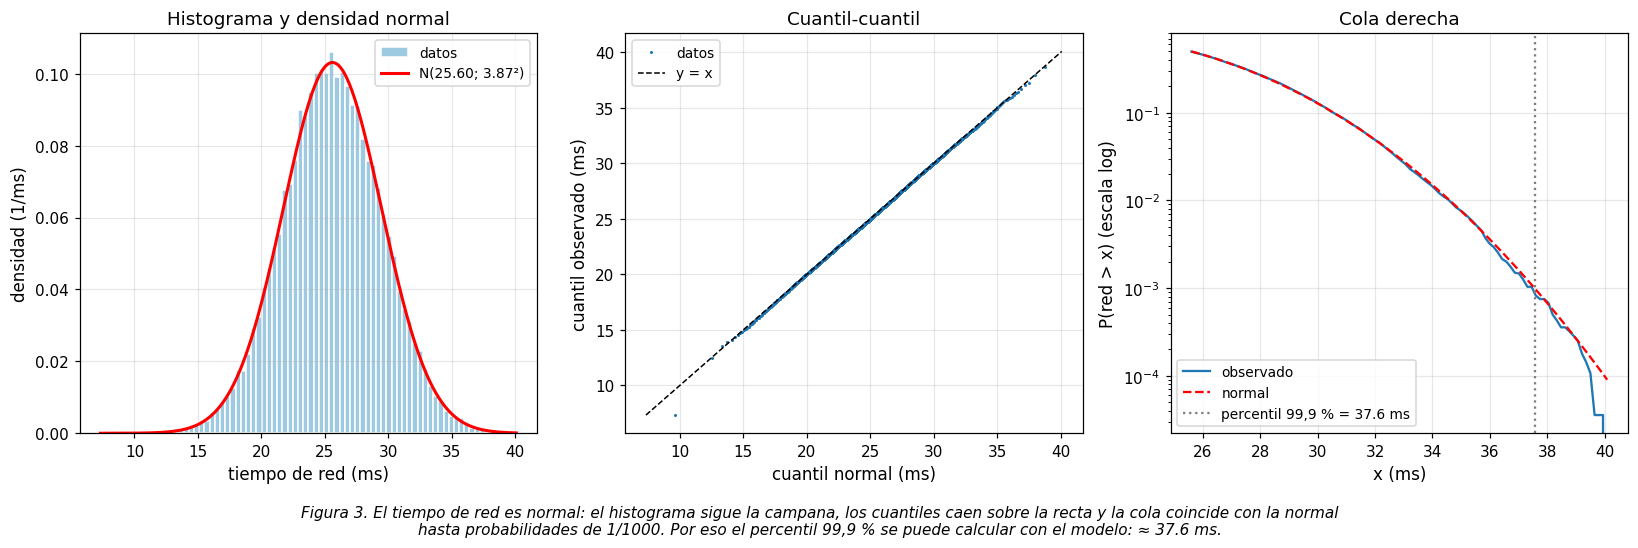

In [ ]:
# =====================================  FIGURA 3  =====================================
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].hist(red, bins=80, density=True, color="#9ecae1", edgecolor="white", label="datos")
xx = np.linspace(red.min(), red.max(), 300)
ax[0].plot(xx, stats.norm.pdf(xx, mu_r, sig_r), "r", lw=2, label=f"N({mu_r:.2f}; {sig_r:.2f}²)")
ax[0].set_xlabel("tiempo de red (ms)"); ax[0].set_ylabel("densidad (1/ms)"); ax[0].set_title("Histograma y densidad normal"); ax[0].legend()
pp = (np.arange(1, n_r + 1) - 0.5) / n_r
ax[1].plot(stats.norm.ppf(pp, mu_r, sig_r)[::10], np.sort(red)[::10], ".", ms=2, label="datos")
ax[1].plot([red.min(), red.max()], [red.min(), red.max()], "k--", lw=1, label="y = x")
ax[1].set_xlabel("cuantil normal (ms)"); ax[1].set_ylabel("cuantil observado (ms)"); ax[1].set_title("Cuantil-cuantil"); ax[1].legend()
xt = np.linspace(mu_r, red.max(), 100)
ax[2].semilogy(xt, [(red > v).mean() for v in xt], label="observado")
ax[2].semilogy(xt, 1 - stats.norm.cdf(xt, mu_r, sig_r), "r--", label="normal")
ax[2].axvline(q999_mod, color="gray", ls=":", label=f"percentil 99,9 % = {q999_mod:.1f} ms")
ax[2].set_xlabel("x (ms)"); ax[2].set_ylabel("P(red > x) (escala log)"); ax[2].set_title("Cola derecha"); ax[2].legend()
pie_de_figura(fig, 3, "El tiempo de red es normal: el histograma sigue la campana, los cuantiles caen sobre la recta y la cola coincide con la normal\n"
                      f"hasta probabilidades de 1/1000. Por eso el percentil 99,9 % se puede calcular con el modelo: ≈ {q999_mod:.1f} ms.")
plt.tight_layout(); guardar_figura(fig, 3); plt.show()

**Conclusión C3.** `red_ms` **admite un modelo normal** $N(\hat\mu \approx 25{,}6;\ \hat\sigma \approx 3{,}9)$ ms. Los tres criterios lo respaldan: sesgo y curtosis están dentro del rango que producen muestras normales de este tamaño, la regla empírica se cumple (68/95/99,7 %) y los cuantiles coinciden hasta el 99,9 %. Las probabilidades $P(\text{red} > x)$ del modelo caen dentro de los intervalos de las observadas, y el modelo da intervalos más estrechos en la cola, donde hay pocos casos. El percentil 99,9 % es ≈ 37,6 ms. **Aporta a P1 y P3** (la red sola nunca se acerca a $\tau$).

---
### C4. Tiempo total de GPU de N solicitudes no cacheadas
Sea $T_N = X_1 + \dots + X_N$ con $N = 14$ solicitudes no cacheadas consecutivas. Si son independientes y con la misma distribución, $E[T_N] = N m$ y $\text{Var}(T_N) = N v$ (valor esperado y varianza de una suma, semanas 6 y 14). Se pide $P(T_N > N(\hat m + 15))$.
- **Aproximación 1, normal (TLC, semana 16):** $T_N \approx N(Nm, Nv)$, así que $P \approx 1 - \Phi\!\left(\frac{N(\hat m + 15) - N\hat m}{\sqrt{N\hat v}}\right) = 1 - \Phi\!\left(\frac{15\sqrt N}{\sqrt{\hat v}}\right)$.
- **Aproximación 2, gamma por momentos (semana 11):** si cada $X_i$ fuera Gamma$(k, \theta)$, la suma sería Gamma$(Nk, \theta)$ (propiedad que se demuestra con la función generadora de momentos, $M(t) = (1 - \theta t)^{-k}$ elevada a la $N$). Con $k = m^2/v$ y $\theta = v/m$ se conservan la media y la varianza de $T_N$ y, además, la **asimetría a la derecha** que la normal ignora.
- **Referencia: Montecarlo**, sumando $N$ tiempos de GPU remuestreados de los datos.

In [ ]:
# Paso 1. Datos, umbral y supuesto de independencia entre solicitudes consecutivas
umbral_C4 = N * (m_hat + 15)
corr_X = np.corrcoef(X_gpu[:-1], X_gpu[1:])[0, 1]                 # orden de llegada
print(f"N = {N}, m = {m_hat:.3f} ms, s = {np.sqrt(v_hat):.3f} ms -> umbral N(m + 15) = {umbral_C4:.1f} ms")
print(f"Correlación entre tiempos de GPU consecutivos = {corr_X:.4f} (≈ 0: se pueden tratar como independientes)")

# Paso 2. Dos aproximaciones analíticas
P_normal = 1 - stats.norm.cdf(umbral_C4, N * m_hat, np.sqrt(N * v_hat))
P_gamma = 1 - stats.gamma.cdf(umbral_C4, N * m_hat ** 2 / v_hat, scale=v_hat / m_hat)

# Paso 3. Montecarlo: sumas de N tiempos de GPU remuestreados
R_C4 = 1_000_000
T_sim = np.zeros(R_C4)
for _ in range(N):
    T_sim += rng.choice(X_gpu, R_C4)
P_mc = np.mean(T_sim > umbral_C4)
li, ls = ic_proporcion(int(np.sum(T_sim > umbral_C4)), R_C4)
tabla_C4 = pd.DataFrame({"método": ["normal (TLC)", "gamma por momentos", "Montecarlo (referencia)"],
                         "P(T_N > umbral)": [P_normal, P_gamma, P_mc]})
tabla_C4["error relativo vs Montecarlo (%)"] = 100 * (tabla_C4["P(T_N > umbral)"] / P_mc - 1)
print(tabla_C4.round(5).to_string(index=False))
print(f"Montecarlo: {texto_ic(P_mc, li, ls, 'TLC', 5)} | asimetría de T_N simulada = {stats.skew(T_sim):.3f} (normal: 0)")

N = 14, m = 39.220 ms, s = 25.808 ms -> umbral N(m + 15) = 759.1 ms
Correlación entre tiempos de GPU consecutivos = -0.0006 (≈ 0: se pueden tratar como independientes)
                 método  P(T_N > umbral)  error relativo vs Montecarlo (%)
           normal (TLC)          0.01483                         -43.04462
     gamma por momentos          0.02256                         -13.33168
Montecarlo (referencia)          0.02603                           0.00000
Montecarlo: 0.02603  [0.02577; 0.02629]  (IC 90%, TLC) | asimetría de T_N simulada = 0.528 (normal: 0)


**Conclusión C4.** El umbral $N(\hat m + 15)$ está a ≈ 2,2 desviaciones estándar por encima de la media de $T_N$. La **aproximación normal subestima** la probabilidad (error de ≈ −43 %): con solo 14 sumandos muy asimétricos, el TLC todavía no ha borrado la asimetría de la suma (≈ 0,5), y la cola derecha pesa más que en la normal. La **gamma por momentos** queda mucho más cerca del Montecarlo (error ≈ −13 %) porque conserva buena parte de esa asimetría. **Se prefiere la gamma:** tiene fórmula cerrada, usa solo la media y la varianza estimadas y respeta la forma de la cola. **Aporta a P1 y P3.**

---
# Parte D — Dependencias y esperanza condicional (14 pts)
### D1. Distribución conjunta de (clase de tamaño, caché)
Cada solicitud del régimen estable se clasifica como **pequeña** ($< t_1 = 90$ KB), **mediana** ($90 \le \cdot < 425$ KB) o **grande** ($\ge t_2 = 425$ KB). El vector aleatorio $(T, H)$, con $T$ la clase y $H$ = `cache_hit`, tiene (semana 13):
- **conjunta** $p_{ij} = P(T = i, H = j)$, estimada con la proporción de solicitudes en cada celda;
- **marginales** $p_{i\cdot} = \sum_j p_{ij}$ y $p_{\cdot j} = \sum_i p_{ij}$;
- **condicionales** $P(H = 1 \mid T = i) = p_{i1}/p_{i\cdot}$ (semana 3).

**Independencia** (semana 3): $T$ y $H$ son independientes si y solo si $p_{ij} = p_{i\cdot}\,p_{\cdot j}$ en todas las celdas, lo que equivale a que $P(H = 1 \mid T = i)$ sea **igual en las tres clases**. Se comprueba de tres formas: (1) el cociente $p_{ij}/(p_{i\cdot}p_{\cdot j})$, que vale 1 bajo independencia; (2) intervalos para $P(H = 1 \mid T = i)$ y para las diferencias entre clases; (3) Montecarlo: si fueran independientes, la caché no dependería de la clase, así que al **barajar al azar** la columna `cache_hit` entre las solicitudes se obtiene lo que produce la independencia, y se compara con lo observado.

In [ ]:
# Paso 1. Conjunta, marginales y condicionales
ORDEN = ["pequeña", "mediana", "grande"]
clase = pd.cut(df_estable.tam_kb, [-np.inf, t1_kb, t2_kb, np.inf], right=False, labels=ORDEN)
H = df_estable.cache_hit.to_numpy().astype(int)
n_d1 = len(df_estable)
conteos_d1 = pd.crosstab(clase, H).reindex(ORDEN); conteos_d1.columns = ["sin caché (H=0)", "con caché (H=1)"]
conjunta = conteos_d1 / n_d1
marg_T, marg_H = conjunta.sum(axis=1), conjunta.sum(axis=0)
tabla = conjunta.copy(); tabla["marginal P(T)"] = marg_T; tabla.loc["marginal P(H)"] = list(marg_H) + [1.0]
print("Distribución conjunta con marginales:"); print(tabla.round(4).to_string(), "\n")
p_cache_clase = {}
for c_ in ORDEN:
    k_, n_ = int(conteos_d1.loc[c_, "con caché (H=1)"]), int(conteos_d1.loc[c_].sum())
    li, ls = ic_proporcion(k_, n_)
    p_cache_clase[c_] = (k_, n_)
    print(f"P(caché | {c_:8s}) = {texto_ic(k_ / n_, li, ls, 'TLC')}  (n = {n_})")
print(f"P(caché) global      = {marg_H.iloc[1]:.3f}")
print("\nP(T | H) (cada columna suma 1):"); print((conteos_d1 / conteos_d1.sum(axis=0)).round(3).to_string())

Distribución conjunta con marginales:
               sin caché (H=0)  con caché (H=1)  marginal P(T)
tam_kb                                                        
pequeña                 0.0779           0.0878         0.1657
mediana                 0.4754           0.2256         0.7010
grande                  0.1108           0.0226         0.1333
marginal P(H)           0.6640           0.3360         1.0000 

P(caché | pequeña ) = 0.530  [0.518; 0.542]  (IC 90%, TLC)  (n = 4635)
P(caché | mediana ) = 0.322  [0.316; 0.327]  (IC 90%, TLC)  (n = 19606)
P(caché | grande  ) = 0.169  [0.159; 0.179]  (IC 90%, TLC)  (n = 3729)
P(caché) global      = 0.336

P(T | H) (cada columna suma 1):
         sin caché (H=0)  con caché (H=1)
tam_kb                                   
pequeña            0.117            0.261
mediana            0.716            0.671
grande             0.167            0.067


In [ ]:
# Paso 2. ¿Son independientes? Cociente conjunta / producto de marginales, diferencias entre clases y Montecarlo
razon_d1 = conjunta / np.outer(marg_T, marg_H)
print("Cociente p_ij / (p_i. p_.j) (1 bajo independencia):"); print(razon_d1.round(3).to_string(), "\n")

print("Diferencias de P(caché | clase) entre clases:")
for a_, b_ in [("pequeña", "mediana"), ("mediana", "grande"), ("pequeña", "grande")]:
    dif, ee = ic_dif_proporciones(*p_cache_clase[a_], *p_cache_clase[b_])
    li, ls = ic_normal(dif, ee)
    print(f"  {a_} - {b_}: {texto_ic(dif, li, ls, 'TLC')}")

# Montecarlo de la independencia: se baraja cache_hit y se mide la mayor distancia |P(caché|clase) - P(caché)|
cl = clase.to_numpy()
def distancia_indep(h):
    return max(abs(h[cl == c_].mean() - h.mean()) for c_ in ORDEN)
d_obs = distancia_indep(H)
d_sim = [distancia_indep(rng.permutation(H)) for _ in range(2000)]
print(f"\nMayor |P(caché|clase) - P(caché)| observada = {d_obs:.3f}; si fueran independientes (2000 barajadas): "
      f"máximo simulado = {max(d_sim):.3f} -> fracción >= observado = {prob_montecarlo(d_obs, d_sim):.4f}")

Cociente p_ij / (p_i. p_.j) (1 bajo independencia):
         sin caché (H=0)  con caché (H=1)
tam_kb                                   
pequeña            0.708            1.578
mediana            1.021            0.958
grande             1.251            0.504 

Diferencias de P(caché | clase) entre clases:
  pequeña - mediana: 0.208  [0.195; 0.222]  (IC 90%, TLC)
  mediana - grande: 0.153  [0.141; 0.164]  (IC 90%, TLC)
  pequeña - grande: 0.361  [0.345; 0.377]  (IC 90%, TLC)

Mayor |P(caché|clase) - P(caché)| observada = 0.194; si fueran independientes (2000 barajadas): máximo simulado = 0.026 -> fracción >= observado = 0.0000


---
## FIGURA 4 · Mapa de calor de la conjunta (ítem D1)
Izquierda: la distribución conjunta $\hat p_{ij}$. Derecha: el cociente observado / esperado bajo independencia (todo 1 si fueran independientes).

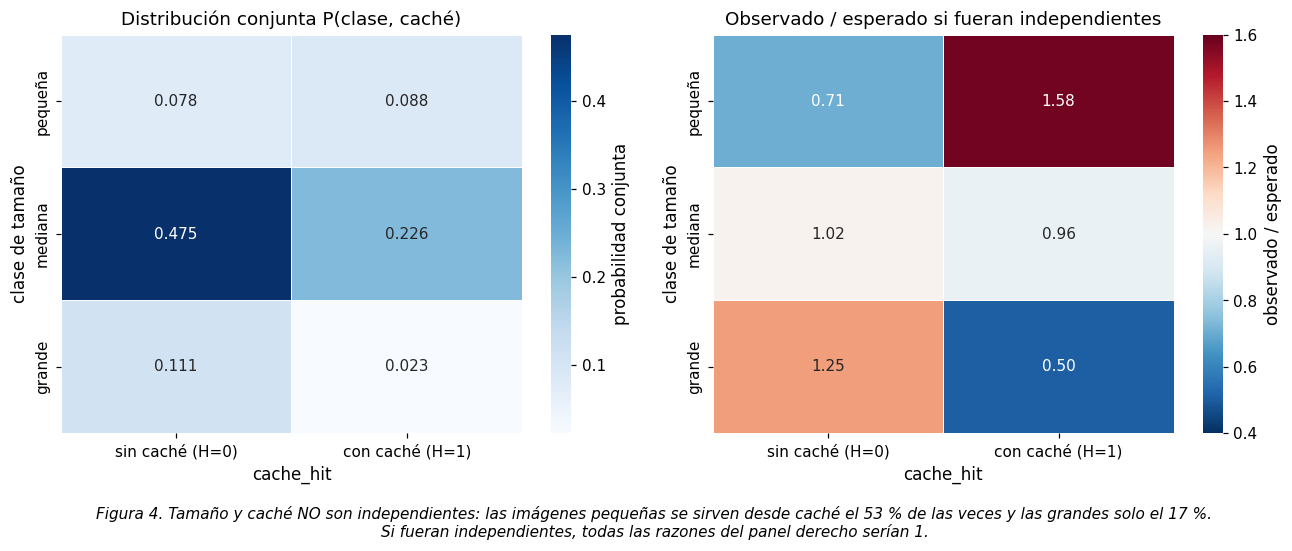

In [ ]:
# =====================================  FIGURA 4  =====================================
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
sns.heatmap(conjunta, annot=conjunta.map(lambda v: f"{v:.3f}"), fmt="", cmap="Blues", linewidths=0.5,
            cbar_kws={"label": "probabilidad conjunta"}, ax=ax[0])
ax[0].set_title("Distribución conjunta P(clase, caché)"); ax[0].set_xlabel("cache_hit"); ax[0].set_ylabel("clase de tamaño")
sns.heatmap(razon_d1, annot=razon_d1.map(lambda v: f"{v:.2f}"), fmt="", cmap="RdBu_r", center=1, vmin=0.4, vmax=1.6,
            linewidths=0.5, cbar_kws={"label": "observado / esperado"}, ax=ax[1])
ax[1].set_title("Observado / esperado si fueran independientes"); ax[1].set_xlabel("cache_hit"); ax[1].set_ylabel("clase de tamaño")
for a in ax: a.grid(False)
pk, pg = (lambda k, n: k / n)(*p_cache_clase["pequeña"]), (lambda k, n: k / n)(*p_cache_clase["grande"])
pie_de_figura(fig, 4, f"Tamaño y caché NO son independientes: las imágenes pequeñas se sirven desde caché el {100 * pk:.0f} % de las veces "
                      f"y las grandes solo el {100 * pg:.0f} %.\nSi fueran independientes, todas las razones del panel derecho serían 1.")
plt.tight_layout(); guardar_figura(fig, 4); plt.show()

**Conclusión D1.** La clase de tamaño y la caché **no son independientes**. $P(\text{caché} \mid \text{clase})$ baja con el tamaño: ≈ 0,53 en las pequeñas, ≈ 0,32 en las medianas y ≈ 0,17 en las grandes, y los intervalos de las tres diferencias están lejos de 0. En las 2000 barajadas de Montecarlo (que es lo que produciría la independencia) la mayor diferencia nunca pasa de ≈ 0,03, mientras que la observada es ≈ 0,19. La razón observado/esperado es 1,58 para "pequeña con caché" y 0,50 para "grande con caché". **Consecuencia:** la masa en 0 de $G$ (C1) depende del tamaño; las imágenes grandes casi siempre llegan a la GPU y además tardan más (C2). **Aporta a P1 y P3.**

---
### D2. Esperanza condicional del tiempo de GPU
Se estima sin suponer ninguna forma funcional (semana 14):
- $E[G \mid \text{clase}, \text{no caché}]$: el promedio de $G$ de las no cacheadas de cada clase, con intervalo $\bar x \pm z\,s/\sqrt n$;
- $E[G \mid \text{tam\_kb}]$: se parte `tam_kb` en 20 intervalos con el mismo número de solicitudes y se promedia $G$ en cada uno (incluidas las cacheadas, con $G = 0$).

Como $G = 0$ con caché, por probabilidad total $E[G \mid \text{clase}] = P(\text{no caché} \mid \text{clase})\cdot E[G \mid \text{clase}, \text{no caché}]$: el tamaño influye en $G$ por **dos caminos**, más tiempo de GPU y menos caché. Después se verifican:
$$\textbf{esperanza total: } E[G] = \sum_y P(Y = y)\,E[G \mid Y = y], \qquad \textbf{varianza total: } \text{Var}(G) = E[\text{Var}(G \mid Y)] + \text{Var}(E[G \mid Y]),$$
y la fracción de la varianza explicada por $Y$, $\eta^2 = \text{Var}(E[G \mid Y])/\text{Var}(G)$.

In [ ]:
# Paso 1. E[G | clase, no caché] y E[G | clase] con intervalos, y los dos caminos
d2 = df_estable.assign(clase=clase.values)
filas = []
for c_ in ORDEN:
    sub = d2[d2.clase == c_]; nc_ = sub[sub.cache_hit == 0].gpu_ms
    li, ls = ic_normal(nc_.mean(), nc_.std(ddof=1) / np.sqrt(len(nc_)))
    li2, ls2 = ic_normal(sub.gpu_ms.mean(), sub.gpu_ms.std(ddof=1) / np.sqrt(len(sub)))
    filas.append({"clase": c_, "P(clase)": len(sub) / len(d2), "P(no caché|clase)": 1 - sub.cache_hit.mean(),
                  "E[G|clase,no caché]": nc_.mean(), "IC no caché": f"[{li:.2f}; {ls:.2f}]",
                  "E[G|clase]": sub.gpu_ms.mean(), "IC todas": f"[{li2:.2f}; {ls2:.2f}]"})
tabla_D2 = pd.DataFrame(filas).set_index("clase")
print(tabla_D2.round(4).to_string())
gr, pq = tabla_D2.loc["grande"], tabla_D2.loc["pequeña"]
print(f"\nDe pequeña a grande, E[G|clase] se multiplica por {gr['E[G|clase]'] / pq['E[G|clase]']:.2f} = "
      f"{gr['E[G|clase,no caché]'] / pq['E[G|clase,no caché]']:.2f} (más tiempo de GPU) × "
      f"{gr['P(no caché|clase)'] / pq['P(no caché|clase)']:.2f} (menos caché)")

         P(clase)  P(no caché|clase)  E[G|clase,no caché]     IC no caché  E[G|clase]        IC todas
clase                                                                                                
pequeña    0.1657             0.4699              19.2468  [18.94; 19.56]      9.0441    [8.77; 9.32]
mediana    0.7010             0.6782              35.4793  [35.21; 35.74]     24.0607  [23.80; 24.33]
grande     0.1333             0.8308              69.3151  [68.29; 70.35]     57.5860  [56.48; 58.69]

De pequeña a grande, E[G|clase] se multiplica por 6.37 = 3.60 (más tiempo de GPU) × 1.77 (menos caché)


In [ ]:
# Paso 2. E[G | tam_kb] no paramétrica: promedio de G en 20 intervalos de tamaño con el mismo número de solicitudes
d2["intervalo_tam"] = pd.qcut(d2.tam_kb, 20)
reg = d2.groupby("intervalo_tam", observed=True).agg(tam_medio=("tam_kb", "mean"), E_G=("gpu_ms", "mean"),
                                                      P_no_cache=("cache_hit", lambda s: 1 - s.mean()), n=("gpu_ms", "size"))
reg["E_G_no_cache"] = d2[d2.cache_hit == 0].groupby("intervalo_tam", observed=True).gpu_ms.mean()
print(reg.round(3).to_string())
print("\nLa caché cambia en escalón en las fronteras de clase y es casi constante dentro de cada clase:")
for c_ in ORDEN:
    sub = d2[d2.clase == c_]
    print(f"  {c_:8s}: P(caché) por cuartiles de tamaño = {sub.groupby(pd.qcut(sub.tam_kb, 4), observed=True).cache_hit.mean().round(3).values}")

                    tam_medio     E_G  P_no_cache     n  E_G_no_cache
intervalo_tam                                                        
(1.249, 44.124]        29.033   7.841       0.472  1399        16.621
(44.124, 66.216]       55.525   9.044       0.467  1398        19.362
(66.216, 84.2]         75.457  10.024       0.476  1400        21.071
(84.2, 101.67]         93.168  14.237       0.629  1398        22.644
(101.67, 117.832]     109.840  16.405       0.672  1398        24.425
(117.832, 133.687]    125.847  17.136       0.665  1398        25.759
(133.687, 150.141]    142.017  18.047       0.672  1399        26.860
(150.141, 167.666]    159.184  20.995       0.704  1398        29.828
(167.666, 185.44]     176.469  20.853       0.677  1399        30.806
(185.44, 204.255]     194.556  22.955       0.691  1398        33.220
(204.255, 224.067]    214.350  22.930       0.667  1398        34.395
(224.067, 246.174]    234.967  25.362       0.682  1399        37.193
(246.174, 269.526]  

In [ ]:
# Paso 3 y 4. Ley de la esperanza total y de la varianza total (varianzas con divisor n para que la identidad sea exacta)
Gv = d2.gpu_ms.to_numpy()
condiciones = {"clase de tamaño": d2.clase.astype(str), "caché": d2.cache_hit.astype(str),
               "clase × caché": d2.clase.astype(str) + "-" + d2.cache_hit.astype(str), "20 intervalos de tam_kb": d2.intervalo_tam.astype(str)}
filas = []
for nombre, Y_ in condiciones.items():
    grupos = d2.groupby(Y_.values).gpu_ms
    P_y, E_y, V_y = grupos.size() / len(d2), grupos.mean(), grupos.var(ddof=0)
    esperanza_total = (P_y * E_y).sum()
    dentro, entre = (P_y * V_y).sum(), (P_y * (E_y - Gv.mean()) ** 2).sum()
    filas.append({"condicionando en": nombre, "sum P(y)E[G|y]": esperanza_total, "E[G]": Gv.mean(),
                  "E[Var(G|Y)]": dentro, "Var(E[G|Y])": entre, "suma": dentro + entre, "Var(G)": Gv.var(), "eta² = explicada": entre / Gv.var()})
tabla_vt = pd.DataFrame(filas).set_index("condicionando en")
print(tabla_vt.round(4).to_string())

# Intervalo para la fracción explicada por la clase (Montecarlo de remuestreo de las solicitudes)
cl_arr = d2.clase.astype(str).to_numpy()
def eta2(idx):
    gg, cc = Gv[idx], cl_arr[idx]
    medias = pd.Series(gg).groupby(cc).agg(["mean", "size"])
    return ((medias["size"] / len(gg)) * (medias["mean"] - gg.mean()) ** 2).sum() / gg.var()
eta_boot = [eta2(rng.integers(0, len(Gv), len(Gv))) for _ in range(300)]
eta_c = tabla_vt.loc["clase de tamaño", "eta² = explicada"]
print(f"\nFracción de Var(G) explicada por la clase: {texto_ic(eta_c, np.quantile(eta_boot, alpha / 2), np.quantile(eta_boot, 1 - alpha / 2), 'Montecarlo de remuestreo')}")

                         sum P(y)E[G|y]     E[G]  E[Var(G|Y)]  Var(E[G|Y])      suma    Var(G)  eta² = explicada
condicionando en                                                                                                
clase de tamaño                 26.0419  26.0419     602.1180     183.2891  785.4072  785.4072            0.2334
caché                           26.0419  26.0419     442.2277     343.1795  785.4072  785.4072            0.4369
clase × caché                   26.0419  26.0419     304.1933     481.2139  785.4072  785.4072            0.6127
20 intervalos de tam_kb         26.0419  26.0419     567.5645     217.8427  785.4072  785.4072            0.2774

Fracción de Var(G) explicada por la clase: 0.233  [0.224; 0.243]  (IC 90%, Montecarlo de remuestreo)


**Conclusión D2.** Sin caché, el tiempo medio de GPU es ≈ 19 ms en las imágenes pequeñas, ≈ 35 ms en las medianas y ≈ 69 ms en las grandes; con las cacheadas incluidas, $E[G \mid \text{clase}]$ ≈ 9, 24 y 58 ms. De pequeña a grande el tiempo medio se multiplica por ≈ 6,4, que es el **producto de los dos caminos**: ≈ ×3,6 porque la imagen tarda más y ≈ ×1,8 porque casi nunca está en caché. $E[G \mid \text{tam\_kb}]$ crece con el tamaño y **salta en las fronteras** $t_1$ y $t_2$, porque la caché cambia en escalón en ellas y es constante dentro de cada clase. Las leyes de la **esperanza total** y de la **varianza total** se cumplen exactamente con los datos. **La clase de tamaño explica ≈ 23 % de Var(G)**; la caché sola, ≈ 44 %, y las dos juntas, ≈ 61 %. **Aporta a P1.**

---
### D3. Modelo lineal para E[G | tam_kb, no caché]
**Modelo (regresión, del sistema de evaluación del curso).** Para las no cacheadas, con $x$ = `tam_kb` e $y$ = `gpu_ms`: $y_i = \beta_0 + \beta_1 x_i + e_i$, con $E[e_i \mid x_i] = 0$, es decir, $E[G \mid \text{tam}, \text{no caché}] = \beta_0 + \beta_1\,\text{tam}$.

**Mínimos cuadrados, planteado y resuelto por el grupo.** Con $\mathbf X = [\mathbf 1\ \ \mathbf x]$, minimizar $\|\mathbf y - \mathbf X\boldsymbol\beta\|^2$ lleva a las **ecuaciones normales**
$$\mathbf X^\top\mathbf X\,\hat{\boldsymbol\beta} = \mathbf X^\top\mathbf y, \qquad \mathbf X^\top\mathbf X = \begin{pmatrix} n & \sum x_i \\ \sum x_i & \sum x_i^2\end{pmatrix},\quad \mathbf X^\top\mathbf y = \begin{pmatrix}\sum y_i \\ \sum x_i y_i\end{pmatrix},$$
un sistema 2×2 que se resuelve con la inversa explícita. **Intervalos:** si los errores tienen la misma varianza $\sigma^2$, $\text{Var}(\hat{\boldsymbol\beta}) = \sigma^2(\mathbf X^\top\mathbf X)^{-1}$, con $\hat\sigma^2 = \sum e_i^2/(n-2)$, y $\hat\beta_j \pm z\,\text{ee}(\hat\beta_j)$.

In [ ]:
# Paso 1. Mínimos cuadrados resolviendo las ecuaciones normales (sin sklearn ni statsmodels)
nc_d3 = df_estable[df_estable.cache_hit == 0]
x_d3, y_d3 = nc_d3.tam_kb.to_numpy(), nc_d3.gpu_ms.to_numpy()
n_d3 = len(x_d3)
X_d3 = np.column_stack([np.ones(n_d3), x_d3])
XtX, Xty = X_d3.T @ X_d3, X_d3.T @ y_d3
det = XtX[0, 0] * XtX[1, 1] - XtX[0, 1] * XtX[1, 0]
XtX_inv = np.array([[XtX[1, 1], -XtX[0, 1]], [-XtX[1, 0], XtX[0, 0]]]) / det       # inversa explícita de 2x2
beta_mco = XtX_inv @ Xty
print("X'X =\n", XtX.round(1), "\nX'y =", Xty.round(1))
print(f"beta (inversa explícita) = {beta_mco} | comprobación np.linalg.solve = {np.linalg.solve(XtX, Xty)}")
res_mco = y_d3 - X_d3 @ beta_mco
s2_mco = res_mco @ res_mco / (n_d3 - 2)
ee_mco = np.sqrt(np.diag(s2_mco * XtX_inv))
R2 = 1 - res_mco @ res_mco / ((y_d3 - y_d3.mean()) @ (y_d3 - y_d3.mean()))
print(f"\nn = {n_d3} | sigma = {np.sqrt(s2_mco):.3f} ms | R² = {R2:.4f}")
for j, nombre in enumerate(["beta0 (ms)", "beta1 (ms/KB)"]):
    print(f"{nombre:14s}: {texto_ic(beta_mco[j], *ic_normal(beta_mco[j], ee_mco[j]), 'MCO clásico', 5)}")
print(f"Lectura: cada 100 KB adicionales agregan {100 * beta_mco[1]:.2f} ms de GPU; el costo fijo es ≈ {beta_mco[0]:.1f} ms")

X'X =
 [[1.85720000e+04 4.86088030e+06]
 [4.86088030e+06 1.85423543e+09]] 
X'y = [7.28391300e+05 2.47505471e+08]
beta (inversa explícita) = [13.6477438   0.09770357] | comprobación np.linalg.solve = [13.6477438   0.09770357]

n = 18572 | sigma = 19.155 ms | R² = 0.4492
beta0 (ms)    : 13.64774  [13.23508; 14.06041]  (IC 90%, MCO clásico)
beta1 (ms/KB) : 0.09770  [0.09640; 0.09901]  (IC 90%, MCO clásico)
Lectura: cada 100 KB adicionales agregan 9.77 ms de GPU; el costo fijo es ≈ 13.6 ms


**Paso 2. Análisis de residuos.** Se revisa cada supuesto con evidencia numérica: (1) **linealidad:** promedios de $y$ por deciles de $x$ frente a la recta; (2) **varianza constante:** desviación estándar de los residuos por deciles del valor ajustado; (3) **forma** de los residuos: sesgo y curtosis; (4) **independencia:** correlación entre residuos consecutivos en orden de llegada; (5) la **versión**, asignada al azar, no debe estar correlacionada con el tamaño.

In [ ]:
# Paso 2. Análisis de residuos
ajuste = X_d3 @ beta_mco
dec_x = pd.qcut(x_d3, 10, labels=False)
lin = pd.DataFrame({"x": x_d3, "y": y_d3, "dec": dec_x}).groupby("dec").agg(x=("x", "mean"), y=("y", "mean"), n=("y", "size"), s=("y", "std"))
lin["recta"] = beta_mco[0] + beta_mco[1] * lin.x
lin["z"] = (lin.y - lin.recta) / (lin.s / np.sqrt(lin.n))
print(f"1. Linealidad: máx |media por decil - recta| = {np.abs(lin.y - lin.recta).max():.2f} ms, máx |z| = {np.abs(lin.z).max():.2f}")
dec_aj = pd.qcut(ajuste, 10, labels=False)
het = pd.DataFrame({"aj": ajuste, "res": res_mco, "dec": dec_aj}).groupby("dec").agg(ajustado=("aj", "mean"), de_residuo=("res", "std"))
het["CV = de/ajustado"] = het.de_residuo / het.ajustado
print("2. Varianza constante: desviación estándar de los residuos por decil del ajuste"); print(het.round(3).T.to_string())
pend = np.polyfit(np.log(het.ajustado), np.log(het.de_residuo), 1)[0]
print(f"   pendiente de log(de) contra log(ajustado) = {pend:.3f} (0: varianza constante; 1: de proporcional a la media)")
print(f"3. Forma de los residuos: sesgo = {stats.skew(res_mco):.3f}, curtosis exc. = {stats.kurtosis(res_mco):.3f}")
print(f"4. Independencia: correlación entre residuos consecutivos = {np.corrcoef(res_mco[:-1], res_mco[1:])[0, 1]:.4f}")
print(f"5. Correlación entre tam_kb y versión B = {np.corrcoef(x_d3, (nc_d3.version == 'B').to_numpy())[0, 1]:.4f}")

1. Linealidad: máx |media por decil - recta| = 0.75 ms, máx |z| = 1.27
2. Varianza constante: desviación estándar de los residuos por decil del ajuste
dec                    0       1       2       3       4       5      6       7       8       9
ajustado          18.686  23.433  26.585  29.788  33.221  37.164  41.82  47.879  56.812  76.805
de_residuo         8.352  10.453  11.662  13.456  14.986  17.085  18.80  21.476  25.418  34.581
CV = de/ajustado   0.447   0.446   0.439   0.452   0.451   0.460   0.45   0.449   0.447   0.450
   pendiente de log(de) contra log(ajustado) = 1.008 (0: varianza constante; 1: de proporcional a la media)
3. Forma de los residuos: sesgo = 1.206, curtosis exc. = 5.247
4. Independencia: correlación entre residuos consecutivos = 0.0015
5. Correlación entre tam_kb y versión B = -0.0017


**Paso 3. Corrección fundamentada en la estructura probabilística.** El paso 2 muestra que la media sí es lineal, pero la **desviación estándar de los residuos crece en proporción a la media** (coeficiente de variación constante). Eso corresponde a un modelo **multiplicativo**, coherente con la lognormal de C2:
$$G = \mu(x)\cdot\varepsilon,\quad \mu(x) = \beta_0 + \beta_1 x,\quad E[\varepsilon] = 1,\ \text{Var}(\varepsilon) = \phi \ \Longrightarrow\ \text{Var}(G \mid x) = \phi\,\mu(x)^2.$$
Con esa estructura, MCO sigue siendo insesgado, pero su fórmula de error estándar está mal (supone la misma varianza para todos) y da igual peso a las imágenes grandes, que son las más ruidosas. **Corrección: mínimos cuadrados ponderados (MCP)** con pesos $w_i = 1/\mu(x_i)^2$, el inverso de la varianza: se resuelve $\mathbf X^\top\mathbf W\mathbf X\,\boldsymbol\beta = \mathbf X^\top\mathbf W\mathbf y$, con $\text{Var}(\hat{\boldsymbol\beta}) = \hat\phi\,(\mathbf X^\top\mathbf W\mathbf X)^{-1}$. Como $\mu$ es desconocida, se parte de MCO y se repite el cálculo de pesos unas pocas veces.

**Paso 4. ¿La corrección importa? Montecarlo.** Se generan 1000 muestras con la estructura de los datos (los tamaños observados, la recta de MCP y el ruido $\varepsilon$ remuestreado de los cocientes $y/\hat\mu$) y se mide qué fracción de los intervalos de cada método contiene la pendiente verdadera.

In [ ]:
# Paso 3. Mínimos cuadrados ponderados con pesos 1/mu(x)^2
def mcp(X, y, iteraciones=10):
    b = np.linalg.solve(X.T @ X, X.T @ y)                        # punto de partida: MCO
    for _ in range(iteraciones):
        w = 1 / (X @ b) ** 2
        b = np.linalg.solve(X.T @ (X * w[:, None]), X.T @ (w * y))
    w = 1 / (X @ b) ** 2
    phi = np.sum(w * (y - X @ b) ** 2) / (len(y) - 2)
    ee = np.sqrt(np.diag(phi * np.linalg.inv(X.T @ (X * w[:, None]))))
    return b, ee, phi

beta_mcp, ee_mcp, phi_mcp = mcp(X_d3, y_d3)
print(f"phi = {phi_mcp:.4f} -> coeficiente de variación de epsilon = {np.sqrt(phi_mcp):.3f}")
for j, nombre in enumerate(["beta0 (ms)", "beta1 (ms/KB)"]):
    print(f"{nombre:14s} MCO: {texto_ic(beta_mco[j], *ic_normal(beta_mco[j], ee_mco[j]), 'clásico', 5)}")
    print(f"{'':14s} MCP: {texto_ic(beta_mcp[j], *ic_normal(beta_mcp[j], ee_mcp[j]), 'ponderado', 5)}")
pearson = (y_d3 - X_d3 @ beta_mcp) / (X_d3 @ beta_mcp)
print("Residuos relativos (y - mu)/mu por decil: DE entre",
      np.round(pd.Series(pearson).groupby(pd.qcut(X_d3 @ beta_mcp, 10, labels=False)).std().agg(["min", "max"]).values, 3))

# Paso 4. Montecarlo: cobertura y precisión de MCO clásico y MCP bajo la estructura de los datos
eps_obs = y_d3 / (X_d3 @ beta_mcp)
R_D3 = 1000
cub = {"MCO clásico": 0, "MCP": 0}; b1 = {"MCO clásico": [], "MCP": []}
for _ in range(R_D3):
    ys = (X_d3 @ beta_mcp) * rng.choice(eps_obs, n_d3)
    bo = np.linalg.solve(XtX, X_d3.T @ ys)
    so = np.sqrt((ys - X_d3 @ bo) @ (ys - X_d3 @ bo) / (n_d3 - 2) * XtX_inv[1, 1])
    bw, ew, _ = mcp(X_d3, ys, iteraciones=3)
    cub["MCO clásico"] += abs(bo[1] - beta_mcp[1]) <= z * so; cub["MCP"] += abs(bw[1] - beta_mcp[1]) <= z * ew[1]
    b1["MCO clásico"].append(bo[1]); b1["MCP"].append(bw[1])
for k_ in cub:
    print(f"{k_:12s}: cobertura del IC de beta1 = {cub[k_] / R_D3:.3f} (nominal {nivel_confianza:.2f}) | DE real de beta1 = {np.std(b1[k_]):.6f}")
print(f"MCP es {np.var(b1['MCO clásico']) / np.var(b1['MCP']):.2f} veces más preciso (cociente de varianzas)")

phi = 0.2006 -> coeficiente de variación de epsilon = 0.448
beta0 (ms)     MCO: 13.64774  [13.23508; 14.06041]  (IC 90%, clásico)
               MCP: 13.76434  [13.48643; 14.04225]  (IC 90%, ponderado)
beta1 (ms/KB)  MCO: 0.09770  [0.09640; 0.09901]  (IC 90%, clásico)
               MCP: 0.09723  [0.09579; 0.09866]  (IC 90%, ponderado)
Residuos relativos (y - mu)/mu por decil: DE entre [0.437 0.46 ]
MCO clásico : cobertura del IC de beta1 = 0.684 (nominal 0.90) | DE real de beta1 = 0.001318
MCP         : cobertura del IC de beta1 = 0.900 (nominal 0.90) | DE real de beta1 = 0.000868
MCP es 2.31 veces más preciso (cociente de varianzas)


---
## FIGURA 5 · Modelo lineal de E[G | tam_kb, no caché] (ítem D3)
Izquierda: datos (muestra de 3000), rectas de MCO y MCP y promedios por decil. Centro: residuos de MCO contra el ajuste, con la banda de ±2 desviaciones estándar por decil, que se abre en **embudo**. Derecha: residuos relativos de MCP, con dispersión constante.

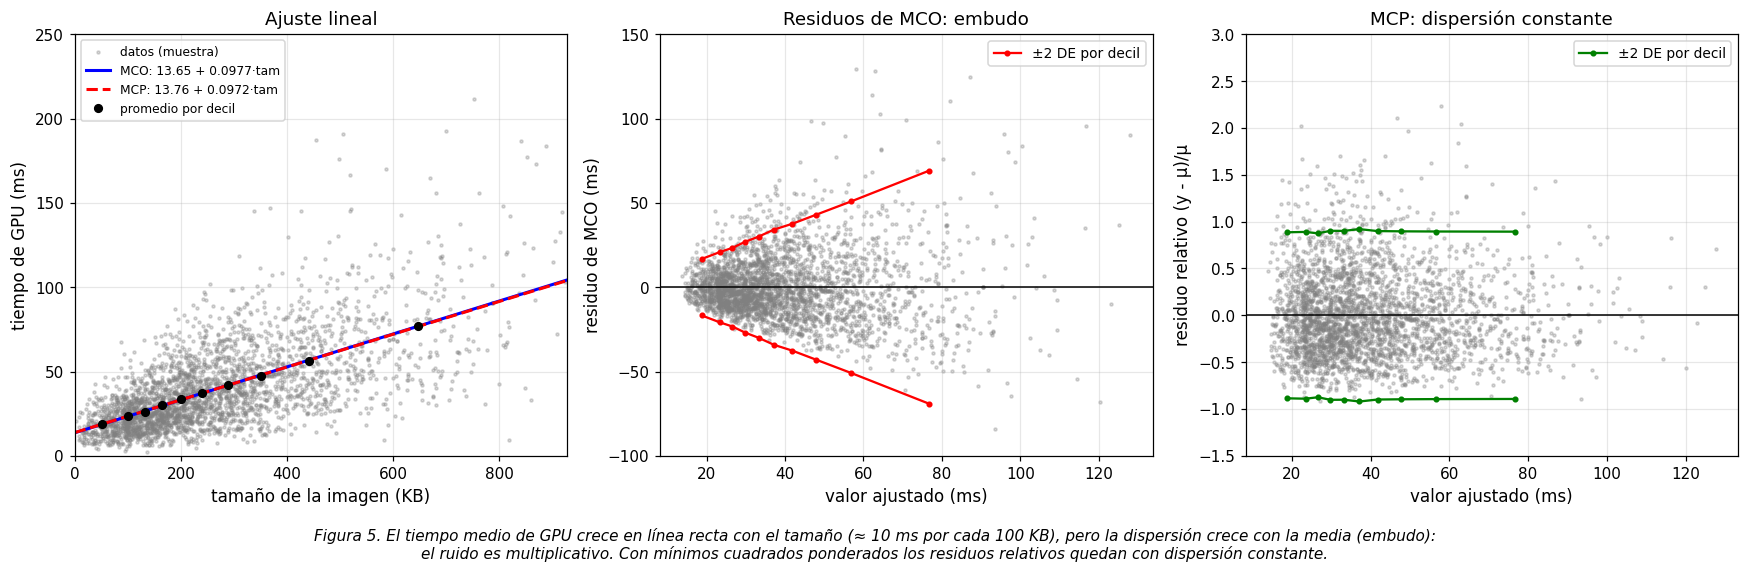

In [ ]:
# =====================================  FIGURA 5  =====================================
idx = rng.choice(n_d3, 3000, replace=False)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].scatter(x_d3[idx], y_d3[idx], s=4, alpha=0.3, color="gray", label="datos (muestra)")
xx = np.linspace(0, np.quantile(x_d3, 0.995), 100)
ax[0].plot(xx, beta_mco[0] + beta_mco[1] * xx, "b", lw=2, label=f"MCO: {beta_mco[0]:.2f} + {beta_mco[1]:.4f}·tam")
ax[0].plot(xx, beta_mcp[0] + beta_mcp[1] * xx, "r--", lw=2, label=f"MCP: {beta_mcp[0]:.2f} + {beta_mcp[1]:.4f}·tam")
ax[0].plot(lin.x, lin.y, "ko", ms=5, label="promedio por decil")
ax[0].set_xlim(0, xx.max()); ax[0].set_ylim(0, 250)
ax[0].set_xlabel("tamaño de la imagen (KB)"); ax[0].set_ylabel("tiempo de GPU (ms)"); ax[0].set_title("Ajuste lineal"); ax[0].legend(fontsize=8)
ax[1].scatter(ajuste[idx], res_mco[idx], s=4, alpha=0.3, color="gray")
ax[1].plot(het.ajustado, 2 * het.de_residuo, "r-o", ms=3, label="±2 DE por decil"); ax[1].plot(het.ajustado, -2 * het.de_residuo, "r-o", ms=3)
ax[1].axhline(0, color="k", lw=1); ax[1].set_ylim(-100, 150)
ax[1].set_xlabel("valor ajustado (ms)"); ax[1].set_ylabel("residuo de MCO (ms)"); ax[1].set_title("Residuos de MCO: embudo"); ax[1].legend()
aj_w = X_d3 @ beta_mcp
de_rel = pd.Series(pearson).groupby(pd.qcut(aj_w, 10, labels=False)).std()
ax[2].scatter(aj_w[idx], pearson[idx], s=4, alpha=0.3, color="gray")
cent = pd.Series(aj_w).groupby(pd.qcut(aj_w, 10, labels=False)).mean()
ax[2].plot(cent, 2 * de_rel, "g-o", ms=3, label="±2 DE por decil"); ax[2].plot(cent, -2 * de_rel, "g-o", ms=3)
ax[2].axhline(0, color="k", lw=1); ax[2].set_ylim(-1.5, 3)
ax[2].set_xlabel("valor ajustado (ms)"); ax[2].set_ylabel("residuo relativo (y - μ)/μ"); ax[2].set_title("MCP: dispersión constante"); ax[2].legend()
pie_de_figura(fig, 5, "El tiempo medio de GPU crece en línea recta con el tamaño (≈ 10 ms por cada 100 KB), pero la dispersión crece con la media (embudo):\n"
                      "el ruido es multiplicativo. Con mínimos cuadrados ponderados los residuos relativos quedan con dispersión constante.")
plt.tight_layout(); guardar_figura(fig, 5); plt.show()

**Conclusión D3.** El modelo ajustado resolviendo las ecuaciones normales es $\hat E[G \mid \text{tam}, \text{no caché}] = 13{,}6 + 0{,}0977\cdot\text{tam}$ ms ($R^2 \approx 0{,}45$): cada 100 KB agregan ≈ 9,8 ms sobre un costo fijo de ≈ 13,6 ms. **Se cumplen** la linealidad de la media, la independencia de los residuos y la ausencia de sesgo por la versión. **Se viola la varianza constante:** la desviación estándar de los residuos crece de ≈ 8 a ≈ 35 ms con coeficiente de variación constante ≈ 0,45. La **corrección** sale de la estructura multiplicativa (C2): MCP con pesos $1/\mu^2$, que deja los residuos relativos con dispersión constante. En el Montecarlo, el intervalo clásico de MCO para la pendiente cubre solo ≈ 68 % de las veces, no el 90 % nominal (su error estándar es demasiado pequeño), mientras que el de MCP cubre ≈ 90 % y la pendiente de MCP tiene ≈ 2,3 veces menos varianza. La recta corregida alimenta el simulador de la Parte G. **Aporta a P1 y P3.**

---
### D4. Covarianza y correlación entre tam_kb y gpu_ms (no cacheadas)
Valor esperado de una función conjunta (semana 14): $\text{Cov}(X, Y) = E[(X - E[X])(Y - E[Y])]$ y $\rho = \text{Cov}(X, Y)/(\sigma_X\sigma_Y)$, estimadas con sus versiones muestrales. Conexión con D3 y D2:
$$\hat\beta_1 = \frac{\widehat{\text{Cov}}(X,Y)}{s_X^2}, \qquad R^2 = r^2, \qquad r^2 \le \eta^2 = \frac{\text{Var}(E[Y \mid X])}{\text{Var}(Y)}.$$
La última desigualdad dice que la mejor recta no puede explicar más que la mejor función del tamaño (la esperanza condicional de D2).

In [ ]:
# Paso 1. Covarianza y correlación desde la definición, y las identidades con D3
dx, dy = x_d3 - x_d3.mean(), y_d3 - y_d3.mean()
cov_xy = (dx * dy).sum() / (n_d3 - 1)
r_xy = (dx * dy).sum() / np.sqrt((dx ** 2).sum() * (dy ** 2).sum())
print(f"Cov(tam_kb, gpu_ms) = {cov_xy:.2f} KB·ms | r = {r_xy:.4f}")
print(f"Identidad 1: Cov / Var(x) = {cov_xy / x_d3.var(ddof=1):.6f} = beta1 de MCO {beta_mco[1]:.6f}")
print(f"Identidad 2: r² = {r_xy ** 2:.6f} = R² de MCO {R2:.6f}")
print(f"Lectura: si el tamaño sube 1 DE ({x_d3.std(ddof=1):.0f} KB), la GPU sube en promedio r = {r_xy:.2f} DE ({r_xy * y_d3.std(ddof=1):.1f} ms)")

# Paso 2. r² frente a eta² (D2) con intervalos de tamaño cada vez más finos
d4 = pd.DataFrame({"x": x_d3, "y": y_d3})
print("\nFracción de la varianza explicada por el tamaño:")
print(f"  r² (mejor recta)               = {r_xy ** 2:.4f}")
for k_ in [3, 10, 20, 50]:
    grupos = d4.groupby(pd.qcut(d4.x, k_, labels=False)).y
    eta = ((grupos.size() / n_d3) * (grupos.mean() - y_d3.mean()) ** 2).sum() / y_d3.var(ddof=0)
    print(f"  eta² con {k_:3d} intervalos de tamaño = {eta:.4f}")
eta_clase_nc = tabla_vt.loc["clase de tamaño", "eta² = explicada"]

Cov(tam_kb, gpu_ms) = 3061.89 KB·ms | r = 0.6702
Identidad 1: Cov / Var(x) = 0.097704 = beta1 de MCO 0.097704
Identidad 2: r² = 0.449156 = R² de MCO 0.449156
Lectura: si el tamaño sube 1 DE (177 KB), la GPU sube en promedio r = 0.67 DE (17.3 ms)

Fracción de la varianza explicada por el tamaño:
  r² (mejor recta)               = 0.4492
  eta² con   3 intervalos de tamaño = 0.3217
  eta² con  10 intervalos de tamaño = 0.4135
  eta² con  20 intervalos de tamaño = 0.4314
  eta² con  50 intervalos de tamaño = 0.4425


**Conclusión D4.** La covarianza es positiva (≈ 3062 KB·ms): las imágenes más grandes tardan más. La correlación es $r \approx 0{,}67$: una asociación lineal fuerte pero lejos de 1. **Con D3:** la pendiente de MCO es exactamente $\text{Cov}/\text{Var}(x)$ y el $R^2$ es exactamente $r^2 \approx 0{,}45$. **Con D2:** las versiones de $\eta^2$ por intervalos son cotas inferiores del verdadero $\eta^2$ (promediar dentro de un intervalo pierde algo de la variación de $E[G\mid x]$); al afinar los intervalos suben 0,32 → 0,41 → 0,43 → 0,44 y se acercan a $r^2 = 0{,}45$ sin superarlo. Como $r^2 \le \eta^2$ siempre, eso dice que $\eta^2 \approx r^2$: **la esperanza condicional es prácticamente una recta** y la recta ya explica todo lo que el tamaño puede explicar. El 55 % restante no es falta de ajuste sino el ruido propio del cómputo (CV ≈ 0,45). Las 3 clases de D1 explican menos (≈ 0,32) porque dentro de cada clase $G$ sigue creciendo con el tamaño. **Aporta a P1.**

---
# Parte E — Monitoreo y decisión de alertas (12 pts)
`monitoreo.csv` tiene 6000 minutos de un entorno de pruebas con incidentes **inyectados**: la proporción de incidentes de ese archivo no es la de producción ($\pi = 0{,}004$). Por eso de ese archivo solo se estiman probabilidades **condicionadas al estado**, que no dependen de cuántos incidentes se inyectaron:
- **sensibilidad** $s = P(\text{alerta} \mid \text{incidente})$,
- **tasa de falsos positivos** $f = P(\text{alerta} \mid \text{sin incidente})$.

### E1. Sensibilidad y tasa de falsos positivos de las cuatro reglas
Cada una es una proporción binomial (semana 8), con intervalo de Wald $\hat p \pm z\sqrt{\hat p(1-\hat p)/n}$ (TLC). La aproximación exige $n\hat p \ge 10$ y $n(1-\hat p) \ge 10$; se revisa y, como respaldo, se da también el intervalo de **Wilson**, que sale de resolver la misma desigualdad del TLC sin reemplazar $p$ por $\hat p$ en el error estándar (su cobertura se compara en F4). Reglas combinadas, por **inclusión-exclusión** (semana 1):
$$P(D_1 \cup D_2 \mid \cdot) = P(D_1 \mid \cdot) + P(D_2 \mid \cdot) - P(D_1 \cap D_2 \mid \cdot).$$

In [ ]:
# Paso 1. Datos, auditoría y las cuatro reglas
mon = pd.read_csv(RUTA_DATOS / "monitoreo.csv")
print(f"Filas: {len(mon)} | ausentes: {int(mon.isna().sum().sum())} | valores: "
      f"{ {c_: sorted(mon[c_].unique().tolist()) for c_ in ['D1', 'D2', 'incidente']} } | minutos consecutivos: {bool((mon.minuto.diff().dropna() == 1).all())}")
incid = mon.incidente.to_numpy() == 1
d1, d2 = mon.D1.to_numpy() == 1, mon.D2.to_numpy() == 1
REGLAS = {"D1": d1, "D2": d2, "D1 y D2": d1 & d2, "D1 o D2": d1 | d2}
n_inc, n_norm = int(incid.sum()), int((~incid).sum())
print(f"Minutos con incidente: {n_inc} | normales: {n_norm} | proporción en pruebas = {n_inc / len(mon):.4f} (producción: pi = {pi_incidentes})")
print(f"Independencia entre minutos: corr(incidente_t, incidente_t+1) = {np.corrcoef(incid[:-1], incid[1:])[0, 1]:.4f}; "
      f"corr de falsas alarmas de 'D1 o D2' consecutivas = {np.corrcoef((d1 | d2)[:-1] & ~incid[:-1], (d1 | d2)[1:] & ~incid[1:])[0, 1]:.4f}")

def ic_wilson(k, n):
    """Wilson: resolver |p_hat - p| <= z sqrt(p(1-p)/n) para p (misma aproximación normal, sin reemplazar p por p_hat)."""
    p_ = k / n; centro = (p_ + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    semi = z * np.sqrt(p_ * (1 - p_) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centro - semi, centro + semi

Filas: 6000 | ausentes: 0 | valores: {'D1': [0, 1], 'D2': [0, 1], 'incidente': [0, 1]} | minutos consecutivos: True
Minutos con incidente: 484 | normales: 5516 | proporción en pruebas = 0.0807 (producción: pi = 0.004)
Independencia entre minutos: corr(incidente_t, incidente_t+1) = 0.0044; corr de falsas alarmas de 'D1 o D2' consecutivas = -0.0139


In [ ]:
# Paso 2. Matriz de confusión e intervalos de cada regla
SENS, TFP, CONF = {}, {}, {}
filas = []
for nombre, a_ in REGLAS.items():
    VP, FN, FP, VN = int((a_ & incid).sum()), int((~a_ & incid).sum()), int((a_ & ~incid).sum()), int((~a_ & ~incid).sum())
    CONF[nombre] = dict(VP=VP, FN=FN, FP=FP, VN=VN)
    SENS[nombre], TFP[nombre] = VP / n_inc, FP / n_norm
    s_li, s_ls = ic_proporcion(VP, n_inc); f_li, f_ls = ic_proporcion(FP, n_norm); w_li, w_ls = ic_wilson(FP, n_norm)
    filas.append({"regla": nombre, "VP/FN/FP/VN": f"{VP}/{FN}/{FP}/{VN}",
                  "sensibilidad": SENS[nombre], "IC sens (Wald)": f"[{s_li:.3f}; {s_ls:.3f}]",
                  "TFP": TFP[nombre], "IC TFP (Wald)": f"[{f_li:.4f}; {f_ls:.4f}]", "IC TFP (Wilson)": f"[{w_li:.4f}; {w_ls:.4f}]",
                  "mín(np, n(1-p))": min(VP, FN, FP)})
tabla_E1 = pd.DataFrame(filas).set_index("regla")
print(tabla_E1.round(4).to_string())
print("\nInclusión-exclusión (exacta también con las frecuencias):")
for medida, dic in [("sensibilidad", SENS), ("TFP", TFP)]:
    print(f"  {medida}: P(D1 o D2) = {dic['D1 o D2']:.6f} = {dic['D1']:.6f} + {dic['D2']:.6f} - {dic['D1 y D2']:.6f} = {dic['D1'] + dic['D2'] - dic['D1 y D2']:.6f}")

             VP/FN/FP/VN  sensibilidad  IC sens (Wald)     TFP     IC TFP (Wald)   IC TFP (Wilson)  mín(np, n(1-p))
regla                                                                                                              
D1        441/43/37/5479        0.9112  [0.890; 0.932]  0.0067  [0.0049; 0.0085]  [0.0051; 0.0088]               37
D2       366/118/56/5460        0.7562  [0.724; 0.788]  0.0102  [0.0079; 0.0124]  [0.0082; 0.0126]               56
D1 y D2  335/149/11/5505        0.6921  [0.658; 0.727]  0.0020  [0.0010; 0.0030]  [0.0012; 0.0033]               11
D1 o D2   472/12/82/5434        0.9752  [0.964; 0.987]  0.0149  [0.0122; 0.0175]  [0.0124; 0.0178]               12

Inclusión-exclusión (exacta también con las frecuencias):
  sensibilidad: P(D1 o D2) = 0.975207 = 0.911157 + 0.756198 - 0.692149 = 0.975207
  TFP: P(D1 o D2) = 0.014866 = 0.006708 + 0.010152 - 0.001994 = 0.014866


**Conclusión E1.** "D1 o D2" es la regla más sensible (≈ 0,975) pero la que más falsas alarmas da (≈ 1,5 % de los minutos normales); "D1 y D2" es la más específica (≈ 0,2 %) pero pierde ≈ 31 % de los incidentes. D1 domina a D2: detecta más (0,91 frente a 0,76) con menos falsas alarmas (0,67 % frente a 1,0 %). Todas las celdas tienen al menos 11 casos, así que el intervalo de Wald es aceptable; para la TFP de "D1 y D2" (solo 11 falsas alarmas) Wilson se corre un poco hacia arriba ([0,0012; 0,0033] frente a [0,0010; 0,0030]), que es lo esperable cuando $np$ es pequeño (F4).

---
### E2. Probabilidad de incidente real dada cada alerta, en producción
Por el **teorema de Bayes** con la ley de **probabilidad total** en el denominador (semana 3):
$$\text{VPP} = P(I \mid A) = \frac{s\,\pi}{s\,\pi + f\,(1 - \pi)}.$$
**Por qué no se lee directamente de `monitoreo.csv`:** en las pruebas los incidentes se inyectaron en ≈ 8,1 % de los minutos, 20 veces más que en producción. La fracción de alertas que son reales en el archivo depende de esa proporción artificial; $s$ y $f$ no, porque están condicionadas al estado. Por eso se toman $s$ y $f$ del archivo y se combinan con el $\pi$ real.

**Incertidumbre:** $s$ y $f$ son estimaciones. Se propaga por **Montecarlo**: se simulan los conteos $VP^* \sim \text{Bin}(n_{inc}, \hat s)$ y $FP^* \sim \text{Bin}(n_{norm}, \hat f)$, se recalcula el VPP y el IC 90 % son los percentiles 5 y 95 %. Las cuatro reglas se simulan desde las **cuatro combinaciones** (D1, D2) de cada estado (multinomial, semana 13), para no suponer independencia entre detectores.

In [ ]:
# Paso 1. VPP en producción (Bayes) y lo que daría el archivo de pruebas directamente
def vpp(s, f, prev):
    return s * prev / (s * prev + f * (1 - prev))

# Paso 2. Montecarlo de la incertidumbre: conteos simulados de las 4 combinaciones (D1, D2) en cada estado
R_E2 = 20_000
COMBOS = [(False, False), (False, True), (True, False), (True, True)]
p_comb_inc = np.array([np.mean((d1 == a) & (d2 == b) & incid) / incid.mean() for a, b in COMBOS])
p_comb_nor = np.array([np.mean((d1 == a) & (d2 == b) & ~incid) / (~incid).mean() for a, b in COMBOS])
sim_inc = rng.multinomial(n_inc, p_comb_inc, size=R_E2) / n_inc
sim_nor = rng.multinomial(n_norm, p_comb_nor, size=R_E2) / n_norm
def reglas_desde_combos(p_):                                    # columnas: 00, 01, 10, 11
    return {"D1": p_[:, 2] + p_[:, 3], "D2": p_[:, 1] + p_[:, 3], "D1 y D2": p_[:, 3], "D1 o D2": p_[:, 1] + p_[:, 2] + p_[:, 3]}
s_sim, f_sim = reglas_desde_combos(sim_inc), reglas_desde_combos(sim_nor)

filas = []
for nombre, a_ in REGLAS.items():
    v_sim = vpp(s_sim[nombre], f_sim[nombre], pi_incidentes)
    filas.append({"regla": nombre, "VPP producción": vpp(SENS[nombre], TFP[nombre], pi_incidentes),
                  "IC 90% (Montecarlo)": f"[{np.quantile(v_sim, alpha / 2):.3f}; {np.quantile(v_sim, 1 - alpha / 2):.3f}]",
                  "VPP leído de monitoreo.csv": incid[a_].mean(),
                  "falsas alarmas por cada real": (1 - vpp(SENS[nombre], TFP[nombre], pi_incidentes)) / vpp(SENS[nombre], TFP[nombre], pi_incidentes)})
tabla_E2 = pd.DataFrame(filas).set_index("regla")
print(tabla_E2.round(4).to_string())
print(f"\nEn pruebas P(I) = {incid.mean():.4f}, en producción pi = {pi_incidentes}: con la misma s y f, el VPP cae porque hay muchos más minutos normales donde equivocarse.")

         VPP producción IC 90% (Montecarlo)  VPP leído de monitoreo.csv  falsas alarmas por cada real
regla                                                                                                
D1               0.3530      [0.299; 0.426]                      0.9226                        1.8331
D2               0.2303      [0.196; 0.277]                      0.8673                        3.3429
D1 y D2          0.5823      [0.477; 0.721]                      0.9682                        0.7174
D1 o D2          0.2085      [0.182; 0.243]                      0.8520                        3.7957

En pruebas P(I) = 0.0807, en producción pi = 0.004: con la misma s y f, el VPP cae porque hay muchos más minutos normales donde equivocarse.


In [ ]:
# Paso 3. Verificación por Montecarlo de Bayes: se simulan 10^7 minutos de producción sin usar la fórmula
M_E2 = 10_000_000
inc_sim = rng.random(M_E2) < pi_incidentes
combo_sim = np.where(inc_sim, rng.choice(4, M_E2, p=p_comb_inc), rng.choice(4, M_E2, p=p_comb_nor))
a1_sim, a2_sim = np.isin(combo_sim, [2, 3]), np.isin(combo_sim, [1, 3])
for nombre, a_ in {"D1": a1_sim, "D2": a2_sim, "D1 y D2": a1_sim & a2_sim, "D1 o D2": a1_sim | a2_sim}.items():
    k_, n_ = int((inc_sim & a_).sum()), int(a_.sum())
    print(f"  {nombre:8s}: fracción de alertas reales simulada = {texto_ic(k_ / n_, *ic_proporcion(k_, n_), 'TLC', 4)} | "
          f"Bayes con la prevalencia realizada {inc_sim.mean():.5f}: {vpp(SENS[nombre], TFP[nombre], inc_sim.mean()):.4f}")

  D1      : fracción de alertas reales simulada = 0.3532  [0.3507; 0.3556]  (IC 90%, TLC) | Bayes con la prevalencia realizada 0.00401: 0.3535
  D2      : fracción de alertas reales simulada = 0.2313  [0.2294; 0.2332]  (IC 90%, TLC) | Bayes con la prevalencia realizada 0.00401: 0.2307
  D1 y D2 : fracción de alertas reales simulada = 0.5838  [0.5801; 0.5875]  (IC 90%, TLC) | Bayes con la prevalencia realizada 0.00401: 0.5829
  D1 o D2 : fracción de alertas reales simulada = 0.2090  [0.2075; 0.2105]  (IC 90%, TLC) | Bayes con la prevalencia realizada 0.00401: 0.2089


**Conclusión E2.** En producción, **la mayoría de las alertas son falsas** aunque los detectores sean buenos: con D1 solo ≈ 35 % de las alertas corresponde a un incidente real, con "D1 o D2" ≈ 21 %, y la mejor es "D1 y D2" con ≈ 58 % [≈ 0,48; 0,72]. En `monitoreo.csv` las mismas reglas parecen mucho mejores (≈ 0,91–0,97) solo porque allí los incidentes son 20 veces más frecuentes. La simulación de 10⁷ minutos reproduce los valores de Bayes. **Aporta a P1 y P3.**

---
### E3. ¿D1 y D2 son condicionalmente independientes dado el estado?
**Definición** (semana 3): $D_1 \perp D_2 \mid I$ si $P(D_1 \cap D_2 \mid I = i) = P(D_1 \mid I = i)\,P(D_2 \mid I = i)$ para $i = 0, 1$. Se calcula en cada estado el cociente
$$\text{cociente}_i = \frac{\hat P(D_1 \cap D_2 \mid I = i)}{\hat P(D_1 \mid I = i)\,\hat P(D_2 \mid I = i)} \quad (= 1 \text{ bajo independencia}).$$
**Montecarlo bajo la hipótesis de independencia:** en cada estado se simulan $D_1$ y $D_2$ **por separado** con sus probabilidades marginales, en el mismo número de minutos, y se mira con qué frecuencia el cociente simulado se aleja de 1 tanto como el observado. Además se da un intervalo para el cociente observado (Montecarlo de la multinomial de E2).

In [ ]:
# Paso 1. Cociente observado / independencia en cada estado
filas, COC = [], {}
for nombre_e, m_, n_e, sims in [("con incidente (I = 1)", incid, n_inc, sim_inc), ("normal (I = 0)", ~incid, n_norm, sim_nor)]:
    p1, p2, p12 = d1[m_].mean(), d2[m_].mean(), (d1 & d2)[m_].mean()
    COC[nombre_e] = p12 / (p1 * p2)
    coc_ic = sims[:, 3] / ((sims[:, 2] + sims[:, 3]) * (sims[:, 1] + sims[:, 3]))
    # Montecarlo bajo independencia condicional: D1 y D2 se sortean por separado
    s1 = rng.binomial(1, p1, size=(4000, n_e)).astype(bool); s2 = rng.binomial(1, p2, size=(4000, n_e)).astype(bool)
    coc_ind = (s1 & s2).mean(axis=1) / (s1.mean(axis=1) * s2.mean(axis=1))
    filas.append({"estado": nombre_e, "minutos": n_e, "ambos": int((d1 & d2 & m_).sum()), "P(D1|estado)": p1, "P(D2|estado)": p2,
                  "P(ambos|estado)": p12, "producto": p1 * p2, "cociente": COC[nombre_e],
                  "IC cociente (Montecarlo)": f"[{np.quantile(coc_ic, alpha / 2):.2f}; {np.quantile(coc_ic, 1 - alpha / 2):.2f}]",
                  "rango 90% si indep.": f"[{np.nanquantile(coc_ind, alpha / 2):.2f}; {np.nanquantile(coc_ind, 1 - alpha / 2):.2f}]",
                  "frac. sim. tan lejos de 1": float(np.nanmean(np.abs(coc_ind - 1) >= abs(COC[nombre_e] - 1)))})
tabla_E3 = pd.DataFrame(filas).set_index("estado")
print(tabla_E3.T.to_string())

estado                    con incidente (I = 1)  normal (I = 0)
minutos                                     484            5516
ambos                                       335              11
P(D1|estado)                           0.911157        0.006708
P(D2|estado)                           0.756198        0.010152
P(ambos|estado)                        0.692149        0.001994
producto                               0.689015        0.000068
cociente                               1.004548       29.283784
IC cociente (Montecarlo)           [0.99; 1.02]  [18.39; 41.79]
rango 90% si indep.                [0.99; 1.01]    [0.00; 4.32]
frac. sim. tan lejos de 1               0.58025             0.0


**Paso 2. Efecto sobre E2.** Si se hubiera **supuesto** independencia condicional, las reglas combinadas se calcularían con productos: $s_\wedge = s_1 s_2$, $f_\wedge = f_1 f_2$ y, por inclusión-exclusión, $s_\vee = s_1 + s_2 - s_1 s_2$, $f_\vee = f_1 + f_2 - f_1 f_2$. Se compara el VPP resultante con el obtenido de la conjunta observada, con un intervalo de Montecarlo para la diferencia.

In [ ]:
# Paso 2. VPP de las reglas combinadas: conjunta observada vs supuesto de independencia condicional
def combinadas_indep(s1, s2, f1, f2):
    return {"D1 y D2": (s1 * s2, f1 * f2), "D1 o D2": (s1 + s2 - s1 * s2, f1 + f2 - f1 * f2)}
ind_hat = combinadas_indep(SENS["D1"], SENS["D2"], TFP["D1"], TFP["D2"])
ind_sim = combinadas_indep(s_sim["D1"], s_sim["D2"], f_sim["D1"], f_sim["D2"])
filas = []
for regla in ["D1 y D2", "D1 o D2"]:
    v_obs, v_ind = vpp(SENS[regla], TFP[regla], pi_incidentes), vpp(*ind_hat[regla], pi_incidentes)
    dif = vpp(*ind_sim[regla], pi_incidentes) - vpp(s_sim[regla], f_sim[regla], pi_incidentes)
    filas.append({"regla": regla, "TFP observada": TFP[regla], "TFP si indep.": ind_hat[regla][1],
                  "VPP observado": v_obs, "VPP si indep.": v_ind, "diferencia": v_ind - v_obs,
                  "IC diferencia (Montecarlo)": f"[{np.quantile(dif, alpha / 2):.3f}; {np.quantile(dif, 1 - alpha / 2):.3f}]",
                  "falsas/día observado": 1440 * (1 - pi_incidentes) * TFP[regla], "falsas/día si indep.": 1440 * (1 - pi_incidentes) * ind_hat[regla][1]})
tabla_E3b = pd.DataFrame(filas).set_index("regla")
print(tabla_E3b.T.to_string())

regla                              D1 y D2           D1 o D2
TFP observada                     0.001994          0.014866
TFP si indep.                     0.000068          0.016792
VPP observado                     0.582272           0.20852
VPP si indep.                     0.975981          0.189618
diferencia                        0.393709         -0.018902
IC diferencia (Montecarlo)  [0.260; 0.493]  [-0.028; -0.011]
falsas/día observado               2.86016         21.321189
falsas/día si indep.               0.09767         24.083678


**Conclusión E3.** **Con incidente**, D1 y D2 se comportan como independientes (cociente ≈ 1,0, dentro del rango que produce la independencia). **Sin incidente no lo son:** las falsas alarmas de ambos coinciden ≈ 29 veces más de lo que daría la independencia, un valor que en las simulaciones independientes nunca aparece. Interpretación: algo distinto de un incidente (por ejemplo, un pico de carga) dispara los dos detectores a la vez. **Efecto:** suponer independencia haría creer que "D1 y D2" casi no da falsas alarmas (≈ 0,1 por día en vez de ≈ 2,9) y que su VPP es ≈ 0,98 en lugar de ≈ 0,58, un error de ≈ +0,39 [≈ 0,26; 0,49]; para "D1 o D2" el error es pequeño. **Por eso E2 y E4 usan la conjunta observada.** **Aporta a P3.**

---
### E4. Falsas alarmas por día y elección de la regla
En un día hay 1440 minutos. Cada minuto es normal con probabilidad $1 - \pi$ y, si es normal, la regla da falsa alarma con probabilidad $f$. Si los minutos son independientes (comprobado en E1), el número de falsas alarmas del día es
$$X \sim \text{Binomial}\big(1440,\ p_{FA}\big), \quad p_{FA} = (1-\pi)f, \qquad P(X \le k_{\max}) = \sum_{k=0}^{k_{\max}} \binom{1440}{k} p_{FA}^k (1-p_{FA})^{1440-k} \approx \sum_{k=0}^{k_{\max}} e^{-\lambda}\frac{\lambda^k}{k!},\ \lambda = 1440\,p_{FA}$$
(la binomial con $n$ grande y $p$ pequeño se aproxima por Poisson, semana 9). Exigencia: $P(X \le k_{\max} = 5) \ge 0{,}90$. Como $P(X \le 5)$ baja cuando $f$ sube, la exigencia equivale a $f \le f^*$, con $f^*$ el valor en que la probabilidad es exactamente 0,90.

**Propagación de la incertidumbre:** $f$ es una estimación. Con las 20 000 réplicas de Montecarlo de E2 se recalcula $P(X \le 5)$ y se reporta su intervalo y la **probabilidad de que la regla realmente cumpla** (fracción de réplicas con $P \ge 0{,}90$).

In [ ]:
# Paso 1. P(X <= k_max) por regla, con la incertidumbre de f propagada por Montecarlo
MIN_DIA, NIVEL_GUARDIA = 1440, 0.90
def p_cumple(f):
    return stats.binom.cdf(k_max, MIN_DIA, (1 - pi_incidentes) * np.asarray(f))
f_estrella = optimize.brentq(lambda f: p_cumple(f) - NIVEL_GUARDIA, 1e-6, 0.05)
print(f"Umbral: la exigencia se cumple si y solo si f <= f* = {f_estrella:.5f} (media de {MIN_DIA * (1 - pi_incidentes) * f_estrella:.2f} falsas/día)")
filas = []
for regla in REGLAS:
    P_sim = p_cumple(f_sim[regla])
    filas.append({"regla": regla, "TFP": TFP[regla], "falsas/día (media)": MIN_DIA * (1 - pi_incidentes) * TFP[regla],
                  "P(X<=5) binomial": float(p_cumple(TFP[regla])),
                  "P(X<=5) Poisson": stats.poisson.cdf(k_max, MIN_DIA * (1 - pi_incidentes) * TFP[regla]),
                  "IC 90% (Montecarlo)": f"[{np.quantile(P_sim, alpha / 2):.3f}; {np.quantile(P_sim, 1 - alpha / 2):.3f}]",
                  "P(la regla cumple)": float(np.mean(P_sim >= NIVEL_GUARDIA)), "sensibilidad": SENS[regla],
                  "VPP": vpp(SENS[regla], TFP[regla], pi_incidentes)})
tabla_E4 = pd.DataFrame(filas).set_index("regla")
print(tabla_E4.round(4).to_string())

Umbral: la exigencia se cumple si y solo si f <= f* = 0.00220 (media de 3.15 falsas/día)
            TFP  falsas/día (media)  P(X<=5) binomial  P(X<=5) Poisson IC 90% (Montecarlo)  P(la regla cumple)  sensibilidad     VPP
regla                                                                                                                               
D1       0.0067              9.6205            0.0822           0.0829      [0.017; 0.297]              0.0000        0.9112  0.3530
D2       0.0102             14.5608            0.0037           0.0038      [0.000; 0.028]              0.0000        0.7562  0.2303
D1 y D2  0.0020              2.8602            0.9297           0.9295      [0.717; 0.995]              0.6901        0.6921  0.5823
D1 o D2  0.0149             21.3212            0.0000           0.0000      [0.000; 0.000]              0.0000        0.9752  0.2085


In [ ]:
# Paso 2. Verificación por Montecarlo de días completos, minuto a minuto (sin la fórmula binomial)
DIAS_SIM, LOTE = 40_000, 4_000
falsas_sim = {r_: np.empty(DIAS_SIM, dtype=int) for r_ in REGLAS}
for i0 in range(0, DIAS_SIM, LOTE):
    inc_m = rng.random((LOTE, MIN_DIA)) < pi_incidentes
    comb_m = np.where(inc_m, rng.choice(4, (LOTE, MIN_DIA), p=p_comb_inc), rng.choice(4, (LOTE, MIN_DIA), p=p_comb_nor))
    a1, a2 = np.isin(comb_m, [2, 3]), np.isin(comb_m, [1, 3])
    for regla, a_ in {"D1": a1, "D2": a2, "D1 y D2": a1 & a2, "D1 o D2": a1 | a2}.items():
        falsas_sim[regla][i0:i0 + LOTE] = (a_ & ~inc_m).sum(axis=1)
for regla in REGLAS:
    k_ = int(np.sum(falsas_sim[regla] <= k_max))
    print(f"  {regla:8s}: media = {falsas_sim[regla].mean():6.2f} falsas/día | P(X <= {k_max}) simulada = "
          f"{texto_ic(k_ / DIAS_SIM, *np.clip(ic_proporcion(k_, DIAS_SIM), 0, 1), 'TLC', 4)} | binomial = {float(p_cumple(TFP[regla])):.4f}")

  D1      : media =   9.61 falsas/día | P(X <= 5) simulada = 0.0843  [0.0820; 0.0865]  (IC 90%, TLC) | binomial = 0.0822
  D2      : media =  14.55 falsas/día | P(X <= 5) simulada = 0.0035  [0.0030; 0.0040]  (IC 90%, TLC) | binomial = 0.0037
  D1 y D2 : media =   2.85 falsas/día | P(X <= 5) simulada = 0.9295  [0.9274; 0.9316]  (IC 90%, TLC) | binomial = 0.9297
  D1 o D2 : media =  21.30 falsas/día | P(X <= 5) simulada = 0.0001  [0.0000; 0.0001]  (IC 90%, TLC) | binomial = 0.0000


---
## FIGURA 6 · Falsas alarmas por día y cumplimiento de la exigencia (ítem E4)
Izquierda: $P(X \le 5)$ en función de $f$; cada regla aparece con su intervalo de $f$; la zona verde es la que cumple. Derecha: distribución del número de falsas alarmas por día de cada regla.

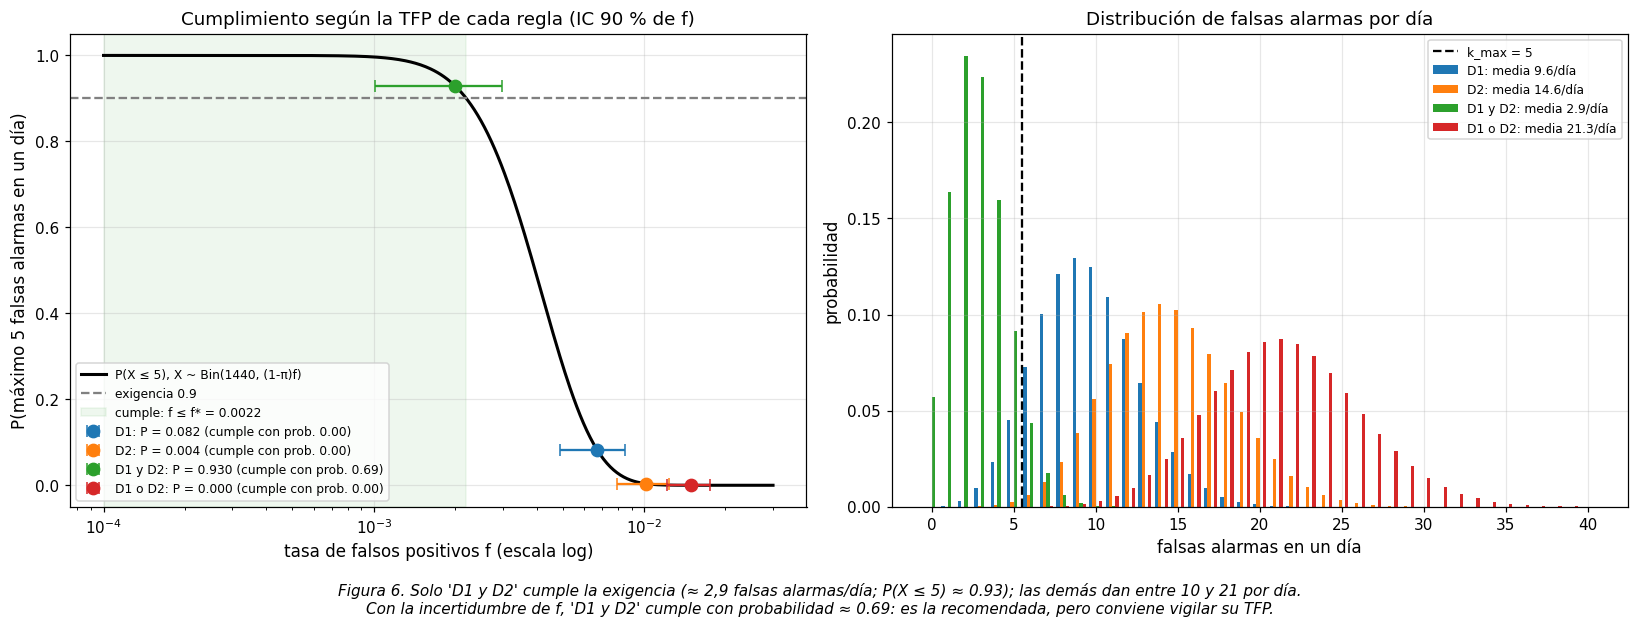

In [ ]:
# =====================================  FIGURA 6  =====================================
COLORES_E = {"D1": "tab:blue", "D2": "tab:orange", "D1 y D2": "tab:green", "D1 o D2": "tab:red"}
fig, ax = plt.subplots(1, 2, figsize=(15, 5.3))
f_grid = np.logspace(-4, np.log10(0.03), 400)
ax[0].semilogx(f_grid, p_cumple(f_grid), color="black", lw=2, label=f"P(X ≤ {k_max}), X ~ Bin(1440, (1-π)f)")
ax[0].axhline(NIVEL_GUARDIA, color="gray", ls="--", label=f"exigencia {NIVEL_GUARDIA}")
ax[0].axvspan(1e-4, f_estrella, color="tab:green", alpha=0.08, label=f"cumple: f ≤ f* = {f_estrella:.4f}")
for regla in REGLAS:
    li, ls = ic_proporcion(CONF[regla]["FP"], n_norm)
    y_ = float(p_cumple(TFP[regla]))
    ax[0].errorbar(TFP[regla], y_, xerr=[[TFP[regla] - li], [ls - TFP[regla]]], fmt="o", ms=8, capsize=4, color=COLORES_E[regla],
                   label=f"{regla}: P = {y_:.3f} (cumple con prob. {tabla_E4.loc[regla, 'P(la regla cumple)']:.2f})")
ax[0].set_xlabel("tasa de falsos positivos f (escala log)"); ax[0].set_ylabel(f"P(máximo {k_max} falsas alarmas en un día)")
ax[0].set_title("Cumplimiento según la TFP de cada regla (IC 90 % de f)"); ax[0].legend(fontsize=8, loc="lower left")
k_vals = np.arange(0, 41)
for j_, regla in enumerate(REGLAS):
    ax[1].bar(k_vals + (j_ - 1.5) * 0.2, stats.binom.pmf(k_vals, MIN_DIA, (1 - pi_incidentes) * TFP[regla]), width=0.2,
              color=COLORES_E[regla], label=f"{regla}: media {MIN_DIA * (1 - pi_incidentes) * TFP[regla]:.1f}/día")
ax[1].axvline(k_max + 0.5, color="black", ls="--", label=f"k_max = {k_max}")
ax[1].set_xlabel("falsas alarmas en un día"); ax[1].set_ylabel("probabilidad"); ax[1].set_title("Distribución de falsas alarmas por día"); ax[1].legend(fontsize=8)
pie_de_figura(fig, 6, f"Solo 'D1 y D2' cumple la exigencia (≈ 2,9 falsas alarmas/día; P(X ≤ {k_max}) ≈ {float(p_cumple(TFP['D1 y D2'])):.2f}); las demás dan entre 10 y 21 por día.\n"
                      f"Con la incertidumbre de f, 'D1 y D2' cumple con probabilidad ≈ {tabla_E4.loc['D1 y D2', 'P(la regla cumple)']:.2f}: es la recomendada, pero conviene vigilar su TFP.")
plt.tight_layout(); guardar_figura(fig, 6); plt.show()

**Conclusión E4.** La exigencia equivale a $f \le f^* \approx 0{,}0022$ (≈ 3,2 falsas alarmas/día en promedio). **Solo "D1 y D2" la cumple**: ≈ 2,9 falsas alarmas/día y $P(X \le 5) \approx 0{,}93$; D1, D2 y "D1 o D2" dan 10, 15 y 21 falsas alarmas/día y prácticamente nunca cumplen. **Con la incertidumbre propagada**, el intervalo de $P(X \le 5)$ para "D1 y D2" llega por debajo de 0,90 (≈ 0,72) y la regla cumple en ≈ 7 de cada 10 réplicas: la conclusión es razonable pero no segura, porque se basa en solo 11 falsas alarmas observadas. **Recomendación:** adoptar "D1 y D2" (VPP ≈ 0,58, la mejor), con dos condiciones: (1) aceptar que pierde ≈ 31 % de los incidentes, por lo que D1 sola debe quedar como aviso de baja prioridad sin despertar a nadie; (2) reestimar la TFP con datos de producción. **Aporta a P3.**

---
# Parte F — Inferencia, distribuciones muestrales y comparación de versiones (16 pts)
### F1. Distribución muestral de la media de la latencia
**Población elegida.** La latencia es una suma de piezas con leyes distintas, $L = \text{red} + \text{espera} + G$: un 34 % de solicitudes sin GPU (C1), cola derecha larga y ningún modelo paramétrico sencillo que le ajuste. Por eso la población es la **distribución empírica** de las latencias del régimen estable: cada muestra simulada se toma **con reemplazo** de esos valores (Montecarlo, semana 2). Con ≈ 28 000 datos, la empírica reproduce bien la forma real, incluida la cola, y su media $\mu$ se conoce exactamente, lo que permite medir la cobertura.

**Lo que dice la teoría** (semanas 15 y 16). Si $L$ tiene media $\mu$, desviación $\sigma$, sesgo $\gamma_1$ y curtosis en exceso $\gamma_2$, para la media de $n$ valores independientes:
$$E[\bar L_n] = \mu,\qquad \text{DE}(\bar L_n) = \frac{\sigma}{\sqrt n},\qquad \gamma_1(\bar L_n) = \frac{\gamma_1}{\sqrt n},\qquad \gamma_2(\bar L_n) = \frac{\gamma_2}{n}.$$
El TLC dice que $\bar L_n$ se vuelve normal; las dos últimas fórmulas dicen **qué tan rápido**: el sesgo baja como $1/\sqrt n$, así que en una población asimétrica la normalidad llega despacio. La **cobertura** del intervalo $\bar L_n \pm z\,s/\sqrt n$ es la fracción de muestras cuyo intervalo contiene $\mu$.

In [ ]:
# Paso 1. Población (empírica del régimen estable) y sus momentos
pob_L = df_estable.latencia_ms.to_numpy()
mu_pob, sig_pob = pob_L.mean(), pob_L.std(ddof=0)
g1_pob, g2_pob = stats.skew(pob_L), stats.kurtosis(pob_L)
objetivo_cob = nivel_confianza - 0.01
print(f"Población: {len(pob_L)} latencias | mu = {mu_pob:.3f} ms, sigma = {sig_pob:.3f} ms, sesgo = {g1_pob:.3f}, curtosis exc. = {g2_pob:.3f}")
print(f"z = {z:.4f}; cobertura objetivo >= {objetivo_cob:.2f}")

# Paso 2. Distribución muestral de la media para n en {5, 30, 200, 2000}
R_F1, N_F1 = 20_000, [5, 30, 200, 2000]
medias_F1, filas = {}, []
for n_ in N_F1:
    medias, cubre = np.empty(R_F1), np.empty(R_F1, dtype=bool)
    for ini in range(0, R_F1, 2000):
        X_ = rng.choice(pob_L, size=(2000, n_))
        m_, s_ = X_.mean(axis=1), X_.std(axis=1, ddof=1)
        medias[ini:ini + 2000] = m_
        cubre[ini:ini + 2000] = np.abs(m_ - mu_pob) <= z * s_ / np.sqrt(n_)
    medias_F1[n_] = medias
    filas.append({"n": n_, "media de x̄": medias.mean(), "DE simulada": medias.std(ddof=1), "DE teórica σ/√n": sig_pob / np.sqrt(n_),
                  "sesgo sim.": stats.skew(medias), "sesgo teór.": g1_pob / np.sqrt(n_),
                  "curtosis sim.": stats.kurtosis(medias), "curtosis teór.": g2_pob / n_, "cobertura IC normal": cubre.mean()})
tabla_F1 = pd.DataFrame(filas).set_index("n")
print(f"\nDistribución muestral de la media (R = {R_F1} réplicas por n):"); print(tabla_F1.round(4).to_string())

Población: 27970 latencias | mu = 54.459 ms, sigma = 31.250 ms, sesgo = 1.460, curtosis exc. = 3.454
z = 1.6449; cobertura objetivo >= 0.89

Distribución muestral de la media (R = 20000 réplicas por n):
      media de x̄  DE simulada  DE teórica σ/√n  sesgo sim.  sesgo teór.  curtosis sim.  curtosis teór.  cobertura IC normal
n                                                                                                                           
5         54.4501      14.0200          13.9755      0.6544       0.6529         0.6307          0.6908               0.7963
30        54.5285       5.7013           5.7055      0.2772       0.2666         0.1826          0.1151               0.8796
200       54.4621       2.1972           2.2097      0.1014       0.1032        -0.0307          0.0173               0.8984
2000      54.4493       0.7046           0.6988      0.0222       0.0326         0.0025          0.0017               0.8974


**Paso 3. Menor $n$ con cobertura suficiente.** La cobertura se estima en una rejilla fina de $n$ con $R = 40\,000$ réplicas por punto (error de Montecarlo $\approx \sqrt{0{,}9\cdot0{,}1/40\,000} \approx 0{,}0015$). Como la curva sube con $n$ pero con ruido, $n^*$ es el menor $n$ **a partir del cual** todas las coberturas de la rejilla superan el objetivo.

In [ ]:
# Paso 3. Cobertura del IC normal en una rejilla de n y menor n que cumple
R_COB = 40_000
rejilla_n = np.array([5, 10, 15, 20, 25, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 140, 160, 180, 200, 250, 300])
cob_rejilla = []
for n_ in rejilla_n:
    aciertos = 0
    for ini in range(0, R_COB, 10_000):
        X_ = rng.choice(pob_L, size=(10_000, n_))
        aciertos += np.sum(np.abs(X_.mean(axis=1) - mu_pob) <= z * X_.std(axis=1, ddof=1) / np.sqrt(n_))
    cob_rejilla.append(aciertos / R_COB)
cob_rejilla = np.array(cob_rejilla)
ee_cob = np.sqrt(cob_rejilla * (1 - cob_rejilla) / R_COB)
cumple = cob_rejilla >= objetivo_cob
idx_ok = next(i for i in range(len(rejilla_n)) if cumple[i:].all())
n_estrella = int(rejilla_n[idx_ok])
print(pd.DataFrame({"n": rejilla_n, "cobertura": cob_rejilla.round(4), "EE Montecarlo": ee_cob.round(4), "cumple": cumple}).to_string(index=False))
print(f"\nMenor n con cobertura >= {objetivo_cob:.2f} (y estable de ahí en adelante): n* = {n_estrella} "
      f"({texto_ic(cob_rejilla[idx_ok], *ic_normal(cob_rejilla[idx_ok], ee_cob[idx_ok]), 'Montecarlo', 4)})")
print(f"Con n = {rejilla_n[idx_ok - 1]} la cobertura es {cob_rejilla[idx_ok - 1]:.4f}.")

  n  cobertura  EE Montecarlo  cumple
  5     0.7993         0.0020   False
 10     0.8480         0.0018   False
 15     0.8609         0.0017   False
 20     0.8712         0.0017   False
 25     0.8710         0.0017   False
 30     0.8797         0.0016   False
 40     0.8834         0.0016   False
 50     0.8896         0.0016   False
 60     0.8894         0.0016   False
 70     0.8883         0.0016   False
 80     0.8910         0.0016    True
 90     0.8918         0.0016    True
100     0.8918         0.0016    True
110     0.8928         0.0015    True
120     0.8948         0.0015    True
140     0.8967         0.0015    True
160     0.8928         0.0015    True
180     0.8955         0.0015    True
200     0.8940         0.0015    True
250     0.9005         0.0015    True
300     0.8985         0.0015    True

Menor n con cobertura >= 0.89 (y estable de ahí en adelante): n* = 80 (0.8910  [0.8884; 0.8936]  (IC 90%, Montecarlo))
Con n = 70 la cobertura es 0.8883.


---
## FIGURA 7 · Distribución muestral de la media de la latencia (ítem F1)
Arriba: distribución simulada de $\bar L_n$ frente a la normal $N(\mu, \sigma^2/n)$ del TLC, para los cuatro tamaños. Abajo: cobertura efectiva del intervalo normal en función de $n$, con el objetivo $(1-\alpha) - 0{,}01$.

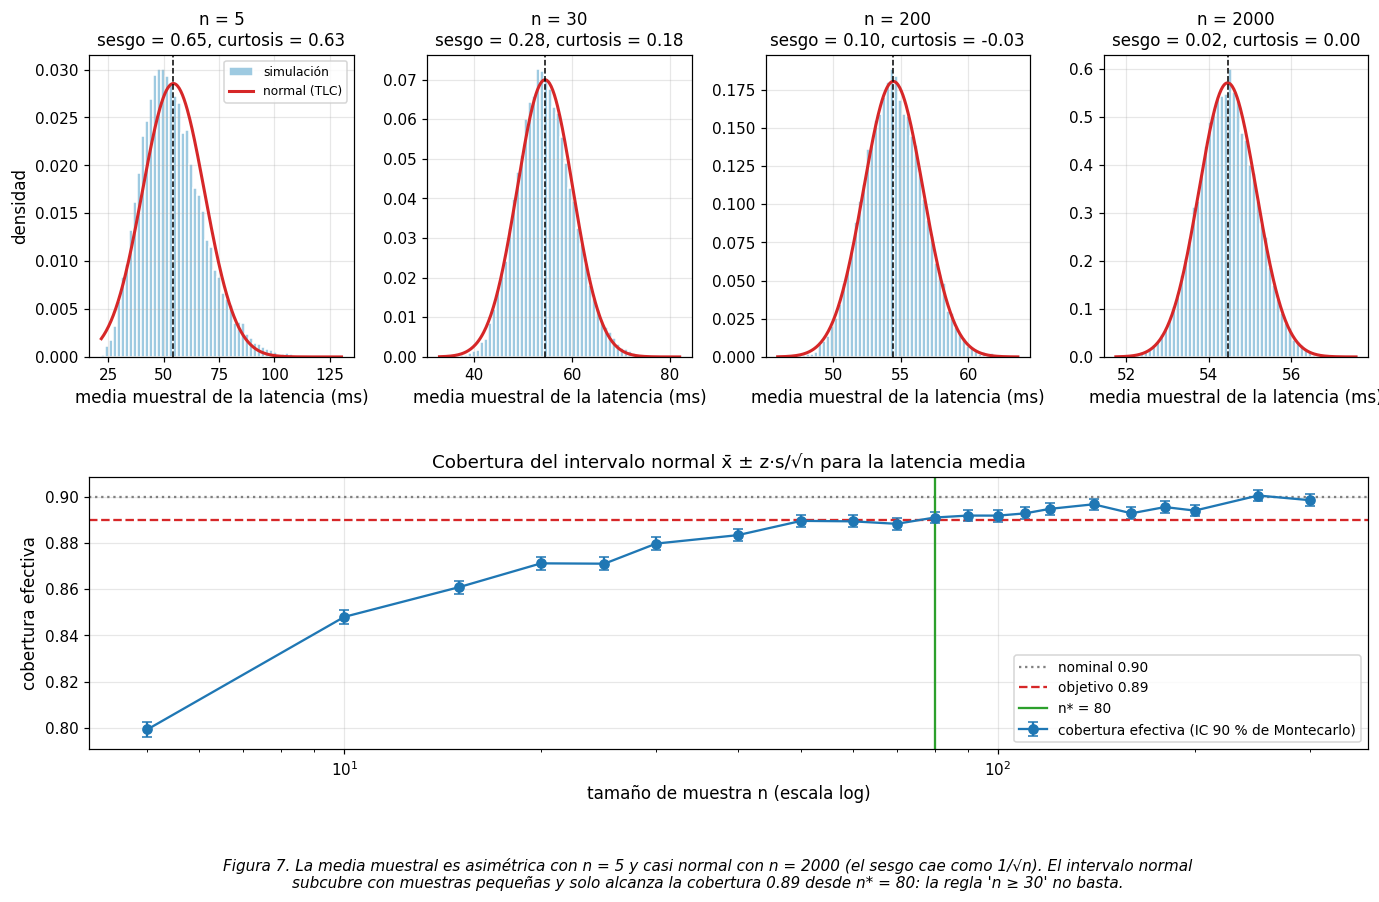

In [ ]:
# =====================================  FIGURA 7  =====================================
fig = plt.figure(figsize=(15, 8.2))
gs_ = fig.add_gridspec(2, 4, height_ratios=[1, 0.9], hspace=0.42, wspace=0.28)
for k_, n_ in enumerate(N_F1):
    ax_ = fig.add_subplot(gs_[0, k_]); m_ = medias_F1[n_]
    ax_.hist(m_, bins=60, density=True, color="#9ecae1", edgecolor="white", label="simulación")
    xs_ = np.linspace(m_.min(), m_.max(), 300)
    ax_.plot(xs_, stats.norm.pdf(xs_, mu_pob, sig_pob / np.sqrt(n_)), color="#d62728", lw=2, label="normal (TLC)")
    ax_.axvline(mu_pob, color="k", ls="--", lw=1)
    ax_.set_title(f"n = {n_}\nsesgo = {tabla_F1.loc[n_, 'sesgo sim.']:.2f}, curtosis = {tabla_F1.loc[n_, 'curtosis sim.']:.2f}", fontsize=11)
    ax_.set_xlabel("media muestral de la latencia (ms)")
    if k_ == 0: ax_.set_ylabel("densidad"); ax_.legend(fontsize=8)
ax_ = fig.add_subplot(gs_[1, :])
ax_.errorbar(rejilla_n, cob_rejilla, yerr=z * ee_cob, fmt="o-", color="#1f77b4", capsize=3, label="cobertura efectiva (IC 90 % de Montecarlo)")
ax_.axhline(nivel_confianza, color="gray", ls=":", label=f"nominal {nivel_confianza:.2f}")
ax_.axhline(objetivo_cob, color="#d62728", ls="--", label=f"objetivo {objetivo_cob:.2f}")
ax_.axvline(n_estrella, color="#2ca02c", lw=1.5, label=f"n* = {n_estrella}")
ax_.set_xscale("log"); ax_.set_xlabel("tamaño de muestra n (escala log)"); ax_.set_ylabel("cobertura efectiva")
ax_.set_title("Cobertura del intervalo normal x̄ ± z·s/√n para la latencia media"); ax_.legend(loc="lower right", fontsize=9)
pie_de_figura(fig, 7, f"La media muestral es asimétrica con n = 5 y casi normal con n = 2000 (el sesgo cae como 1/√n). El intervalo normal\n"
                      f"subcubre con muestras pequeñas y solo alcanza la cobertura {objetivo_cob:.2f} desde n* = {n_estrella}: la regla 'n ≥ 30' no basta.")
guardar_figura(fig, 7); plt.show()

**Conclusión F1.** La población es la distribución empírica de la latencia estable ($\mu = 54{,}46$ ms, $\sigma = 31{,}25$ ms, sesgo 1,46, curtosis en exceso 3,45). La distribución muestral de $\bar L_n$ está siempre centrada en $\mu$ y su dispersión es $\sigma/\sqrt n$ (14,0; 5,7; 2,2 y 0,70 ms), como dice la teoría. Lo que cambia con $n$ es la **forma**: con $n = 5$ conserva buena parte de la asimetría (sesgo 0,65); con $n = 30$ todavía es asimétrica (0,28); con 200 y 2000 ya es prácticamente normal (sesgo ≤ 0,1, curtosis ≈ 0). El sesgo simulado sigue la ley $\gamma_1/\sqrt n$. Por la asimetría, el intervalo normal **subcubre** con muestras pequeñas (0,80 con $n = 5$, 0,88 con $n = 30$). El menor tamaño con cobertura de al menos 0,89, estable de ahí en adelante, es **$n^* = 80$** (cobertura 0,891). Entre $n = 50$ y $n = 70$ la cobertura ya está a menos de un error de Montecarlo del objetivo, así que la frontera exacta es imprecisa; lo que sí es claro es que está **muy por encima de 30**. **La regla "n ≥ 30" no basta** para esta variable. **Aporta a P1** (qué tan confiables son las cifras de una muestra finita).

---
### F2. Intervalo para la latencia media
**Procedimiento clásico** (TLC): $\bar L \pm z\,s/\sqrt n$. Supone (1) observaciones **independientes**, (2) **con la misma distribución** y (3) $\bar L$ aproximadamente normal.
- **(3)** con $n \approx 28\,000 \gg n^*$ está garantizada por F1.
- **(2)** A2 mostró que los tramos antes y después de la ráfaga son casi iguales; se revisa aquí.
- **(1)** es el supuesto dudoso: la latencia incluye la **espera en cola**, y dos solicitudes que llegan seguidas comparten el estado de la cola. Eso produce **correlación positiva** entre latencias cercanas. La varianza de una suma con covarianzas (semana 14) da
$$\text{Var}(\bar L) = \frac{1}{n^2}\sum_i\sum_j \text{Cov}(L_i, L_j) = \frac{\sigma^2}{n}\Big(1 + 2\sum_{k\ge1}\big(1-\tfrac{k}{n}\big)\rho_k\Big),$$
con $\rho_k$ la correlación entre latencias separadas $k$ posiciones. Si $\rho_k > 0$, el intervalo clásico es **demasiado estrecho**.

**Comprobación de (1):** se calculan $\rho_k$ en orden de llegada y se comparan con lo que se obtiene al **barajar** la serie (Montecarlo: barajar destruye cualquier dependencia).

In [ ]:
# Paso 1. Intervalo clásico y comprobación de los supuestos
serie_L = df_estable.sort_values("t_llegada_s").latencia_ms.to_numpy()
n_L = len(serie_L)
media_L, s_L = serie_L.mean(), serie_L.std(ddof=1)
ee_cl = s_L / np.sqrt(n_L)
print("IC clásico:", texto_ic(media_L, *ic_normal(media_L, ee_cl), "TLC, supone independencia", 3), f"| semiancho = {z * ee_cl:.3f} ms")

def correlaciones(x, kmax):
    x = x - x.mean(); den = (x ** 2).sum()
    return np.array([(x[:-k] * x[k:]).sum() / den for k in range(1, kmax + 1)])
K_F2 = 50
rho_L = correlaciones(serie_L, K_F2)
rho_bar = np.array([correlaciones(rng.permutation(serie_L), 1)[0] for _ in range(300)])
print(f"\n(1) Correlación entre latencias separadas k posiciones: " + ", ".join(f"rho_{k} = {rho_L[k - 1]:.3f}" for k in (1, 2, 3, 5, 10, 20, 50)))
print(f"    Serie barajada (independiente): rho_1 entre {rho_bar.min():.3f} y {rho_bar.max():.3f} en 300 barajadas")
factor = 1 + 2 * np.sum((1 - np.arange(1, K_F2 + 1) / n_L) * rho_L)
print(f"    Factor 1 + 2Σ(1 - k/n)ρ_k (k ≤ {K_F2}) = {factor:.2f} -> Var(media) es {factor:.2f} veces la clásica; "
      f"equivale a n efectivo ≈ {n_L / factor:.0f} de {n_L}")

# (2) misma distribución en los dos tramos estables (con el error estándar corregido por medias por lotes)
def ee_lotes(x, m=250):
    b_ = len(x) // m
    return x[:b_ * m].reshape(b_, m).mean(axis=1).std(ddof=1) / np.sqrt(b_)
pre_s = df_estable[df_estable.t_llegada_s < INI].sort_values("t_llegada_s").latencia_ms.to_numpy()
post_s = df_estable[df_estable.t_llegada_s >= FIN].sort_values("t_llegada_s").latencia_ms.to_numpy()
dif_pp, ee_pp = post_s.mean() - pre_s.mean(), np.sqrt(ee_lotes(pre_s) ** 2 + ee_lotes(post_s) ** 2)
print(f"\n(2) Después - antes = {texto_ic(dif_pp, *ic_normal(dif_pp, ee_pp), 'TLC con EE por lotes', 2)} ms "
      f"({100 * dif_pp / pre_s.mean():.1f} % de la media, {dif_pp / s_L:.3f} desviaciones estándar)")

IC clásico: 54.459  [54.151; 54.766]  (IC 90%, TLC, supone independencia) | semiancho = 0.307 ms

(1) Correlación entre latencias separadas k posiciones: rho_1 = 0.090, rho_2 = 0.091, rho_3 = 0.068, rho_5 = 0.018, rho_10 = -0.001, rho_20 = -0.007, rho_50 = -0.003
    Serie barajada (independiente): rho_1 entre -0.015 y 0.016 en 300 barajadas
    Factor 1 + 2Σ(1 - k/n)ρ_k (k ≤ 50) = 1.59 -> Var(media) es 1.59 veces la clásica; equivale a n efectivo ≈ 17554 de 27970

(2) Después - antes = 0.83  [0.02; 1.64]  (IC 90%, TLC con EE por lotes) ms (1.5 % de la media, 0.027 desviaciones estándar)


**Paso 2. Corrección.** Se estima la varianza de la media **sin suponer independencia**, de dos formas:
1. **Fórmula de la varianza de la suma** con las correlaciones estimadas hasta $K = 50$ (el factor del paso 1).
2. **Medias por lotes:** se parte la serie en $b$ lotes consecutivos de $m$ solicitudes. Si $m$ es mucho mayor que el alcance de la dependencia, las medias de los lotes son casi independientes, el TLC se aplica a ellas y $\widehat{\text{Var}}(\bar L) = s^2_{\text{lotes}}/b$. Se revisa la sensibilidad a $m$ y que la correlación entre lotes consecutivos sea ≈ 0.

**Paso 3. ¿El clásico realmente falla? Verificación con datos reales.** Se toman muchos tramos de 2000 solicitudes **consecutivas** (que conservan la dependencia real) y se mide qué fracción de los intervalos clásico y corregido contiene la media del régimen completo.

In [ ]:
# Paso 2. Intervalos corregidos
filas = [{"método": "clásico (independencia)", "EE": ee_cl, "semiancho": z * ee_cl, "corr. entre lotes": np.nan}]
ee_formula = ee_cl * np.sqrt(factor)
filas.append({"método": f"fórmula con ρ_k (K = {K_F2})", "EE": ee_formula, "semiancho": z * ee_formula, "corr. entre lotes": np.nan})
for m_lote in [100, 250, 500, 1000]:
    b_ = n_L // m_lote
    ml = serie_L[:b_ * m_lote].reshape(b_, m_lote).mean(axis=1)
    filas.append({"método": f"medias por lotes (m = {m_lote}, b = {b_})", "EE": ml.std(ddof=1) / np.sqrt(b_),
                  "semiancho": z * ml.std(ddof=1) / np.sqrt(b_), "corr. entre lotes": correlaciones(ml, 1)[0]})
tabla_F2 = pd.DataFrame(filas); tabla_F2["semiancho / clásico"] = tabla_F2.semiancho / (z * ee_cl)
print(tabla_F2.round(4).to_string(index=False))
ee_corr = ee_lotes(serie_L, 250)
IC_LAT = ic_normal(media_L, ee_corr)
print("\nIC clásico   :", texto_ic(media_L, *ic_normal(media_L, ee_cl), "TLC, supone independencia", 2))
print("IC corregido :", texto_ic(media_L, *IC_LAT, "TLC sobre medias por lotes de 250", 2))
print(f"Efecto: el semiancho pasa de {z * ee_cl:.3f} a {z * ee_corr:.3f} ms (+{100 * (ee_corr / ee_cl - 1):.0f} %)")

# Paso 3. Cobertura con tramos consecutivos reales
n_tr, m_tr = 2000, 100
cub_cl, cub_bm = [], []
for i0 in np.arange(0, n_L - n_tr + 1, 25):
    x_ = serie_L[i0:i0 + n_tr]; m_ = x_.mean()
    cub_cl.append(abs(m_ - media_L) <= z * x_.std(ddof=1) / np.sqrt(n_tr))
    ml_ = x_.reshape(n_tr // m_tr, m_tr).mean(axis=1)
    cub_bm.append(abs(m_ - media_L) <= z * ml_.std(ddof=1) / np.sqrt(n_tr // m_tr))
print(f"\n{len(cub_cl)} tramos de {n_tr} solicitudes consecutivas (nominal {nivel_confianza:.2f}): "
      f"cobertura clásico = {np.mean(cub_cl):.3f} | medias por lotes = {np.mean(cub_bm):.3f} (tramos solapados: indicativo)")

                             método     EE  semiancho  corr. entre lotes  semiancho / clásico
            clásico (independencia) 0.1869     0.3074                NaN               1.0000
           fórmula con ρ_k (K = 50) 0.2359     0.3880                NaN               1.2623
medias por lotes (m = 100, b = 279) 0.2384     0.3921             0.0991               1.2756
medias por lotes (m = 250, b = 111) 0.2566     0.4221             0.0504               1.3733
 medias por lotes (m = 500, b = 55) 0.2417     0.3976             0.2487               1.2934
medias por lotes (m = 1000, b = 27) 0.2708     0.4454            -0.0390               1.4491

IC clásico   : 54.46  [54.15; 54.77]  (IC 90%, TLC, supone independencia)
IC corregido : 54.46  [54.04; 54.88]  (IC 90%, TLC sobre medias por lotes de 250)
Efecto: el semiancho pasa de 0.307 a 0.422 ms (+37 %)

1039 tramos de 2000 solicitudes consecutivas (nominal 0.90): cobertura clásico = 0.794 | medias por lotes = 0.875 (tramos solapado

**Conclusión F2.** El intervalo clásico, 54,46 [54,15; 54,77] ms, **supone independencia, y en estos datos no la hay**: en orden de llegada las latencias cercanas están correlacionadas ($\rho_1 \approx \rho_2 \approx 0{,}09$, mientras que en la serie barajada nunca pasa de 0,02), porque comparten el estado de la cola. Con la fórmula de la varianza de la suma, $\text{Var}(\bar L)$ es ≈ 1,6 veces la clásica: las 27 970 solicitudes valen como ≈ 17 500 independientes. La normalidad de la media no es problema ($n \gg n^* = 80$); entre los tramos estables hay un salto de nivel pequeño (0,8 ms, 1,5 %). **Corrección:** medias por lotes de 250 (correlación entre lotes ≈ 0,05), coherente con la fórmula; según el tamaño de lote, el semiancho crece entre 26 y 45 %. El IC corregido es **54,46 [54,04; 54,88] ms**. La verificación con tramos reales lo justifica: el clásico cubre solo ≈ 0,79 frente a ≈ 0,88 del corregido. **Se reporta el intervalo corregido.** **Aporta a P1.**

---
### F3. Versión B frente a versión A
**Qué se compara (siempre B − A, régimen estable):**
1. $\Delta_1 = E[G \mid B, \text{no caché}] - E[G \mid A, \text{no caché}]$: distribución muestral de la **diferencia de medias** (semana 15), $\bar x_B - \bar x_A \pm z\sqrt{s_A^2/n_A + s_B^2/n_B}$.
2. $\Delta_2 = P(\text{intentos} > 1 \mid B) - P(\text{intentos} > 1 \mid A)$: **diferencia de proporciones**, $\hat p_B - \hat p_A \pm z\sqrt{\hat p_A(1-\hat p_A)/n_A + \hat p_B(1-\hat p_B)/n_B}$.
3. $\Delta_3 = P(L > \tau \mid B) - P(L > \tau \mid A)$, igual que (2). Aquí $p \approx 0{,}002$ y hay pocas violaciones por versión, así que se revisa $n\hat p \ge 10$ y se respalda con un **Montecarlo de permutación**: si la versión no importara, barajar las etiquetas A/B daría diferencias como la observada.

**Tres conclusiones a la vez: Bonferroni.** Si cada intervalo se construye al nivel $1 - \alpha/3$, por la **desigualdad de la unión** (semana 1)
$$P(\text{alguno falla}) \le \sum_{j=1}^3 P(\text{falla el } j) = 3\cdot\frac{\alpha}{3} = \alpha,$$
así que los tres contienen **a la vez** sus valores verdaderos con probabilidad $\ge 1 - \alpha = 0{,}90$. Se usa $z_{1-\alpha/6}$.

**Antes: ¿la asignación aleatoria dejó grupos comparables?** Se revisan variables que **no** dependen del modelo (tamaño, red, caché, momento de llegada): la diferencia de medias en **unidades de error estándar** (valores mayores que $z_{1-\alpha/(2K)}$ serían desbalance) y la **diferencia estandarizada** $(\bar x_B - \bar x_A)/\sqrt{(s_A^2+s_B^2)/2}$ (criterio habitual $< 0{,}1$).

In [ ]:
# Paso 1. ¿La asignación aleatoria dejó grupos comparables?
gA, gB = df_estable[df_estable.version == "A"], df_estable[df_estable.version == "B"]
nA, nB = len(gA), len(gB)
z_reparto = (nA - (nA + nB) / 2) / np.sqrt((nA + nB) * 0.25)      # Binomial(n, 1/2) aproximada por la normal
print(f"Tamaños: A = {nA}, B = {nB}; reparto 50/50: z = {z_reparto:.2f} (|z| < {z:.3f} -> compatible)")
COVS = ["tam_kb", "red_ms", "cache_hit", "t_llegada_s"]
z_bal = stats.norm.ppf(1 - alpha / (2 * len(COVS)))
filas = []
for v_ in COVS:
    d_, ee_ = ic_dif_medias(gB[v_], gA[v_])
    filas.append({"covariable": v_, "media A": gA[v_].mean(), "media B": gB[v_].mean(), "diferencia en EE": d_ / ee_,
                  "dif. estandarizada": d_ / np.sqrt((gA[v_].var() + gB[v_].var()) / 2)})
tabla_bal = pd.DataFrame(filas)
tabla_bal["balanceada"] = (tabla_bal["diferencia en EE"].abs() < z_bal) & (tabla_bal["dif. estandarizada"].abs() < 0.1)
print(tabla_bal.round(4).to_string(index=False))
print(f"Umbral con Bonferroni para {len(COVS)} covariables: |diferencia en EE| < {z_bal:.3f}")
q_tam = np.quantile(df_estable.tam_kb, [0.1, 0.5, 0.9])
print("Cuantiles 10/50/90 % de tam_kb:", "A =", np.quantile(gA.tam_kb, [0.1, 0.5, 0.9]).round(1), "| B =", np.quantile(gB.tam_kb, [0.1, 0.5, 0.9]).round(1))

Tamaños: A = 14120, B = 13850; reparto 50/50: z = 1.61 (|z| < 1.645 -> compatible)
 covariable  media A  media B  diferencia en EE  dif. estandarizada  balanceada
     tam_kb 242.6398 241.6182           -0.5041             -0.0060        True
     red_ms  25.5962  25.6064            0.2209              0.0026        True
  cache_hit   0.3346   0.3375            0.5155              0.0062        True
t_llegada_s 626.3960 630.2684            0.8735              0.0104        True
Umbral con Bonferroni para 4 covariables: |diferencia en EE| < 2.241
Cuantiles 10/50/90 % de tam_kb: A = [ 67.1 205.  465. ] | B = [ 65.5 203.  469. ]


In [ ]:
# Paso 2. Las tres diferencias B - A con intervalos simultáneos (Bonferroni)
K_FAM = 3
z_bonf = stats.norm.ppf(1 - alpha / (2 * K_FAM))
xA_gpu = gA.loc[gA.cache_hit == 0, "gpu_ms"].to_numpy(); xB_gpu = gB.loc[gB.cache_hit == 0, "gpu_ms"].to_numpy()
dif1, ee1 = ic_dif_medias(xB_gpu, xA_gpu)
kA2, kB2 = int((gA.intentos > 1).sum()), int((gB.intentos > 1).sum())
dif2, ee2 = ic_dif_proporciones(kB2, nB, kA2, nA)
kA3, kB3 = int((gA.latencia_ms > tau).sum()), int((gB.latencia_ms > tau).sum())
dif3, ee3 = ic_dif_proporciones(kB3, nB, kA3, nA)
tabla_F3 = pd.DataFrame([
    {"diferencia B - A": "(i) E[G | no caché] (ms)", "A": xA_gpu.mean(), "B": xB_gpu.mean(), "Δ": dif1, "EE": ee1},
    {"diferencia B - A": "(ii) P(intentos > 1)", "A": kA2 / nA, "B": kB2 / nB, "Δ": dif2, "EE": ee2},
    {"diferencia B - A": f"(iii) P(L > τ = {tau:g} ms)", "A": kA3 / nA, "B": kB3 / nB, "Δ": dif3, "EE": ee3}])
tabla_F3["IC inf"], tabla_F3["IC sup"] = tabla_F3.Δ - z_bonf * tabla_F3.EE, tabla_F3.Δ + z_bonf * tabla_F3.EE
tabla_F3["Δ en EE"] = tabla_F3.Δ / tabla_F3.EE
tabla_F3["contiene 0"] = (tabla_F3["IC inf"] <= 0) & (tabla_F3["IC sup"] >= 0)
print(f"Cada intervalo al nivel 1 - alpha/3 = {1 - alpha / 3:.4f} (z = {z_bonf:.3f}); los tres juntos >= {nivel_confianza:.2f}\n")
with pd.option_context("display.float_format", "{:.5f}".format):
    print(tabla_F3.to_string(index=False))
print(f"\n(i) cambio relativo: {100 * dif1 / xA_gpu.mean():.1f} % [{100 * (dif1 - z_bonf * ee1) / xA_gpu.mean():.1f} %; {100 * (dif1 + z_bonf * ee1) / xA_gpu.mean():.1f} %]")
print(f"(iii) violaciones: A = {kA3} de {nA}, B = {kB3} de {nB} (n·p >= 10 en ambas: {min(kA3, kB3) >= 10}); ambas << epsilon = {epsilon}")

Cada intervalo al nivel 1 - alpha/3 = 0.9667 (z = 2.128); los tres juntos >= 0.90

        diferencia B - A        A        B        Δ      EE   IC inf   IC sup  Δ en EE  contiene 0
(i) E[G | no caché] (ms) 40.38989 38.02178 -2.36812 0.37810 -3.17274 -1.56350 -6.26313       False
    (ii) P(intentos > 1)  0.21055  0.21191  0.00136 0.00488 -0.00903  0.01175  0.27879        True
 (iii) P(L > τ = 210 ms)  0.00163  0.00130 -0.00033 0.00046 -0.00130  0.00064 -0.72041        True

(i) cambio relativo: -5.9 % [-7.9 %; -3.9 %]
(iii) violaciones: A = 23 de 14120, B = 18 de 13850 (n·p >= 10 en ambas: True); ambas << epsilon = 0.01


In [ ]:
# Paso 3. Respaldo por Montecarlo de permutación: si la versión no importara, barajar A/B daría diferencias así
etiqueta_B = (df_estable.version == "B").to_numpy()
y_viol, y_reint = (df_estable.latencia_ms > tau).to_numpy(), (df_estable.intentos > 1).to_numpy()
nc_mask = df_estable.cache_hit.to_numpy() == 0
g_nc, et_nc = df_estable.gpu_ms.to_numpy()[nc_mask], etiqueta_B[nc_mask]
perm = {"(i)": [], "(ii)": [], "(iii)": []}
for _ in range(2000):
    e_ = rng.permutation(etiqueta_B); e2_ = rng.permutation(et_nc)
    perm["(i)"].append(abs(g_nc[e2_].mean() - g_nc[~e2_].mean()))
    perm["(ii)"].append(abs(y_reint[e_].mean() - y_reint[~e_].mean()))
    perm["(iii)"].append(abs(y_viol[e_].mean() - y_viol[~e_].mean()))
for (clave, obs) in zip(perm, [dif1, dif2, dif3]):
    print(f"  {clave:5s}: |Δ| observado = {abs(obs):.5f} | fracción de 2000 permutaciones con |Δ| >= observado = {prob_montecarlo(abs(obs), perm[clave]):.4f}")

  (i)  : |Δ| observado = 2.36812 | fracción de 2000 permutaciones con |Δ| >= observado = 0.0000
  (ii) : |Δ| observado = 0.00136 | fracción de 2000 permutaciones con |Δ| >= observado = 0.7610
  (iii): |Δ| observado = 0.00033 | fracción de 2000 permutaciones con |Δ| >= observado = 0.5440


**Paso 4. Robustez de (i): ajuste por tamaño.** El tiempo de GPU depende mucho del tamaño (D2–D4). Con el modelo multiplicativo de C2/D3, $\ln G = \beta_0 + \beta_1\ln(\text{tam}) + \delta\cdot\mathbb 1\{B\} + e$, resuelto con las ecuaciones normales como en D3, la diferencia de versiones se estima con menos ruido y no puede venir de un desbalance de tamaños. $e^{\delta} - 1$ es el cambio porcentual atribuible a B.

In [ ]:
# Paso 4. Ajuste por tamaño (ecuaciones normales)
nc_ = df_estable[df_estable.cache_hit == 0]
y_ = np.log(nc_.gpu_ms.to_numpy())
X_ = np.column_stack([np.ones(len(nc_)), np.log(nc_.tam_kb.to_numpy()), (nc_.version == "B").to_numpy().astype(float)])
beta_ = np.linalg.solve(X_.T @ X_, X_.T @ y_)
res_ = y_ - X_ @ beta_
ee_beta = np.sqrt(np.diag(res_ @ res_ / (len(y_) - 3) * np.linalg.inv(X_.T @ X_)))
delta_, ee_d = beta_[2], ee_beta[2]
print(f"ln G = {beta_[0]:.3f} + {beta_[1]:.3f}·ln(tam) + δ·1{{B}}; δ = {delta_:.4f} (EE {ee_d:.4f})")
print(f"Efecto de B ajustado por tamaño: {100 * (np.exp(delta_) - 1):.1f} % "
      f"[{100 * (np.exp(delta_ - z_bonf * ee_d) - 1):.1f} %; {100 * (np.exp(delta_ + z_bonf * ee_d) - 1):.1f} %] (nivel {1 - alpha / 3:.3f})")

ln G = 0.705 + 0.527·ln(tam) + δ·1{B}; δ = -0.0589 (EE 0.0070)
Efecto de B ajustado por tamaño: -5.7 % [-7.1 %; -4.3 %] (nivel 0.967)


**Conclusión F3 y decisión.** La aleatorización funcionó: el reparto es compatible con 50/50 y tamaño, red, caché y momento de llegada están balanceados (diferencias pequeñas en unidades de error estándar y diferencias estandarizadas ≈ 0,01). Con intervalos **simultáneos** al 90 % (Bonferroni):
- **(i) GPU:** B **reduce** el tiempo medio de GPU de las no cacheadas en ≈ 2,4 ms (≈ −6 %), con un intervalo lejos de 0; ajustando por tamaño el efecto es casi el mismo, así que no es un artefacto de desbalance.
- **(ii) Reintentos:** no se detecta diferencia; el intervalo contiene 0.
- **(iii) SLO:** no se detecta diferencia; ambas versiones violan $\tau$ en ≈ 0,2 % de las solicitudes, muy por debajo de $\varepsilon = 0{,}01$.

El Montecarlo de permutación confirma las tres lecturas sin usar la aproximación normal. **Decisión: adoptar la versión B**: mejora el recurso escaso (tiempo de GPU) sin empeorar de forma detectable la confiabilidad ni el SLO. **Reserva:** "no detectar diferencia" no es "probar igualdad"; el extremo superior de los intervalos (ii) y (iii) es el peor caso compatible con los datos. **Responde P2.**

---
### F4. Cobertura de dos intervalos para una proporción
Con $X \sim \text{Bin}(n, p)$ y $\hat p = X/n$, el TLC dice que $\frac{\hat p - p}{\sqrt{p(1-p)/n}} \approx N(0, 1)$. De ahí salen dos intervalos al nivel $1-\alpha$:
- **Wald:** se reemplaza $p$ por $\hat p$ dentro de la raíz: $\hat p \pm z\sqrt{\hat p(1-\hat p)/n}$.
- **Wilson:** no se reemplaza; se resuelve para $p$ la desigualdad $|\hat p - p| \le z\sqrt{p(1-p)/n}$, una **ecuación cuadrática** en $p$, cuyas raíces son
$$\frac{\hat p + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + z^2/n}.$$

**Diseño.** $n \in \{10, 30, 100, 500, 2000\}$ y $p \in \{0{,}002;\ 0{,}01;\ 0{,}05;\ 0{,}2;\ 0{,}5\}$, que incluye los valores del proyecto: $p \approx 0{,}002$ (violaciones de $\tau$), $\approx 0{,}21$ (reintentos), $\approx 0{,}34$ (caché). Para cada una de las 25 configuraciones se simulan $R = 10^4$ réplicas y se mide la **cobertura efectiva** y el ancho medio.

In [ ]:
# Paso 1. Montecarlo de cobertura de Wald y Wilson
def intervalos_proporcion(x, n, z_):
    p = x / n; se = np.sqrt(p * (1 - p) / n)
    centro = (p + z_ ** 2 / (2 * n)) / (1 + z_ ** 2 / n)
    semi = z_ * np.sqrt(p * (1 - p) / n + z_ ** 2 / (4 * n ** 2)) / (1 + z_ ** 2 / n)
    return {"Wald": (p - se * z_, p + se * z_), "Wilson": (centro - semi, centro + semi)}
R_F4, N_F4, P_F4, METODOS = 10_000, [10, 30, 100, 500, 2000], [0.002, 0.01, 0.05, 0.2, 0.5], ["Wald", "Wilson"]
filas = []
for n_ in N_F4:
    for p_ in P_F4:
        x_ = rng.binomial(n_, p_, size=R_F4)
        for met, (li, ls) in intervalos_proporcion(x_, n_, z).items():
            filas.append({"n": n_, "p": p_, "np": n_ * p_, "método": met, "cobertura": np.mean((li <= p_) & (p_ <= ls)),
                          "ancho medio": np.mean(np.clip(ls, 0, 1) - np.clip(li, 0, 1)), "P(x = 0)": np.mean(x_ == 0)})
tabla_F4 = pd.DataFrame(filas)
ee_F4 = np.sqrt(nivel_confianza * (1 - nivel_confianza) / R_F4)
print(f"R = {R_F4} réplicas por configuración; error de Montecarlo ≈ {ee_F4:.4f}\nCobertura efectiva (nominal {nivel_confianza:.2f}):")
print(tabla_F4.pivot_table(index=["n", "p"], columns="método", values="cobertura")[METODOS].round(3).to_string())

# Paso 2. Resumen
res = tabla_F4.groupby("método").agg(cobertura_min=("cobertura", "min"), cobertura_media=("cobertura", "mean"),
                                    error_abs_medio=("cobertura", lambda c: np.mean(np.abs(c - nivel_confianza)))).loc[METODOS]
print("\n", res.round(3).to_string())
print("\nSolo configuraciones con np >= 10 (regla para usar Wald):")
print(tabla_F4[tabla_F4.np >= 10].groupby("método").cobertura.agg(["min", "mean"]).loc[METODOS].round(3).to_string())
print("\nPor qué falla Wald con p pequeño: si x = 0, p_hat = 0 y el intervalo es [0, 0], que nunca contiene p.")
print(tabla_F4[(tabla_F4.método == "Wald") & (tabla_F4.p == 0.002)][["n", "P(x = 0)", "cobertura"]].round(3).to_string(index=False))

R = 10000 réplicas por configuración; error de Montecarlo ≈ 0.0030
Cobertura efectiva (nominal 0.90):
método       Wald  Wilson
n    p                   
10   0.002  0.020   0.980
     0.010  0.091   0.909
     0.050  0.387   0.916
     0.200  0.858   0.966
     0.500  0.888   0.888
30   0.002  0.059   0.941
     0.010  0.257   0.964
     0.050  0.771   0.939
     0.200  0.851   0.898
     0.500  0.896   0.896
100  0.002  0.177   0.823
     0.010  0.629   0.923
     0.050  0.857   0.901
     0.200  0.889   0.900
     0.500  0.909   0.909
500  0.002  0.634   0.917
     0.010  0.866   0.892
     0.050  0.887   0.925
     0.200  0.892   0.894
     0.500  0.901   0.901
2000 0.002  0.888   0.928
     0.010  0.896   0.907
     0.050  0.892   0.908
     0.200  0.897   0.900
     0.500  0.896   0.896

         cobertura_min  cobertura_media  error_abs_medio
método                                                 
Wald            0.020            0.688            0.213
Wilson          0.823     

---
## FIGURA 8 · Cobertura efectiva frente al nominal (ítem F4)
Cobertura de Wald y Wilson frente a la proporción verdadera $p$ (escala log), para cada $n$. La línea gris es el nominal 0,90 y la banda, el error de Montecarlo.

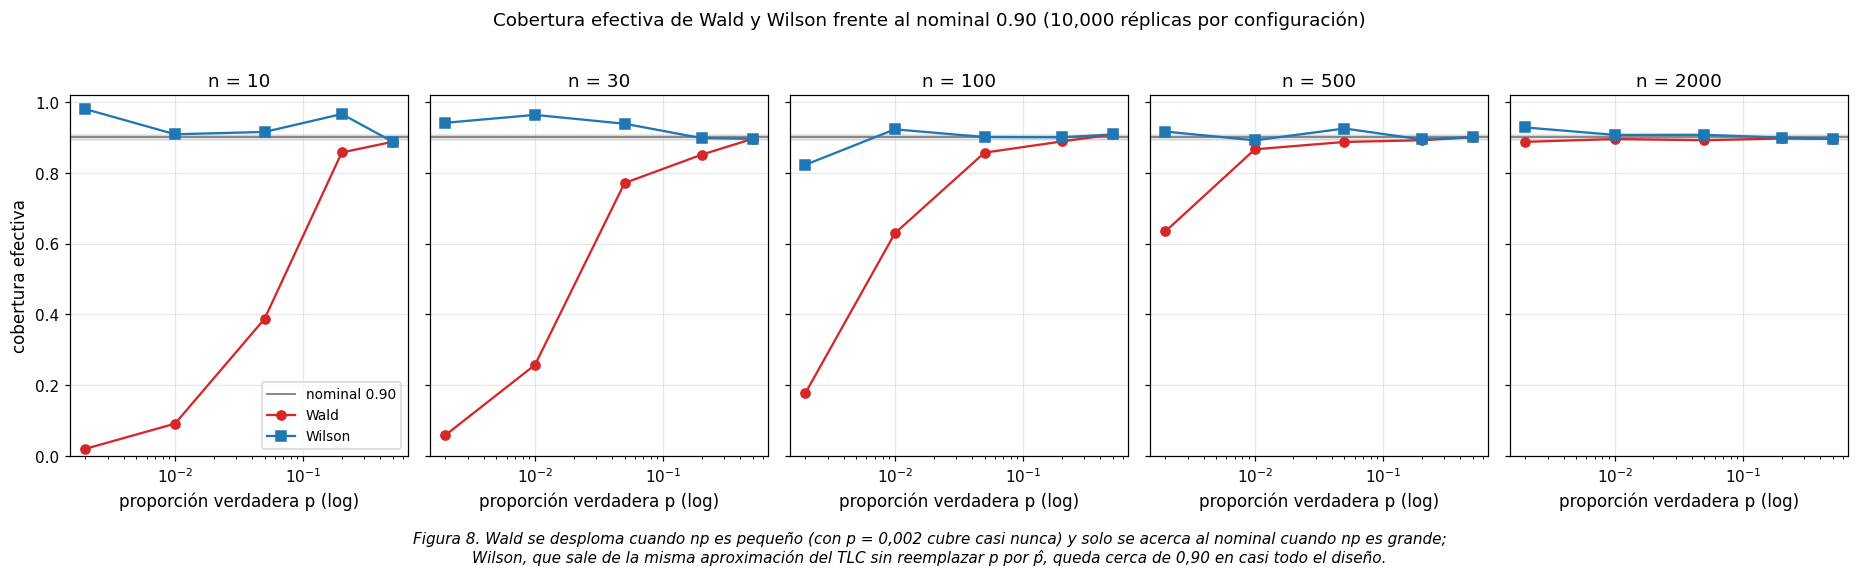

In [ ]:
# =====================================  FIGURA 8  =====================================
col_F4, mar_F4 = {"Wald": "#d62728", "Wilson": "#1f77b4"}, {"Wald": "o", "Wilson": "s"}
fig, axs = plt.subplots(1, len(N_F4), figsize=(17, 4.6), sharey=True)
for ax_, n_ in zip(axs, N_F4):
    sub = tabla_F4[tabla_F4.n == n_]
    ax_.axhspan(nivel_confianza - 2 * ee_F4, nivel_confianza + 2 * ee_F4, color="gray", alpha=0.2)
    ax_.axhline(nivel_confianza, color="gray", lw=1.2, label=f"nominal {nivel_confianza:.2f}")
    for met in METODOS:
        s_ = sub[sub.método == met]
        ax_.plot(s_.p, s_.cobertura, marker=mar_F4[met], color=col_F4[met], label=met)
    ax_.set_xscale("log"); ax_.set_title(f"n = {n_}"); ax_.set_xlabel("proporción verdadera p (log)"); ax_.set_ylim(0, 1.02)
axs[0].set_ylabel("cobertura efectiva"); axs[0].legend(loc="lower right", fontsize=9)
fig.suptitle(f"Cobertura efectiva de Wald y Wilson frente al nominal {nivel_confianza:.2f} ({R_F4:,} réplicas por configuración)", y=1.02)
pie_de_figura(fig, 8, "Wald se desploma cuando np es pequeño (con p = 0,002 cubre casi nunca) y solo se acerca al nominal cuando np es grande;\n"
                      "Wilson, que sale de la misma aproximación del TLC sin reemplazar p por p̂, queda cerca de 0,90 en casi todo el diseño.")
plt.tight_layout(); guardar_figura(fig, 8); plt.show()

**Conclusión F4.** **Wald** falla cuando $np$ es pequeño: con $p = 0{,}002$ y $n$ chico casi todas las muestras tienen $x = 0$, el intervalo es $[0, 0]$ y nunca contiene $p$. Solo con $np \ge 10$ se acerca al nominal. **Wilson** queda cerca de 0,90 en casi todo el diseño (cobertura media 0,91 frente a 0,69 de Wald), porque no usa $\hat p$ en el error estándar; solo baja cuando se espera menos de un caso ($np = 0{,}2$: 0,82). **Consecuencias para el proyecto:** todas las proporciones que se reportan con Wald cumplen $np \ge 10$ (reintentos y caché con miles de casos; E1 con al menos 11; P($L > \tau$) por versión con 18 y 23), así que Wald es válido allí; en los casos más justos (TFP de "D1 y D2") se dio también Wilson. **Aporta a P1.**

---
### F5. Tamaño de muestra por versión
**Deducción (manuscrita en E3).** Con $n$ solicitudes no cacheadas por versión, el intervalo de F3(i) tiene semiancho
$$h = z\sqrt{\frac{\sigma_A^2}{n} + \frac{\sigma_B^2}{n}} \le h_0 \iff n \ge \frac{z^2(\sigma_A^2 + \sigma_B^2)}{h_0^2},$$
con $h_0 = 1$ ms y $z = z_{1-\alpha/6}$ (el nivel de Bonferroni de F3, porque es ese intervalo). Como solo una fracción $1 - c$ llega a la GPU, el número total de solicitudes por versión es $n/(1-\hat c)$. **Verificación:** se simulan experimentos con $n$ no cacheadas por versión, remuestreando de los tiempos de cada versión, y se mide el semiancho obtenido.

In [ ]:
# Paso 1. Tamaño de muestra analítico
h0 = 1.0
sA_pl, sB_pl, c_pl = xA_gpu.std(ddof=1), xB_gpu.std(ddof=1), df_estable.cache_hit.mean()
n_req = lambda z_: int(np.ceil(z_ ** 2 * (sA_pl ** 2 + sB_pl ** 2) / h0 ** 2))
n_F5, n_F5_ind = n_req(z_bonf), n_req(z)
print(f"sigma_A = {sA_pl:.2f} ms, sigma_B = {sB_pl:.2f} ms, P(caché) = {c_pl:.3f}")
print(f"Nivel de F3 (Bonferroni, z = {z_bonf:.4f}): n = {n_F5} no cacheadas por versión -> ≈ {int(np.ceil(n_F5 / (1 - c_pl)))} solicitudes por versión")
print(f"Intervalo individual (z = {z:.4f}):          n = {n_F5_ind} -> ≈ {int(np.ceil(n_F5_ind / (1 - c_pl)))} solicitudes por versión")
print(f"Hoy: {len(xA_gpu)} (A) y {len(xB_gpu)} (B) no cacheadas -> semiancho actual = {z_bonf * ee1:.3f} ms")

# Paso 2. Verificación por simulación
dif_pob = xB_gpu.mean() - xA_gpu.mean()
filas = []
for n_ in [int(0.8 * n_F5), n_F5, int(1.05 * n_F5), int(1.10 * n_F5)]:
    h_, cub_ = np.empty(3000), np.empty(3000, dtype=bool)
    for i in range(3000):
        a_, b_ = rng.choice(xA_gpu, n_), rng.choice(xB_gpu, n_)
        h_[i] = z_bonf * np.sqrt(a_.var(ddof=1) / n_ + b_.var(ddof=1) / n_)
        cub_[i] = abs(b_.mean() - a_.mean() - dif_pob) <= h_[i]
    filas.append({"n por versión": n_, "semiancho medio": h_.mean(), "P(h <= 1 ms)": np.mean(h_ <= h0),
                  "percentil 90 de h": np.quantile(h_, 0.9), "cobertura": cub_.mean()})
print(pd.DataFrame(filas).round(4).to_string(index=False), f"\n(cobertura nominal: {1 - alpha / 3:.4f})")

sigma_A = 26.57 ms, sigma_B = 24.94 ms, P(caché) = 0.336
Nivel de F3 (Bonferroni, z = 2.1280): n = 6016 no cacheadas por versión -> ≈ 9061 solicitudes por versión
Intervalo individual (z = 1.6449):          n = 3594 -> ≈ 5413 solicitudes por versión
Hoy: 9396 (A) y 9176 (B) no cacheadas -> semiancho actual = 0.805 ms
 n por versión  semiancho medio  P(h <= 1 ms)  percentil 90 de h  cobertura
          4812           1.1178        0.0000             1.1397     0.9693
          6016           1.0000        0.5077             1.0177     0.9683
          6316           0.9760        0.9663             0.9926     0.9613
          6617           0.9531        1.0000             0.9692     0.9683 
(cobertura nominal: 0.9667)


**Conclusión F5.** Con las desviaciones de F3 y el nivel de Bonferroni se necesitan ≈ 6000 solicitudes **no cacheadas** por versión (≈ 9000 en total por versión, porque un tercio sale de caché); como intervalo individual bastarían ≈ 3600. La simulación lo confirma: con ese $n$ el semiancho medio es 1,00 ms y la cobertura es la nominal. **Matiz:** como $s$ varía de muestra a muestra, $h \le 1$ solo se cumple en ≈ la mitad de los experimentos; con un 5 % más se cumple casi siempre. Hoy hay ≈ 9300 no cacheadas por versión, así que el intervalo actual ya cumple.

---
### F6. Validación con `solicitudes_validacion.csv`
El archivo es otra ventana de 20 minutos de producción que no se usó antes. Se le aplica **la misma** limpieza de A1 (misma función `limpiar`) y el mismo criterio de régimen de A2. Luego se reestiman los parámetros de B, C y F y se compara cada uno con el original mediante la **diferencia** (validación − original) con su intervalo. Como son $K = 12$ comparaciones, se usa **Bonferroni** (desigualdad de la unión): cada intervalo al nivel $1 - \alpha/K$.

Errores estándar usados: tasas de Poisson, $\text{EE}(\hat\lambda) = \sqrt{\hat\lambda/T}$ (B1); proporciones y medias, TLC; **desviaciones estándar**: $s^2$ es el promedio de $Y = (X - \bar X)^2$, así que el TLC aplica también a $s^2$ y se comparan las varianzas como diferencia de medias de $Y$; la latencia media usa el error estándar por lotes de F2.

In [ ]:
# Paso 1. Limpieza con el mismo procedimiento de A1 y criterio de régimen de A2
df_val_raw = pd.read_csv(RUTA_DATOS / "solicitudes_validacion.csv")
d_val = df_val_raw.copy()
for c_ in COLS_NUM:
    d_val[c_] = pd.to_numeric(d_val[c_], errors="coerce")
aud_val = tabla_auditoria(d_val)
print("Auditoría de validación (reglas con hallazgos):")
print(aud_val[aud_val.filas_afectadas > 0][["regla", "criterio", "filas_afectadas"]].to_string(index=False))
df_val, flujo_val = limpiar(d_val)
print(f"\nFilas: {len(df_val_raw)} -> {len(df_val)} ({100 * (1 - len(df_val) / len(df_val_raw)):.2f} % eliminadas; en el original "
      f"{100 * (1 - len(df_limpio) / len(df_raw)):.2f} %)")
c_val = np.histogram(df_val.t_llegada_s, np.arange(0, T_VENTANA + 1, 10))[0]
r_val = c_val.var(ddof=1) / c_val.mean()
r_sim = [np.var(s_, ddof=1) / s_.mean() for s_ in rng.poisson(c_val.mean(), size=(2000, len(c_val)))]
z_raf = (c_val - np.median(c_val)) / np.sqrt(np.median(c_val))
print(f"Conteos por 10 s: media {c_val.mean():.1f}, mín {c_val.min()}, máx {c_val.max()} | var/media = {r_val:.3f} "
      f"(Poisson: 99 % entre {np.quantile(r_sim, .005):.2f} y {np.quantile(r_sim, .995):.2f}) | ventanas con z > 3: {int((z_raf > 3).sum())}")
print("-> Sin ráfaga: la ventana de validación se usa completa como un único régimen.")

Auditoría de validación (reglas con hallazgos):
     regla                                                         criterio  filas_afectadas
       R01                       Fila duplicada exacta (copia de otra fila)               99
       R02                     id_solicitud repetido con contenido distinto                4
R03_red_ms                           red_ms ausente, no numérico o infinito               34
R03_gpu_ms                           gpu_ms ausente, no numérico o infinito               33
       R18 tam_kb mayor que 25 veces la mediana (posible error de unidades)               50
       R16                 latencia_ms <= 0 (incluye el valor centinela -1)              101
       R15     latencia < red + gpu más allá del redondeo (espera negativa)              168

Filas: 33779 -> 33455 (0.96 % eliminadas; en el original 0.91 %)
Conteos por 10 s: media 278.8, mín 245, máx 322 | var/media = 0.854 (Poisson: 99 % entre 0.72 y 1.37) | ventanas con z > 3: 0
-> Sin ráfaga: l

In [ ]:
# Paso 2. Parámetros: original (régimen estable) frente a validación
orig, val = df_estable, df_val
K_F6 = 12
z_F6 = stats.norm.ppf(1 - alpha / (2 * K_F6))
filas = []
def agregar(nombre, item, est_o, est_v, dif, ee_):
    filas.append({"parámetro": nombre, "ítem": item, "original": est_o, "validación": est_v, "Δ (val - orig)": dif,
                  "IC inf": dif - z_F6 * ee_, "IC sup": dif + z_F6 * ee_, "cambio %": 100 * (est_v - est_o) / est_o})
lo, lv = len(orig) / T_EST, len(val) / T_VENTANA
agregar("λ (sol/s)", "B1", lo, lv, lv - lo, np.sqrt(lo / T_EST + lv / T_VENTANA))
def q_B3(d):
    F_ = int((d.intentos - d.exito).sum()); return F_, F_ + int(d.exito.sum())
for nombre, item, fun in [("P(intentos > 1)", "B2", lambda d: (int((d.intentos > 1).sum()), len(d))), ("q (fallo por intento)", "B3", q_B3),
                          ("c = P(caché)", "C1", lambda d: (int(d.cache_hit.sum()), len(d))),
                          (f"P(L > τ = {tau:g})", "F3", lambda d: (int((d.latencia_ms > tau).sum()), len(d)))]:
    (ko, no), (kv, nv) = fun(orig), fun(val)
    agregar(nombre, item, ko / no, kv / nv, *ic_dif_proporciones(kv, nv, ko, no))
def comparar_media(nombre, item, xo, xv, ee_o=None, ee_v=None):
    dd, ee_ = ic_dif_medias(xv, xo)
    if ee_o is not None: ee_ = np.sqrt(ee_o ** 2 + ee_v ** 2)
    agregar(nombre, item, xo.mean(), xv.mean(), dd, ee_)
def comparar_de(nombre, item, xo, xv):
    yo, yv = (xo - xo.mean()) ** 2, (xv - xv.mean()) ** 2                # s² = media de Y -> TLC
    dd, ee_ = ic_dif_medias(yv, yo)
    filas.append({"parámetro": nombre, "ítem": item, "original": np.sqrt(yo.mean()), "validación": np.sqrt(yv.mean()),
                  "Δ (val - orig)": np.sqrt(yv.mean()) - np.sqrt(yo.mean()),
                  "IC inf": np.sqrt(max(yo.mean() + dd - z_F6 * ee_, 0)) - np.sqrt(yo.mean()),
                  "IC sup": np.sqrt(yo.mean() + dd + z_F6 * ee_) - np.sqrt(yo.mean()), "cambio %": 100 * (np.sqrt(yv.mean() / yo.mean()) - 1)})
lgo = np.log(orig.loc[orig.cache_hit == 0, "gpu_ms"].to_numpy()); lgv = np.log(val.loc[val.cache_hit == 0, "gpu_ms"].to_numpy())
comparar_media("μ lognormal de G (ln ms)", "C2", lgo, lgv)
comparar_de("σ lognormal de G", "C2", lgo, lgv)
comparar_media("E[G] todas (ms)", "C1", orig.gpu_ms.to_numpy(), val.gpu_ms.to_numpy())
comparar_media("μ de red_ms (ms)", "C3", orig.red_ms.to_numpy(), val.red_ms.to_numpy())
comparar_de("σ de red_ms (ms)", "C3", orig.red_ms.to_numpy(), val.red_ms.to_numpy())
sLv = val.sort_values("t_llegada_s").latencia_ms.to_numpy()
comparar_media("latencia media (ms)", "F2", serie_L, sLv, ee_lotes(serie_L), ee_lotes(sLv))
def dif_version(d):
    return ic_dif_medias(d.loc[(d.version == "B") & (d.cache_hit == 0), "gpu_ms"], d.loc[(d.version == "A") & (d.cache_hit == 0), "gpu_ms"])
(dvo, evo), (dvv, evv) = dif_version(orig), dif_version(val)
agregar("Δ GPU B - A (ms)", "F3", dvo, dvv, dvv - dvo, np.sqrt(evo ** 2 + evv ** 2))
tabla_F6 = pd.DataFrame(filas)
tabla_F6["¿cambió?"] = np.where((tabla_F6["IC inf"] > 0) | (tabla_F6["IC sup"] < 0), "SÍ", "no")
print(f"K = {len(tabla_F6)} parámetros; cada IC al nivel {1 - alpha / K_F6:.4f} (z = {z_F6:.3f}); conjunto >= {nivel_confianza:.2f}\n")
with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 250):
    print(tabla_F6.to_string(index=False))

K = 12 parámetros; cada IC al nivel 0.9917 (z = 2.638); conjunto >= 0.90

               parámetro ítem  original  validación  Δ (val - orig)  IC inf  IC sup  cambio % ¿cambió?
               λ (sol/s)   B1   27.5567     27.8792          0.3225 -0.2697  0.9147    1.1704       no
         P(intentos > 1)   B2    0.2112      0.2085         -0.0028 -0.0115  0.0059   -1.3101       no
   q (fallo por intento)   B3    0.2119      0.2082         -0.0037 -0.0115  0.0041   -1.7581       no
            c = P(caché)   C1    0.3360      0.2378         -0.0982 -0.1079 -0.0886  -29.2321       SÍ
          P(L > τ = 210)   F3    0.0015      0.0025          0.0010  0.0001  0.0020   69.2488       SÍ
μ lognormal de G (ln ms)   C2    3.4807      3.4620         -0.0186 -0.0345 -0.0028   -0.5354       SÍ
        σ lognormal de G   C2    0.6212      0.6276          0.0064 -0.0050  0.0176    1.0272       no
         E[G] todas (ms)   C1   26.0419     29.4583          3.4164  2.8190  4.0138   13.1190       SÍ

In [ ]:
# Paso 3. ¿Siguen siendo válidos los MODELOS? Mismos criterios, en la ventana nueva (rangos de Montecarlo bajo cada modelo)
cps = np.histogram(val.t_llegada_s, np.arange(0, T_VENTANA + 1, 1))[0]
r_cps = cps.var(ddof=1) / cps.mean()
r_cps_sim = [s_.var(ddof=1) / s_.mean() for s_ in rng.poisson(cps.mean(), size=(2000, len(cps)))]
print(f"B1 Poisson: var/media de conteos por segundo = {r_cps:.3f} (Poisson: 99 % entre {np.quantile(r_cps_sim, .005):.3f} y {np.quantile(r_cps_sim, .995):.3f})")
Yb = (val.intentos.to_numpy()[: len(val) // 100 * 100].reshape(-1, 100) > 1).sum(axis=1)
pb = Yb.mean() / 100
r_b = Yb.var(ddof=1) / (100 * pb * (1 - pb))
r_b_sim = [s_.var(ddof=1) / (100 * pb * (1 - pb)) for s_ in rng.binomial(100, pb, size=(2000, len(Yb)))]
print(f"B2 Binomial: {len(Yb)} bloques de 100, var/var binomial = {r_b:.3f} (binomial: 99 % entre {np.quantile(r_b_sim, .005):.3f} y {np.quantile(r_b_sim, .995):.3f})")
for nombre, x_ in [("C2 lognormal: ln G", lgv), ("C3 normal: red_ms", val.red_ms.to_numpy())]:
    sim_ = rng.normal(size=(1000, len(x_)))
    print(f"{nombre}: sesgo = {stats.skew(x_):.3f} (normal: 99 % entre {np.quantile(stats.skew(sim_, axis=1), .005):.3f} y {np.quantile(stats.skew(sim_, axis=1), .995):.3f}), "
          f"curtosis exc. = {stats.kurtosis(x_):.3f} (99 % entre {np.quantile(stats.kurtosis(sim_, axis=1), .005):.3f} y {np.quantile(stats.kurtosis(sim_, axis=1), .995):.3f})")
print(f"   (original: ln G sesgo {stats.skew(lgo):.3f}, curtosis {stats.kurtosis(lgo):.3f})")
for nombre, d in [("original", orig), ("validación", val)]:
    cl = pd.cut(d.tam_kb, [-np.inf, t1_kb, t2_kb, np.inf], right=False, labels=["pequeña", "mediana", "grande"])
    print(f"{nombre:10s}: P(caché | clase) = {d.cache_hit.groupby(cl, observed=True).mean().round(3).to_dict()}, tam_kb medio = {d.tam_kb.mean():.1f}")

B1 Poisson: var/media de conteos por segundo = 1.068 (Poisson: 99 % entre 0.903 y 1.108)
B2 Binomial: 334 bloques de 100, var/var binomial = 0.923 (binomial: 99 % entre 0.816 y 1.211)
C2 lognormal: ln G: sesgo = -0.110 (normal: 99 % entre -0.036 y 0.044), curtosis exc. = 0.018 (99 % entre -0.071 y 0.079)
C3 normal: red_ms: sesgo = 0.004 (normal: 99 % entre -0.033 y 0.032), curtosis exc. = 0.028 (99 % entre -0.063 y 0.068)
   (original: ln G sesgo -0.117, curtosis 0.056)
original  : P(caché | clase) = {'pequeña': 0.53, 'mediana': 0.322, 'grande': 0.169}, tam_kb medio = 242.1
validación: P(caché | clase) = {'pequeña': 0.416, 'mediana': 0.224, 'grande': 0.074}, tam_kb medio = 240.4


**Paso 4. Implicación para la Parte G.** La carga que llega a la GPU es $a = \lambda\,(1-c)\,E[X]$ (número medio de GPUs ocupadas, con $E[X]$ en segundos), y la **utilización** con $c$ GPUs es $\rho = a/c$. Se compara con los parámetros originales y con los de validación, hoy y con el crecimiento $g$.

In [ ]:
# Paso 4. Carga ofrecida a la GPU: original vs validación
def carga(d, T_):
    lam_, c_ = len(d) / T_, d.cache_hit.mean(); mX = d.loc[d.cache_hit == 0, "gpu_ms"].mean() / 1000
    return lam_, c_, mX * 1000, lam_ * (1 - c_) * mX
filas = []
for nombre, d, T_ in [("original (estable)", orig, T_EST), ("validación", val, T_VENTANA)]:
    lam_, c_, mX_, a_ = carga(d, T_)
    filas.append({"datos": nombre, "λ (sol/s)": lam_, "c": c_, "E[X] (ms)": mX_, "carga a hoy": a_, f"carga con g = {g:g}": g * a_,
                  f"ρ hoy con c0 = {c0}": a_ / c0, "ρ con g y c0": g * a_ / c0})
tabla_carga = pd.DataFrame(filas)
print(tabla_carga.round(3).to_string(index=False))
a_o, a_v = tabla_carga["carga a hoy"]
print(f"\nLa carga de GPU de la validación es {100 * (a_v / a_o - 1):.1f} % mayor que la original.")

             datos  λ (sol/s)     c  E[X] (ms)  carga a hoy  carga con g = 2  ρ hoy con c0 = 2  ρ con g y c0
original (estable)     27.557 0.336     39.220        0.718            1.435             0.359         0.718
        validación     27.879 0.238     38.648        0.821            1.643             0.411         0.821

La carga de GPU de la validación es 14.4 % mayor que la original.


**Conclusión F6.** La ventana de validación se limpia con los mismos criterios y es un único régimen (sin ráfaga). Los **modelos** siguen siendo válidos en forma: llegadas Poisson, reintentos binomiales, $\ln G$ simétrico (lognormal) y red normal. Con intervalos simultáneos al 90 % para los 12 parámetros:
- **No cambian:** $\lambda$, los reintentos ($p$ y $q$), la red ($\mu$ y $\sigma$), la dispersión de la lognormal y la ventaja de la versión B (≈ −2,3 ms en ambas ventanas).
- **Cambió la caché:** $P(\text{caché})$ baja de 0,336 a 0,238 (−29 %). Baja en las tres clases de tamaño (pequeñas 0,53 → 0,42; grandes 0,17 → 0,07) con el mismo tamaño medio de imagen: es un cambio del sistema de caché, no del tráfico.
- **Consecuencias:** $E[G]$ sube 13 % y la latencia media 9 % (54,5 → 59,6 ms); P($L > \tau$) sube de 0,15 % a 0,25 %, todavía muy por debajo de $\varepsilon = 1$ %. El leve cambio de $\mu$ de la lognormal (−0,5 %) no tiene importancia práctica.
- **La forma del modelo de GPU:** $\ln G$ tiene un sesgo de ≈ −0,11 en **las dos** ventanas, fuera del rango de una normal exacta: es la misma imperfección leve de la lognormal que se vio en C2, no un cambio.

**Implicación para G:** la carga de GPU $a = \lambda(1-c)E[X]$ sube 14 % (0,72 → 0,82 GPUs hoy; 1,44 → 1,64 con $g = 2$). Dimensionar solo con los parámetros originales **subestimaría** las GPUs necesarias, así que en G se evalúa también el escenario con la caché de la validación. **Aporta a P1 y P3.**

---
# Parte G — Simulación y decisión de capacidad (14 pts)
### G1. Simulador de Montecarlo implementado por el grupo

**Qué representa.** Cada solicitud recorre el camino del sistema y su latencia es $L = \text{red} + W + G$, con $W$ la espera en la cola FIFO única y $G = 0$ si hubo caché. El simulador se alimenta **solo con los modelos ajustados** en las partes anteriores:

| Pieza | Modelo | De dónde sale |
|---|---|---|
| Llegadas | Poisson de tasa $\lambda$: el número de llegadas en $[0, T]$ es Poisson$(\lambda T)$ y, dado ese número, los instantes son uniformes | B1 |
| Tamaño de la imagen | distribución empírica de `tam_kb` | A3 / D1 |
| Caché | Bernoulli con $P(\text{caché} \mid \text{clase})$ | D1 (depende de la clase y es constante dentro de ella, D2) |
| Tiempo de red | $N(\mu_r, \sigma_r^2)$ | C3 |
| Tiempo de GPU (no caché) | $G = (\beta_0 + \beta_1\,\text{tam})\cdot\varepsilon$, con $E[\varepsilon] = 1$ | D3 (modelo multiplicativo, MCP) |
| Ruido $\varepsilon$ | remuestreo de los cocientes $g_i/\hat\mu(x_i)$ observados | D3 (conserva la forma asimétrica y el CV ≈ 0,45) |

**Reintentos.** No se simulan como carga adicional: en los datos, la latencia y el tiempo de GPU **no cambian** con el número de intentos (las diferencias de medias entre 1, 2 y 3 intentos tienen intervalos que contienen 0, ver el paso 1). Los reintentos se resuelven antes de llegar a la GPU y no alargan $L$.

**Cola.** Se implementa a mano: se guarda, para cada GPU, el instante en que queda libre (en un montículo `heapq`, que solo sirve para encontrar rápido la que se libera primero). Cada solicitud no cacheada, en orden de llegada, toma la GPU que se libera primero: empieza en $\max(\text{llegada}, \text{libre})$, espera $W = \text{inicio} - \text{llegada}$ y deja esa GPU ocupada hasta $\text{inicio} + G$. Es exactamente una cola FIFO con $c$ servidores idénticos. Cada réplica empieza con el sistema vacío, y los primeros 60 s se descartan como calentamiento.

In [ ]:
# Paso 1. Parámetros de los modelos ajustados (régimen estable) y evidencia sobre los reintentos
T_EST_G = T_EST                                                # duración del régimen estable (s)
FRONTERAS = [t1_kb, t2_kb]

def ajustar_parametros(d, T_):
    """Estima todos los parámetros que alimentan al simulador a partir de un DataFrame de solicitudes."""
    p = {}
    p["lam"] = len(d) / T_                                     # B1: tasa de llegadas (sol/s)
    p["tam"] = d.tam_kb.to_numpy()                             # tamaños (distribución empírica)
    k_ = np.digitize(p["tam"], FRONTERAS)
    p["p_cache"] = np.array([d.cache_hit.to_numpy()[k_ == j].mean() for j in range(3)])   # D1
    p["red"] = (d.red_ms.mean(), d.red_ms.std(ddof=1))        # C3
    nc_ = d[d.cache_hit == 0]
    x_, y_ = nc_.tam_kb.to_numpy(), nc_.gpu_ms.to_numpy()
    X_ = np.column_stack([np.ones_like(x_), x_])
    b_ = np.linalg.solve(X_.T @ X_, X_.T @ y_)                 # MCO como punto de partida
    for _ in range(30):                                        # D3: MCP iterado con pesos 1/mu^2
        w_ = 1 / (X_ @ b_) ** 2
        b_nuevo = np.linalg.solve(X_.T @ (X_ * w_[:, None]), X_.T @ (w_ * y_))
        if np.max(np.abs(b_nuevo - b_)) < 1e-10:
            b_ = b_nuevo
            break
        b_ = b_nuevo
    p["beta"] = b_
    p["eps"] = y_ / (X_ @ b_)                                  # cocientes observados (ruido multiplicativo)
    p["EX"] = y_.mean()                                        # E[X] (ms), tiempo medio de GPU sin caché
    p["c_global"] = d.cache_hit.mean()
    return p

par_est = ajustar_parametros(df_estable, T_EST_G)
print(f"lambda = {par_est['lam']:.3f} sol/s | P(caché | clase) = {np.round(par_est['p_cache'], 3)} | "
      f"red ~ N({par_est['red'][0]:.2f}, {par_est['red'][1]:.2f}²)")
print(f"G = ({par_est['beta'][0]:.3f} + {par_est['beta'][1]:.5f}·tam)·eps | E[eps] = {par_est['eps'].mean():.3f}, "
      f"CV(eps) = {par_est['eps'].std() / par_est['eps'].mean():.3f} | E[X] = {par_est['EX']:.2f} ms")

# ¿Los reintentos agregan latencia o tiempo de GPU?
esp_obs = df_estable.latencia_ms - df_estable.red_ms - df_estable.gpu_ms
print("\nMedias por número de intentos (solicitudes no cacheadas):")
nc_e = df_estable.cache_hit == 0
print(pd.DataFrame({"latencia": df_estable[nc_e].groupby("intentos").latencia_ms.mean(),
                    "gpu_ms": df_estable[nc_e].groupby("intentos").gpu_ms.mean(),
                    "espera": esp_obs[nc_e].groupby(df_estable[nc_e].intentos).mean(),
                    "n": df_estable[nc_e].groupby("intentos").size()}).round(2).to_string())
base_1 = df_estable[nc_e & (df_estable.intentos == 1)].latencia_ms
for k in (2, 3):
    dk, ek = ic_dif_medias(df_estable[nc_e & (df_estable.intentos == k)].latencia_ms, base_1)
    print(f"Latencia con {k} intentos - con 1 intento: {texto_ic(dk, *ic_normal(dk, ek), 'TLC', 2)} ms")
print("-> los intervalos contienen 0: los reintentos no alargan L")

lambda = 27.557 sol/s | P(caché | clase) = [0.53  0.322 0.169] | red ~ N(25.60, 3.87²)
G = (13.764 + 0.09723·tam)·eps | E[eps] = 1.000, CV(eps) = 0.448 | E[X] = 39.22 ms

Medias por número de intentos (solicitudes no cacheadas):
          latencia  gpu_ms  espera      n
intentos                                 
1            69.07   39.15    4.28  14689
2            68.92   39.26    4.12   3069
3            69.74   40.33    3.96    814
Latencia con 2 intentos - con 1 intento: -0.14  [-1.07; 0.78]  (IC 90%, TLC) ms
Latencia con 3 intentos - con 1 intento: 0.68  [-1.08; 2.44]  (IC 90%, TLC) ms
-> los intervalos contienen 0: los reintentos no alargan L


In [ ]:
# Paso 2. El simulador (implementado a mano: cola FIFO única con c GPUs)
import heapq

def simular(c, p, T, gen, factor_lam=1.0, calentamiento=60.0, devolver_espera=False):
    """Simula T segundos del sistema con c GPUs y devuelve las latencias (ms) de las solicitudes
    que llegan después del calentamiento. p = parámetros de ajustar_parametros()."""
    lam_ = p["lam"] * factor_lam
    n = gen.poisson(lam_ * T)                                  # Poisson: número de llegadas en [0, T]
    t_lleg = np.sort(gen.uniform(0, T, n)) * 1000              # ...y, dado n, instantes uniformes ordenados (ms)
    tam_ = gen.choice(p["tam"], n)                             # tamaño de cada imagen
    cache_ = gen.random(n) < p["p_cache"][np.digitize(tam_, FRONTERAS)]   # caché según la clase
    red_ = gen.normal(p["red"][0], p["red"][1], n)             # tiempo de red
    G_ = np.zeros(n)
    nc = ~cache_
    G_[nc] = (p["beta"][0] + p["beta"][1] * tam_[nc]) * gen.choice(p["eps"], nc.sum())   # GPU = mu(tam)·eps
    W_ = np.zeros(n)
    libres = [0.0] * c                                         # instante en que cada GPU queda libre (montículo)
    idx = np.flatnonzero(nc)
    t_nc, g_nc = t_lleg[idx], G_[idx]
    w_nc = np.empty(len(idx))
    for j in range(len(idx)):                                  # FIFO: en orden de llegada
        libre = heapq.heappop(libres)                          # la GPU que se libera primero
        inicio = libre if libre > t_nc[j] else t_nc[j]
        w_nc[j] = inicio - t_nc[j]
        heapq.heappush(libres, inicio + g_nc[j])
    W_[idx] = w_nc
    L_ = red_ + W_ + G_
    ok = t_lleg >= calentamiento * 1000
    if devolver_espera:
        return L_[ok], W_[ok], nc[ok], t_lleg[ok]
    return L_[ok]

# Prueba rápida de funcionamiento
L_prueba = simular(c0, par_est, T_EST_G, rng)
print(f"Réplica de prueba: {len(L_prueba)} solicitudes, P(L > tau) = {(L_prueba > tau).mean():.4f}, "
      f"mediana = {np.median(L_prueba):.1f} ms")

Réplica de prueba: 26224 solicitudes, P(L > tau) = 0.0025, mediana = 48.5 ms


**Paso 3. Validación con $c = c_0 = 2$ y el régimen estable.** Se simulan $R = 40$ réplicas **independientes** de 1020 s (la duración del régimen estable), cada una con su propia corriente de números aleatorios (`rng.spawn`). Se comparan con los datos reales los cuantiles 50, 90, 95, 99 y 99,9 % de $L$, la proporción de violaciones $P(L > \tau)$, la fracción de solicitudes no cacheadas que esperan en cola y la espera media. El IC de cada cifra simulada se construye con la variación **entre réplicas**: las $R$ réplicas son independientes, así que por el TLC su media es aproximadamente normal y el IC es media ± $z$·DE/$\sqrt R$. No se usan las latencias individuales porque dentro de una réplica están correlacionadas (F2). Como contraste, también se valida una versión con ruido $\varepsilon$ **lognormal paramétrico** (C2) en vez del remuestreado.

In [ ]:
# Paso 3. Validación del simulador con c = c0 = 2 y los parámetros del régimen estable
R_VAL = 40
Q_VAL = [0.50, 0.90, 0.95, 0.99, 0.999]

def resumen_replica(L_, W_, nc_):
    return np.concatenate([np.quantile(L_, Q_VAL), [(L_ > tau).mean(), (W_[nc_] > 0.05).mean(), W_[nc_].mean()]])

def validar(p, gen_padre, R_):
    filas = []
    for g_ in gen_padre.spawn(R_):
        L_, W_, nc_, _ = simular(c0, p, T_EST_G, g_, devolver_espera=True)
        filas.append(resumen_replica(L_, W_, nc_))
    return np.array(filas)

nombres_val = [f"cuantil {100 * q:g} %" for q in Q_VAL] + ["P(L > τ)", "P(espera > 0 | no caché)", "espera media no caché (ms)"]
nc_obs = (df_estable.cache_hit == 0).to_numpy()
obs = np.concatenate([np.quantile(df_estable.latencia_ms, Q_VAL), [(df_estable.latencia_ms > tau).mean(),
                      (esp_obs.to_numpy()[nc_obs] > 0.05).mean(), esp_obs.to_numpy()[nc_obs].mean()]])

sim_val = validar(par_est, rng, R_VAL)
# Variante: ruido lognormal paramétrico con la misma media 1 y el mismo CV
par_logn = dict(par_est)
s_ln = np.sqrt(np.log(1 + par_est["eps"].var() / par_est["eps"].mean() ** 2))
par_logn["eps"] = rng.lognormal(-s_ln ** 2 / 2, s_ln, 200_000)
sim_val_ln = validar(par_logn, rng, R_VAL)

t_val = z                                                      # TLC sobre R réplicas independientes
tabla_G1 = pd.DataFrame({"datos reales": obs,
                         "simulado (ε remuestreado)": sim_val.mean(0),
                         "IC inf": sim_val.mean(0) - t_val * sim_val.std(0, ddof=1) / np.sqrt(R_VAL),
                         "IC sup": sim_val.mean(0) + t_val * sim_val.std(0, ddof=1) / np.sqrt(R_VAL),
                         "simulado (ε lognormal)": sim_val_ln.mean(0)}, index=nombres_val)
tabla_G1["dif. relativa %"] = 100 * (tabla_G1["simulado (ε remuestreado)"] / tabla_G1["datos reales"] - 1)
print(f"Validación con c = {c0}, {R_VAL} réplicas de {T_EST_G:.0f} s (IC {nivel_confianza:.0%} entre réplicas):\n")
print(tabla_G1.round(4).to_string())

# Distancia máxima entre la función de distribución real de L y la de una réplica simulada
L_ks = np.sort(simular(c0, par_est, T_EST_G, rng.spawn(1)[0], calentamiento=0))
L_real = np.sort(df_estable.latencia_ms.to_numpy())
malla = np.linspace(0, 300, 3001)
D_G1 = np.max(np.abs(np.searchsorted(L_real, malla, side="right") / len(L_real) - np.searchsorted(L_ks, malla, side="right") / len(L_ks)))
k_v = int((df_estable.latencia_ms > tau).sum())
print(f"\nDistancia máxima entre las funciones de distribución (datos vs una réplica): {D_G1:.4f}")
print(f"P(L > tau) real: {texto_ic(k_v / len(df_estable), *ic_proporcion(k_v, len(df_estable)), 'TLC', 4)} ({k_v} violaciones)")

Validación con c = 2, 40 réplicas de 1015 s (IC 90% entre réplicas):

                            datos reales  simulado (ε remuestreado)    IC inf    IC sup  simulado (ε lognormal)  dif. relativa %
cuantil 50 %                     48.7650                    48.8260   48.7591   48.8928                 49.1555           0.1250
cuantil 90 %                     95.4140                    95.3508   95.1848   95.5168                 94.6835          -0.0662
cuantil 95 %                    114.1610                   114.0464  113.8121  114.2807                113.4369          -0.1004
cuantil 99 %                    156.8500                   157.8018  157.3173  158.2863                158.5934           0.6068
cuantil 99.9 %                  221.2048                   221.9537  220.3169  223.5906                231.3746           0.3386
P(L > τ)                          0.0015                     0.0015    0.0015    0.0016                  0.0019           5.5549
P(espera > 0 | no caché)   

---
## FIGURA G1 (de apoyo) · Validación: cuantiles simulados frente a reales

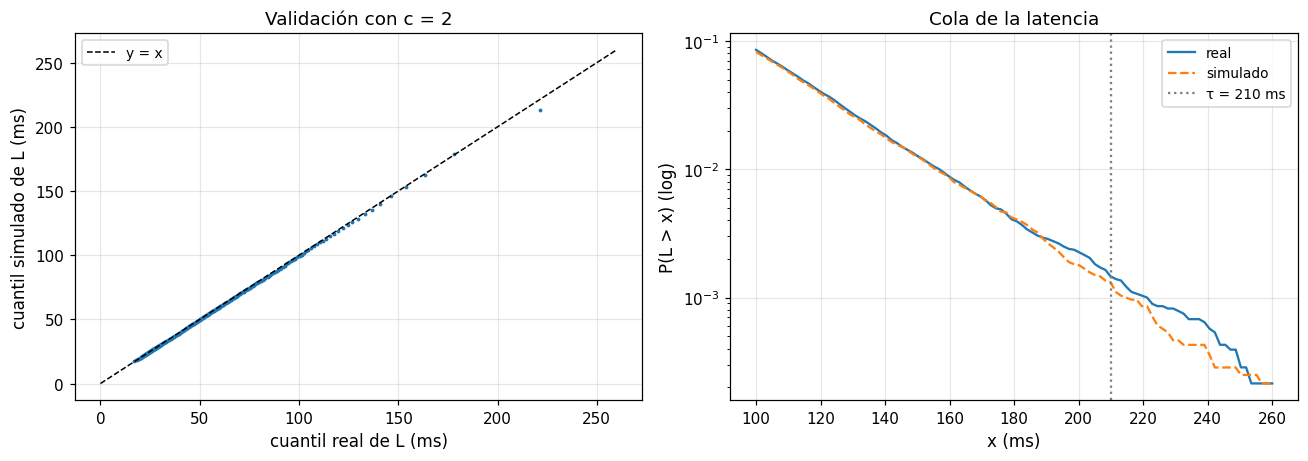

In [ ]:
# Gráfica de apoyo G1: cuantiles de L reales vs simulados (una réplica), con c = c0
qq = np.linspace(0.005, 0.999, 300)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].plot(np.quantile(L_real, qq), np.quantile(L_ks, qq), ".", ms=3)
ax[0].plot([0, 260], [0, 260], "k--", lw=1, label="y = x")
ax[0].set_xlabel("cuantil real de L (ms)"); ax[0].set_ylabel("cuantil simulado de L (ms)"); ax[0].set_title(f"Validación con c = {c0}"); ax[0].legend()
xt = np.linspace(100, 260, 100)
ax[1].semilogy(xt, [(L_real > v).mean() for v in xt], label="real")
ax[1].semilogy(xt, [(L_ks > v).mean() for v in xt], "--", label="simulado")
ax[1].axvline(tau, color="gray", ls=":", label=f"τ = {tau:g} ms"); ax[1].set_xlabel("x (ms)"); ax[1].set_ylabel("P(L > x) (log)")
ax[1].set_title("Cola de la latencia"); ax[1].legend()
plt.tight_layout(); plt.show()

**Conclusión G1.** El simulador, alimentado solo con los modelos de B1, C3, D1 y D3, reproduce el sistema real con $c = 2$: la mediana (48,8 frente a 48,8 ms) y los cuantiles 90, 95, 99 y 99,9 % coinciden con los observados con diferencias menores al 0,7 %; $P(L > \tau)$ simulada (0,15 %) es igual a la real (0,15 % [0,11 %; 0,18 %], 41 violaciones), y también coinciden la fracción de no cacheadas que espera en cola (18,8 % frente a 19,0 %) y la espera media (4,26 frente a 4,24 ms). La distancia máxima entre las funciones de distribución real y simulada es 0,005. **Discrepancias:** son pequeñas y se concentran en el cuantil 99 % (+0,6 %); con un ruido **lognormal paramétrico** en lugar del remuestreado, la cola extrema se sobreestima (cuantil 99,9 % de 230 frente a 221 ms y $P(L > \tau) = 0{,}19$ %), lo que confirma lo visto en C2: la lognormal exagera la cola. Por eso se usa el ruido remuestreado. Otra fuente posible de diferencia es el pequeño salto de nivel entre los dos tramos estables (F2), que el simulador, homogéneo, no incluye.

---
### G2. P(L > τ) con la tasa × g y número de GPUs

**Qué se hace.** Con la tasa de llegadas multiplicada por $g = 2$ se estima $p(c) = P(L > \tau)$ para $c = 1, 2, \dots, 6$ y se busca el menor $c$ que cumple el SLO, $p(c) \le \varepsilon = 0{,}01$.

**Réplicas independientes e intervalos.** Cada réplica simula una ventana de 1200 s (20 min, como los datos) con su propia corriente aleatoria (`rng.spawn`), empezando con el sistema vacío y descartando 60 s de calentamiento. Así las réplicas son **independientes e idénticamente distribuidas**: no comparten números aleatorios ni estado de la cola. Dentro de una réplica las latencias están correlacionadas (F2), así que el estimador de cada réplica es su proporción $\hat p_r$; como las $R$ réplicas son independientes y con la misma distribución, el TLC da el IC $\bar p \pm z\, s_{\hat p}/\sqrt R$.

**Número de réplicas.** Se hace un piloto de 10 réplicas por $c$ y se elige $R$ para que el semiancho del IC sea a lo sumo $\varepsilon/10 = 0{,}001$ en los $c$ cercanos a la frontera del SLO: $R = \lceil (z\, s_{\text{piloto}}/0{,}001)^2\rceil$, con un mínimo de 30.

**Decisión conservadora.** Se exige que el **extremo superior** del IC esté por debajo de $\varepsilon$: así se controla el riesgo de declarar que $c$ GPUs bastan cuando no es cierto.

**Estabilidad.** La carga ofrecida a la GPU es $a = \lambda g\,(1 - \bar c)\,E[X]$ (en GPUs ocupadas en promedio) y la utilización es $\rho = a/c$. Si $\rho \ge 1$ llega más trabajo del que las GPUs pueden hacer y la cola crece sin límite. Se evalúan dos escenarios: con la caché del régimen estable original y con la caché de la ventana de validación (F6), que es más baja y por lo tanto más exigente.

**Uso del archivo de validación en G.** El enunciado permite usar `solicitudes_validacion.csv` solo en F6. Aquí **no se ajusta ni se valida ningún modelo con ese archivo**: la decisión principal ($c^*$ con la caché original) usa solo el régimen estable de `solicitudes.csv`. El segundo escenario solo traslada a G el **hallazgo de F6** (la caché bajó de 0,34 a 0,24), porque F6 pide explícitamente decir "qué implica para la decisión de la Parte G". Es un análisis de sensibilidad, no un reajuste.

In [ ]:
# Paso 1. Carga ofrecida y estabilidad (escenario original y escenario con la caché de validación)
par_val = ajustar_parametros(df_val, T_VENTANA)               # F6: parámetros de la ventana de validación
par_esc = dict(par_est)                                        # escenario desfavorable: todo igual, pero la caché de validación
par_esc["p_cache"] = par_val["p_cache"]
par_esc["c_global"] = par_val["c_global"]

def carga_ofrecida(p, factor):
    return p["lam"] * factor * (1 - p["c_global"]) * p["EX"] / 1000

ESCENARIOS = {"caché original": par_est, "caché de validación (F6)": par_esc}
C_RANGO = list(range(1, 7))
for nombre, p in ESCENARIOS.items():
    a_ = carga_ofrecida(p, g)
    print(f"{nombre:26s}: a = λ·g·(1 - c)·E[X] = {a_:.3f} GPUs | ρ = a/c: " +
          ", ".join(f"c={c_}: {a_ / c_:.2f}" for c_ in C_RANGO) + f"  -> estable si c > {a_:.2f}")

caché original            : a = λ·g·(1 - c)·E[X] = 1.435 GPUs | ρ = a/c: c=1: 1.44, c=2: 0.72, c=3: 0.48, c=4: 0.36, c=5: 0.29, c=6: 0.24  -> estable si c > 1.44
caché de validación (F6)  : a = λ·g·(1 - c)·E[X] = 1.648 GPUs | ρ = a/c: c=1: 1.65, c=2: 0.82, c=3: 0.55, c=4: 0.41, c=5: 0.33, c=6: 0.27  -> estable si c > 1.65


In [ ]:
# Paso 2. Piloto, número de réplicas y estimación de P(L > tau) por c, con IC entre réplicas independientes
T_REP = 1200
def p_violacion(c, p, R_, gen_padre, factor=g):
    return np.array([(simular(c, p, T_REP, g_, factor_lam=factor) > tau).mean() for g_ in gen_padre.spawn(R_)])

R_PILOTO = 10
piloto = {c_: p_violacion(c_, par_est, R_PILOTO, rng) for c_ in C_RANGO}
t_p = z
R_nec = {c_: int(np.ceil((t_p * piloto[c_].std(ddof=1) / (epsilon / 10)) ** 2)) for c_ in C_RANGO}
print("Piloto (10 réplicas): media y DE de P(L > tau) por c")
for c_ in C_RANGO:
    print(f"  c = {c_}: {piloto[c_].mean():.5f} (DE {piloto[c_].std(ddof=1):.5f}) -> réplicas para semiancho 0,001: {R_nec[c_]}")
R_G2 = max(30, max(R_nec[c_] for c_ in C_RANGO if piloto[c_].mean() < 0.5))
print(f"Se usan R = {R_G2} réplicas por c (en c = 1 el sistema es inestable y P(L > tau) ≈ 1 con cualquier R).")

filas_G2, res_G2 = [], {}
for nombre, p in ESCENARIOS.items():
    for c_ in C_RANGO:
        pv = p_violacion(c_, p, R_G2, rng)
        res_G2[(nombre, c_)] = pv
        m_, s_ = pv.mean(), pv.std(ddof=1)
        tq = z                                                 # TLC sobre R_G2 réplicas independientes
        filas_G2.append({"escenario": nombre, "c": c_, "ρ": carga_ofrecida(p, g) / c_, "P(L > τ)": m_,
                         "IC inf": max(m_ - tq * s_ / np.sqrt(R_G2), 0), "IC sup": m_ + tq * s_ / np.sqrt(R_G2)})
tabla_G2 = pd.DataFrame(filas_G2)
tabla_G2["cumple SLO (IC sup ≤ ε)"] = tabla_G2["IC sup"] <= epsilon
with pd.option_context("display.float_format", "{:.5f}".format):
    print(tabla_G2.to_string(index=False))
c_estrella = {n_: int(tabla_G2[(tabla_G2.escenario == n_) & tabla_G2["cumple SLO (IC sup ≤ ε)"]].c.min()) for n_ in ESCENARIOS}
print(f"\nMenor c que cumple el SLO (ε = {epsilon}, IC {nivel_confianza:.0%}): {c_estrella}")

Piloto (10 réplicas): media y DE de P(L > tau) por c
  c = 1: 0.66451 (DE 0.00200) -> réplicas para semiancho 0,001: 11
  c = 2: 0.02510 (DE 0.00214) -> réplicas para semiancho 0,001: 13
  c = 3: 0.00136 (DE 0.00020) -> réplicas para semiancho 0,001: 1
  c = 4: 0.00102 (DE 0.00014) -> réplicas para semiancho 0,001: 1
  c = 5: 0.00097 (DE 0.00009) -> réplicas para semiancho 0,001: 1
  c = 6: 0.00097 (DE 0.00013) -> réplicas para semiancho 0,001: 1
Se usan R = 30 réplicas por c (en c = 1 el sistema es inestable y P(L > tau) ≈ 1 con cualquier R).
               escenario  c       ρ  P(L > τ)  IC inf  IC sup  cumple SLO (IC sup ≤ ε)
          caché original  1 1.43525   0.66427 0.66376 0.66478                    False
          caché original  2 0.71763   0.02600 0.02520 0.02680                    False
          caché original  3 0.47842   0.00137 0.00131 0.00143                     True
          caché original  4 0.35881   0.00105 0.00101 0.00110                     True
          caché

In [ ]:
# Paso 3. Estabilidad en el tiempo: espera media por minuto con c = 1, 2 y 3 (una réplica cada uno)
estab = {}
for c_ in [1, 2, 3]:
    L_, W_, nc_, t_ = simular(c_, par_est, T_REP, rng.spawn(1)[0], factor_lam=g, calentamiento=0, devolver_espera=True)
    minuto = (t_[nc_] // 60000).astype(int)
    estab[c_] = pd.Series(W_[nc_]).groupby(minuto).mean()
    print(f"c = {c_}: espera media en el minuto 1 = {estab[c_].iloc[0]:9.1f} ms | en el minuto 20 = {estab[c_].iloc[-1]:9.1f} ms")

c = 1: espera media en el minuto 1 =   13291.0 ms | en el minuto 20 =  519919.4 ms
c = 2: espera media en el minuto 1 =      31.2 ms | en el minuto 20 =      36.6 ms
c = 3: espera media en el minuto 1 =       3.1 ms | en el minuto 20 =       3.6 ms


---
## FIGURA 9 · Decisión de capacidad (ítem G2)
Izquierda: $P(L > \tau)$ estimada (escala log) con su IC entre réplicas, para cada número de GPUs y los dos escenarios de caché, junto con el SLO $\varepsilon$. Derecha: espera media en cola minuto a minuto con $c = 1, 2, 3$: con $c = 1$ ($\rho > 1$) la cola crece sin límite.

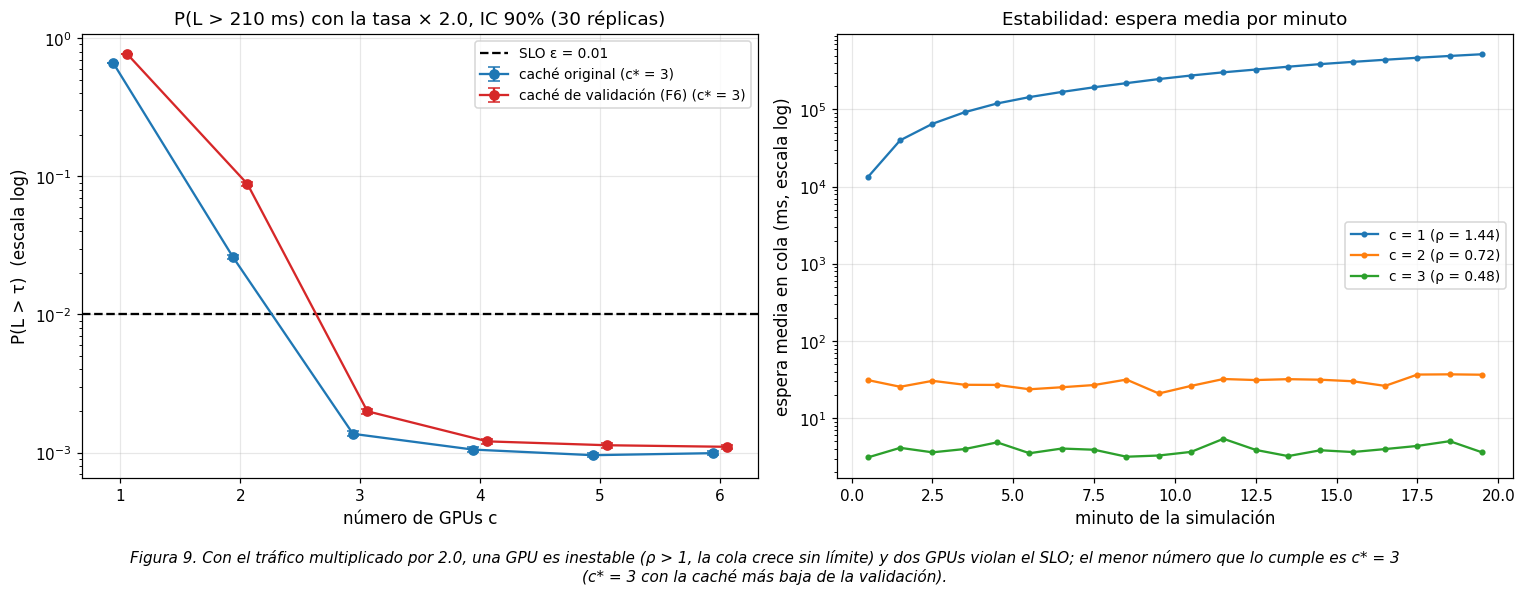

In [ ]:
# =====================================  FIGURA 9  =====================================
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
colores_G = {"caché original": "#1f77b4", "caché de validación (F6)": "#d62728"}
for k_, (nombre, p) in enumerate(ESCENARIOS.items()):
    sub = tabla_G2[tabla_G2.escenario == nombre]
    xs = sub.c + (k_ - 0.5) * 0.12
    y_ = sub["P(L > τ)"].clip(lower=1e-5)
    ax[0].errorbar(xs, y_, yerr=[y_ - sub["IC inf"].clip(lower=1e-5), sub["IC sup"] - y_], fmt="o-", capsize=4,
                   color=colores_G[nombre], label=f"{nombre} (c* = {c_estrella[nombre]})")
ax[0].axhline(epsilon, color="k", ls="--", label=f"SLO ε = {epsilon}")
ax[0].set_yscale("log")
ax[0].set_xlabel("número de GPUs c")
ax[0].set_ylabel("P(L > τ)  (escala log)")
ax[0].set_title(f"P(L > {tau} ms) con la tasa × {g}, IC {nivel_confianza:.0%} ({R_G2} réplicas)")
ax[0].legend(fontsize=9)
for c_, s_ in estab.items():
    ax[1].plot(s_.index + 0.5, s_.values, marker="o", ms=3, label=f"c = {c_} (ρ = {carga_ofrecida(par_est, g) / c_:.2f})")
ax[1].set_yscale("log")
ax[1].set_xlabel("minuto de la simulación")
ax[1].set_ylabel("espera media en cola (ms, escala log)")
ax[1].set_title("Estabilidad: espera media por minuto")
ax[1].legend(fontsize=9)
pie_de_figura(fig, 9, f"Con el tráfico multiplicado por {g}, una GPU es inestable (ρ > 1, la cola crece sin límite) y dos GPUs violan el SLO; "
                      f"el menor número que lo cumple es c* = {c_estrella['caché original']}\n"
                      f"(c* = {c_estrella['caché de validación (F6)']} con la caché más baja de la validación).")
plt.tight_layout()
guardar_figura(fig, 9)
plt.show()

**Conclusión G2.** Con la tasa multiplicada por $g = 2$, la carga ofrecida a la GPU es $a = 1{,}44$ GPUs (1,65 con la caché de la validación). Con **$c = 1$** el sistema es **inestable** ($\rho = 1{,}44$): la espera pasa de ≈ 13 s en el primer minuto a ≈ 9 minutos en el minuto 20, y el 66 % de las solicitudes viola $\tau$ (todas las que van a la GPU). Con **$c = 2$** es estable ($\rho = 0{,}72$), pero $P(L > \tau) = 2{,}60$ % [2,52 %; 2,68 %], 2,6 veces el SLO (8,8 % con la caché de validación). Con **$c = 3$** ($\rho = 0{,}48$), $P(L > \tau) = 0{,}137$ % [0,131 %; 0,143 %] (0,20 % con la caché de validación), muy por debajo de $\varepsilon = 1$ %. Con más GPUs apenas mejora (≈ 0,1 %), porque lo que queda son imágenes muy grandes cuyo propio tiempo de GPU ya supera $\tau$. **El menor número de GPUs que cumple el SLO es $c^* = 3$ en los dos escenarios**, exigiendo que el extremo superior del IC quede bajo $\varepsilon$. Se usaron $R = 30$ réplicas independientes de 20 minutos por $c$ (corrientes aleatorias separadas con `rng.spawn`, sistema vacío al inicio); el piloto pedía 13 en el caso más variable ($c = 2$), así que 30 da semianchos menores que 0,001. **Responde P3.**

---
### G3. Robustez de c* y contraste con un modelo analítico

**Qué se hace.** La respuesta $c^*$ usa parámetros **estimados**. Para ver cuánto depende de esa incertidumbre se propaga por **Montecarlo de remuestreo del sistema completo**:
1. Se remuestrean con reemplazo las solicitudes del régimen estable y se **reajustan todos los modelos** ($\lambda$ con un conteo Poisson, caché por clase, red, recta de MCP y cocientes $\varepsilon$).
2. Con esos parámetros se simula el sistema con la tasa × $g$ para $c = 2, 3, 4$ y se obtiene el menor $c$ que cumple $\hat p(c) \le \varepsilon$.
3. Se repite $B$ veces y se reporta la **distribución de $c^*$** y de $P(L > \tau)$ para cada $c$.

Se hace en los dos escenarios de caché.

**Modelo analítico simplificado de contraste: el sistema sin cola.** Si nunca hubiera espera ($W = 0$, como con infinitas GPUs), $L = \text{red} + G$ y, por **probabilidad total** sobre la caché y el tamaño (semana 3) y la independencia entre red y GPU,
$$P(L > \tau) \approx P_0 = \sum_{\text{clase}} P(\text{clase})\,\big(1 - P(\text{caché}\mid\text{clase})\big)\; P\big(\text{red} + X > \tau \mid \text{clase}\big),$$
$$P(\text{red} + X > \tau \mid \text{tam}) = \int P\!\left(\varepsilon > \frac{\tau - r}{\beta_0 + \beta_1\,\text{tam}}\right) f_{\text{red}}(r)\,dr,$$
con la red normal (C3) y la función de distribución de $\varepsilon$ (D3); la integral se calcula numéricamente en una malla de $r$, sin simular ninguna cola. Junto con la condición de **estabilidad** $\rho = a/c < 1$, da dos predicciones analíticas: $c$ debe ser mayor que $a$, y $P(L > \tau)$ nunca puede bajar de $P_0$. La diferencia entre la simulación y $P_0$ es exactamente **el efecto de la cola**.

In [ ]:
# Paso 1. Propagación de la incertidumbre de los parámetros hasta c*
B_G3, R_G3, T_G3 = 100, 4, 1200
def remuestrear_parametros(d, T_, gen):
    d_b = d.iloc[gen.integers(0, len(d), len(d))]
    p = ajustar_parametros(d_b, T_)
    p["lam"] = gen.poisson(len(d)) / T_                        # incertidumbre de lambda (conteo Poisson)
    return p

def c_estrella_de(p, gen):
    pv = {}
    for c_ in [2, 3, 4]:
        pv[c_] = np.mean([(simular(c_, p, T_G3, g_, factor_lam=g) > tau).mean() for g_ in gen.spawn(R_G3)])
        if pv[c_] <= epsilon:
            return c_, pv
    return 5, pv

dist_G3 = {}
for nombre, (d_base, T_base) in {"caché original": (df_estable, T_EST_G), "caché de validación (F6)": (df_val, T_VENTANA)}.items():
    filas = []
    for gen_b in rng.spawn(B_G3):
        p_b = remuestrear_parametros(df_estable, T_EST_G, gen_b)
        if nombre != "caché original":                         # escenario desfavorable: caché remuestreada de la validación
            p_v = ajustar_parametros(d_base.iloc[gen_b.integers(0, len(d_base), len(d_base))], T_base)
            p_b["p_cache"], p_b["c_global"] = p_v["p_cache"], p_v["c_global"]
        c_b, pv_b = c_estrella_de(p_b, gen_b)
        filas.append({"c*": c_b, "a": carga_ofrecida(p_b, g), **{f"P(L>τ) c={k}": v for k, v in pv_b.items()}})
    dist_G3[nombre] = pd.DataFrame(filas)
    df_ = dist_G3[nombre]
    print(f"{nombre}: B = {B_G3} remuestreos")
    print("  distribución de c*:", df_["c*"].value_counts(normalize=True).sort_index().round(3).to_dict())
    print(f"  carga a: media {df_.a.mean():.3f}, IC {nivel_confianza:.0%} [{df_.a.quantile(alpha / 2):.3f}, {df_.a.quantile(1 - alpha / 2):.3f}]")
    for k in (2, 3):
        col = f"P(L>τ) c={k}"
        if col in df_:
            print(f"  {col}: mediana {df_[col].median():.4f}, IC {nivel_confianza:.0%} [{df_[col].quantile(alpha / 2):.4f}, {df_[col].quantile(1 - alpha / 2):.4f}]")

caché original: B = 100 remuestreos
  distribución de c*: {3: 1.0}
  carga a: media 1.435, IC 90% [1.415, 1.454]
  P(L>τ) c=2: mediana 0.0254, IC 90% [0.0213, 0.0306]
  P(L>τ) c=3: mediana 0.0014, IC 90% [0.0012, 0.0015]
caché de validación (F6): B = 100 remuestreos
  distribución de c*: {3: 1.0}
  carga a: media 1.647, IC 90% [1.630, 1.669]
  P(L>τ) c=2: mediana 0.0892, IC 90% [0.0773, 0.1047]
  P(L>τ) c=3: mediana 0.0019, IC 90% [0.0016, 0.0022]


In [ ]:
# Paso 2. Modelo analítico simplificado: sistema sin cola (probabilidad total) + condición de estabilidad
eps_ord = np.sort(par_est["eps"])
def cola_eps(u):                                                # P(eps > u) con la distribución de eps (D3)
    return 1 - np.searchsorted(eps_ord, u, side="right") / len(eps_ord)
def p_sin_cola(p):
    r_malla = np.linspace(p["red"][0] - 6 * p["red"][1], p["red"][0] + 6 * p["red"][1], 241)
    w_r = stats.norm.pdf(r_malla, *p["red"]); w_r /= w_r.sum()    # pesos de la densidad normal de la red
    tam_u = np.quantile(p["tam"], (np.arange(2000) + 0.5) / 2000) # 2000 cuantiles del tamaño (cada uno con prob. 1/2000)
    mu_t = p["beta"][0] + p["beta"][1] * tam_u
    p_nc = 1 - p["p_cache"][np.digitize(tam_u, FRONTERAS)]
    P_tam = np.array([np.sum(w_r * cola_eps((tau - r_malla) / m_)) for m_ in mu_t])
    return np.mean(p_nc * P_tam)
filas = []
for nombre, p in ESCENARIOS.items():
    P0 = p_sin_cola(p); a_ = carga_ofrecida(p, g)
    for c_ in C_RANGO:
        sim_ = tabla_G2[(tabla_G2.escenario == nombre) & (tabla_G2.c == c_)]["P(L > τ)"].iloc[0]
        filas.append({"escenario": nombre, "c": c_, "ρ = a/c": a_ / c_, "estable": a_ / c_ < 1, "P0 sin cola (analítico)": P0,
                      "P(L>τ) simulación": sim_, "efecto de la cola": sim_ - P0})
tabla_analitica = pd.DataFrame(filas)
with pd.option_context("display.float_format", "{:.5f}".format):
    print(tabla_analitica.to_string(index=False))
P0_real = (df_estable.red_ms + df_estable.gpu_ms > tau).mean()
print(f"\nComprobación con los datos reales: fracción con red + G > tau = {P0_real:.5f} vs P0 analítico = {p_sin_cola(par_est):.5f}")
c_analitico = {n_: int(np.floor(carga_ofrecida(p, g))) + 1 for n_, p in ESCENARIOS.items()}
print(f"Mínimo c estable (c > a): {c_analitico} | c* de la simulación: {c_estrella}")

               escenario  c  ρ = a/c  estable  P0 sin cola (analítico)  P(L>τ) simulación  efecto de la cola
          caché original  1  1.43525    False                  0.00098            0.66427            0.66329
          caché original  2  0.71763     True                  0.00098            0.02600            0.02502
          caché original  3  0.47842     True                  0.00098            0.00137            0.00039
          caché original  4  0.35881     True                  0.00098            0.00105            0.00007
          caché original  5  0.28705     True                  0.00098            0.00096           -0.00002
          caché original  6  0.23921     True                  0.00098            0.00099            0.00001
caché de validación (F6)  1  1.64756    False                  0.00109            0.76398            0.76288
caché de validación (F6)  2  0.82378     True                  0.00109            0.08798            0.08688
caché de validación

**Conclusión G3.** Al propagar la incertidumbre de **todos** los parámetros (remuestreo de las solicitudes, reajuste de todos los modelos y simulación del sistema en cada remuestreo), **$c^* = 3$ en el 100 % de los 100 remuestreos**, en los dos escenarios de caché. La razón es el margen: la carga $a$ apenas varía (IC 90 % [1,42; 1,45], o [1,63; 1,67] con la caché de validación) porque se estima con miles de solicitudes; con $c = 2$, $P(L > \tau)$ queda siempre muy por encima de $\varepsilon$ (IC 90 % [2,1 %; 3,1 %], o [7,7 %; 10,5 %]) y con $c = 3$ siempre muy por debajo ([0,12 %; 0,15 %], o [0,16 %; 0,22 %]). La decisión es **robusta a la incertidumbre de estimación**. Lo que sí podría cambiarla es un error de **modelo**: un crecimiento mayor que $g$ (con $c = 3$ el límite de estabilidad es $a = 3$, un crecimiento ≈ 4 veces la tasa actual), ráfagas como la de A2 o una caché todavía más baja.

**Contraste analítico.** El modelo sin cola y la condición de estabilidad explican la forma de la curva de la Figura 9: (1) con $c = 1$, $\rho > 1$ y el sistema colapsa, como predice la estabilidad; (2) desde $c = 4$ la simulación queda prácticamente en el piso $P_0 \approx 0{,}10$ % (con $c = 3$, apenas 0,04 puntos por encima), y ese piso es parecido a la fracción real de solicitudes con red + GPU > $\tau$ (0,12 %): ahí las violaciones no se deben a la cola sino a imágenes muy grandes, y **ninguna cantidad de GPUs las elimina**; (3) con $c = 2$ la simulación queda 2,5 puntos por encima de $P_0$: esa diferencia es el efecto de la cola, que el modelo simplificado no puede capturar porque ignora la espera. Por eso hace falta el simulador: el modelo analítico da la cota inferior y el mínimo $c$ estable ($c > a$, es decir $c \ge 2$), pero solo la simulación muestra que $c = 2$ todavía no basta. **Responde P3.**

---
### G4. Memorando ejecutivo
El memorando de una página dirigido al CTO se entrega aparte en PDF (`Memorando_ejecutivo_Grupo2.pdf`). La celda siguiente imprime las cifras que usa, calculadas en este notebook, para que el memorando y el código sean coherentes.

In [ ]:
# Cifras del memorando (todas calculadas arriba)
sub_o = tabla_G2[tabla_G2.escenario == "caché original"].set_index("c")
sub_v = tabla_G2[tabla_G2.escenario == "caché de validación (F6)"].set_index("c")
print(f"P1  tasa de llegadas: {texto_ic(lam_hat, *ic_normal(lam_hat, np.sqrt(lam_hat / T_EST)), 'TLC', 2)} sol/s")
print(f"P1  latencia media: {texto_ic(media_L, *IC_LAT, 'TLC, lotes', 2)} ms | P(L > tau) hoy = {(df_estable.latencia_ms > tau).mean():.4f}")
print(f"P1  P(caché) original = {df_estable.cache_hit.mean():.3f}, validación = {df_val.cache_hit.mean():.3f}")
print(f"P2  B - A en GPU: {dif1:.2f} ms [{dif1 - z_bonf * ee1:.2f}; {dif1 + z_bonf * ee1:.2f}] ({100 * dif1 / xA_gpu.mean():.1f} %)")
for c_ in (2, 3):
    print(f"P3  c = {c_}: P(L > tau) = {sub_o.loc[c_, 'P(L > τ)']:.4f} [{sub_o.loc[c_, 'IC inf']:.4f}; {sub_o.loc[c_, 'IC sup']:.4f}] | "
          f"con caché de validación {sub_v.loc[c_, 'P(L > τ)']:.4f}")
print(f"P3  c* = {c_estrella} | distribución de c* (G3): " + "; ".join(f"{k}: {v['c*'].value_counts(normalize=True).round(2).to_dict()}" for k, v in dist_G3.items()))
print(f"P3  regla de alertas 'D1 y D2': {MIN_DIA * (1 - pi_incidentes) * TFP['D1 y D2']:.1f} falsas/día, VPP = {vpp(SENS['D1 y D2'], TFP['D1 y D2'], pi_incidentes):.2f}, "
      f"sensibilidad = {SENS['D1 y D2']:.2f}, P(cumple) = {tabla_E4.loc['D1 y D2', 'P(la regla cumple)']:.2f}")

P1  tasa de llegadas: 27.56  [27.29; 27.83]  (IC 90%, TLC) sol/s
P1  latencia media: 54.46  [54.04; 54.88]  (IC 90%, TLC, lotes) ms | P(L > tau) hoy = 0.0015
P1  P(caché) original = 0.336, validación = 0.238
P2  B - A en GPU: -2.37 ms [-3.17; -1.56] (-5.9 %)
P3  c = 2: P(L > tau) = 0.0260 [0.0252; 0.0268] | con caché de validación 0.0880
P3  c = 3: P(L > tau) = 0.0014 [0.0013; 0.0014] | con caché de validación 0.0020
P3  c* = {'caché original': 3, 'caché de validación (F6)': 3} | distribución de c* (G3): caché original: {3: 1.0}; caché de validación (F6): {3: 1.0}
P3  regla de alertas 'D1 y D2': 2.9 falsas/día, VPP = 0.58, sensibilidad = 0.69, P(cumple) = 0.69


---
# Parte H — Respuestas a P1, P2 y P3
**reúne en una tabla las cifras que responden cada pregunta**, con el ítem donde se calcularon.


In [ ]:
# Tabla de evidencia: cada fila es una afirmación, su cifra y el ítem donde se calculó
def ic_txt(est, li, ls, d=3):
    return f"{est:.{d}f} [{li:.{d}f}; {ls:.{d}f}]"
k_tau = int((df_estable.latencia_ms > tau).sum())
sub_o = tabla_G2[tabla_G2.escenario == "caché original"].set_index("c")
sub_v = tabla_G2[tabla_G2.escenario == "caché de validación (F6)"].set_index("c")
ev = [
 ("P1", "Hay una ráfaga que se excluye", f"{INI}–{FIN} s; var/media de conteos de 10 s = {conteos.var(ddof=1) / conteos.mean():.1f} (Poisson ≈ 1)", "A2"),
 ("P1", "Llegadas del régimen estable: Poisson", f"λ = {ic_txt(lam_hat, *ic_normal(lam_hat, np.sqrt(lam_hat / T_EST)), 2)} sol/s; CV entre llegadas ≈ 1", "B1"),
 ("P1", "Reintentos: Binomial / geométrica truncada", f"P(intentos>1) estable ≈ 0,21; q por máx. verosimilitud = {q_hat:.4f}", "B2, B3"),
 ("P1", "G es mixta (masa en 0 + continua)", f"P(G = 0) = {c_hat:.3f}; E[G] = (1-c)m = {EG_teo:.2f} ms", "C1"),
 ("P1", "Parte continua de G: lognormal (mejor que gamma)", f"log-ver. lognormal {modelos_C2['lognormal (máx. ver.)'].logpdf(X_gpu).sum():.0f} vs gamma {modelos_C2['gamma (máx. ver.)'].logpdf(X_gpu).sum():.0f}", "C2"),
 ("P1", "Red: normal", f"N({mu_r:.2f}; {sig_r:.2f}²); percentil 99,9 % = {q999_mod:.2f} ms", "C3"),
 ("P1", "Tamaño y caché dependientes", f"P(caché|pequeña) = {p_cache_clase['pequeña'][0] / p_cache_clase['pequeña'][1]:.2f} vs grande = {p_cache_clase['grande'][0] / p_cache_clase['grande'][1]:.2f}", "D1"),
 ("P1", "GPU lineal en el tamaño, ruido multiplicativo", f"E[G|tam, no caché] = {beta_mcp[0]:.2f} + {beta_mcp[1]:.4f}·tam; CV ≈ {np.sqrt(phi_mcp):.2f}", "D3"),
 ("P1", "Confiabilidad de las cifras: n ≥ 30 no basta", f"intervalo normal cubre 0,89 solo desde n* = {n_estrella}", "F1"),
 ("P1", "Latencia media (con dependencia corregida)", f"{ic_txt(media_L, *IC_LAT, 2)} ms (clásico más estrecho)", "F2"),
 ("P1", "Hoy se cumple el SLO", f"P(L > τ) = {texto_ic(k_tau / len(df_estable), *ic_proporcion(k_tau, len(df_estable)), 'TLC', 4)} ≪ ε = {epsilon}", "A3, F3"),
 ("P1", "La caché cambió en la validación", f"P(caché) {df_estable.cache_hit.mean():.3f} → {df_val.cache_hit.mean():.3f}; carga de GPU +{100 * (a_v / a_o - 1):.0f} %", "F6"),
 ("P2", "Grupos A y B comparables", f"máx |dif. estandarizada| = {tabla_bal['dif. estandarizada'].abs().max():.3f} (< 0,1)", "F3"),
 ("P2", "B reduce el tiempo de GPU", f"Δ = {dif1:.2f} ms [{dif1 - z_bonf * ee1:.2f}; {dif1 + z_bonf * ee1:.2f}] ({100 * dif1 / xA_gpu.mean():.1f} %), simultáneo", "F3"),
 ("P2", "B no cambia los reintentos", f"Δ = {dif2:.4f} [{dif2 - z_bonf * ee2:.4f}; {dif2 + z_bonf * ee2:.4f}]", "F3"),
 ("P2", "B no cambia las violaciones de τ", f"Δ = {dif3:.5f} [{dif3 - z_bonf * ee3:.5f}; {dif3 + z_bonf * ee3:.5f}]", "F3"),
 ("P2", "La mejora de B se repite en la validación", f"Δ GPU validación = {dvv:.2f} ms", "F6"),
 ("P3", "Con g = 2, 1 GPU es inestable", f"ρ = a/1 = {carga_ofrecida(par_est, g):.2f} > 1", "G2"),
 ("P3", "Con g = 2, 2 GPUs no cumplen", f"P(L>τ) = {sub_o.loc[2, 'P(L > τ)']:.4f} [{sub_o.loc[2, 'IC inf']:.4f}; {sub_o.loc[2, 'IC sup']:.4f}] > ε", "G2"),
 ("P3", "Con g = 2, 3 GPUs cumplen", f"P(L>τ) = {sub_o.loc[3, 'P(L > τ)']:.4f} [{sub_o.loc[3, 'IC inf']:.4f}; {sub_o.loc[3, 'IC sup']:.4f}]; caché de validación {sub_v.loc[3, 'P(L > τ)']:.4f}", "G2"),
 ("P3", "c* robusto a la incertidumbre", "; ".join(f"{k}: {v['c*'].value_counts(normalize=True).round(2).to_dict()}" for k, v in dist_G3.items()), "G3"),
 ("P3", "Piso analítico sin cola", f"P0 = {p_sin_cola(par_est):.4f}: ninguna cantidad de GPUs baja de ahí", "G3"),
 ("P3", "Alertas: VPP en producción bajo", f"D1 {vpp(SENS['D1'], TFP['D1'], pi_incidentes):.2f}; D1 y D2 {vpp(SENS['D1 y D2'], TFP['D1 y D2'], pi_incidentes):.2f}", "E2"),
 ("P3", "D1 y D2 NO son condicionalmente independientes", f"sin incidente coinciden {COC['normal (I = 0)']:.0f} veces más que si lo fueran", "E3"),
 ("P3", "Regla recomendada: 'D1 y D2'", f"{MIN_DIA * (1 - pi_incidentes) * TFP['D1 y D2']:.1f} falsas/día; P(X ≤ {k_max}) = {float(p_cumple(TFP['D1 y D2'])):.3f}; cumple con prob. {tabla_E4.loc['D1 y D2', 'P(la regla cumple)']:.2f}", "E4"),
]
tabla_H = pd.DataFrame(ev, columns=["pregunta", "afirmación", "cifra (IC 90 %)", "ítem"])
with pd.option_context("display.max_colwidth", 120, "display.width", 250):
    print(tabla_H.to_string(index=False))
tabla_H.to_csv("H_tabla_evidencia.csv", index=False)

pregunta                                       afirmación                                                 cifra (IC 90 %)   ítem
      P1                    Hay una ráfaga que se excluye    370–555 s; var/media de conteos de 10 s = 44.7 (Poisson ≈ 1)     A2
      P1            Llegadas del régimen estable: Poisson           λ = 27.56 [27.29; 27.83] sol/s; CV entre llegadas ≈ 1     B1
      P1       Reintentos: Binomial / geométrica truncada P(intentos>1) estable ≈ 0,21; q por máx. verosimilitud = 0.2119 B2, B3
      P1                G es mixta (masa en 0 + continua)                      P(G = 0) = 0.336; E[G] = (1-c)m = 26.04 ms     C1
      P1 Parte continua de G: lognormal (mejor que gamma)                       log-ver. lognormal -82153 vs gamma -82502     C2
      P1                                      Red: normal                    N(25.60; 3.87²); percentil 99,9 % = 37.56 ms     C3
      P1                      Tamaño y caché dependientes                        P(caché|pequeña)

### Respuestas breves
**P1. ¿Cómo se comporta el servicio y qué tan confiables son las cifras?** Fuera de una ráfaga (370–555 s), las llegadas son un proceso de **Poisson** (≈ 27,6 sol/s), los reintentos siguen una **binomial/geométrica** con fallo por intento $q \approx 0{,}21$, el tiempo de GPU es una variable **mixta** (masa en 0 por la caché y parte continua aproximadamente **lognormal**, que crece **linealmente con el tamaño** con ruido multiplicativo) y la red es **normal**. El tamaño y la caché **no son independientes**. Las cifras son confiables **si se tiene en cuenta cómo se obtuvieron**: (i) con poblaciones asimétricas, el TLC necesita $n \approx 80$, no 30 (F1); (ii) las latencias consecutivas están correlacionadas, así que el intervalo clásico es demasiado estrecho y se corrige (F2); (iii) los intervalos de Wald para proporciones solo valen si $np \ge 10$ (F4), lo que se revisó en cada uso; (iv) la caché cambió entre ventanas (F6), así que algunas cifras no se trasladan a otro periodo.

**P2. ¿La versión B es mejor?** **Sí, en lo que importa para la capacidad**: reduce el tiempo medio de GPU ≈ 6 % (intervalo simultáneo lejos de 0) y no se detecta que empeore los reintentos ni el SLO. Los grupos son comparables (asignación aleatoria verificada), el efecto no se debe al tamaño de las imágenes (ajuste por tamaño) y se repite en la validación. **Se recomienda adoptarla.**

**P3. ¿Cuántas GPUs y qué alertas?** Con el tráfico duplicado ($g = 2$) se necesitan **3 GPUs**: con 1 el sistema es inestable y con 2 se viola el SLO; con 3 $P(L > \tau) \approx 0{,}1$–$0{,}2$ %, y la decisión no cambia al propagar la incertidumbre de los parámetros ni con la caché más baja de la validación. **Alertas:** despertar al equipo solo con **"D1 y D2"** (≈ 3 falsas alarmas/día, única regla que cumple la exigencia de guardia, VPP ≈ 0,58), dejando D1 sola como aviso de baja prioridad, porque "D1 y D2" pierde ≈ 31 % de los incidentes.


---
### Supuestos y limitaciones
1. **Régimen estable.** Todo B–F usa el tramo sin ráfaga. El dimensionamiento de G supone crecimiento **uniforme** ($\lambda \times g$), sin ráfagas como la de 370–555 s.
2. **Independencia entre solicitudes.** Se verificó para llegadas, reintentos y tiempos de GPU consecutivos; **no** se cumple para latencias consecutivas (cola compartida), y se corrigió (F2).
3. **Modelos aproximados.** La lognormal de la GPU y la normal de la red son aproximaciones buenas pero no exactas; el simulador usa el modelo condicional de D3 con el ruido remuestreado, que puede subestimar levemente la cola extrema (G1).
4. **Aproximación normal en los intervalos.** Todos los intervalos usan el TLC; se revisó $np \ge 10$ en las proporciones y $n \ge n^*$ en las medias, y donde el TLC no aplica (cuantiles, VPP, $c^*$) se usó Montecarlo.
5. **Detectores.** Se supone que en producción tienen la misma sensibilidad y TFP que en el entorno de pruebas. La regla recomendada se basa en solo 11 falsas alarmas observadas.
6. **No estacionariedad entre ventanas.** La caché bajó en la validación (F6); la recomendación de capacidad se evaluó también en ese escenario.
7. **Reintentos.** Se supone que no agregan carga a la GPU, como muestran los datos (G1).